# Image Captioning: 75 saved models and four new depth experiments

All preparation, model, training, evaluation and transfer code stays in this notebook. The existing **75 completed experiments are preserved**. The plan now contains **79 runs**, including four new ResNet50 experiments: LSTM with 3 or 4 layers and the causal image-prefix Transformer with 3 or 4 layers.

**Default selection:** `LAPTOP_ID="A"`, `TRAIN_DECODERS=["lstm", "transformer"]`, `TRAIN_VARIANTS=["depth_3", "depth_4"]`. This selects exactly four new runs. Keep `TRAINING_ONLY=True` to reuse the existing global CNN vectors. No image feature extraction is needed.

Open Jupyter beside this notebook using the CUDA environment. `RUN_TRAINING=False` and `RUN_FINAL_TEST=False` keep Run All in review mode. When ready, change only the existing `RUN_TRAINING` switch to True and Run All. Existing results remain available for comparison. Training runs a preflight check and creates a fresh model for each new experiment.

Results remain in `experiments/all_encoders_v5_100epochs`, with new names such as `resnet50_lstm_depth_3_seed42`. Every run saves best/last full checkpoints, plain weights, optimizer/scaler/RNG state, configuration, history and validation predictions. Timers and devices are recorded. Interrupted runs resume from `last.pt` with the same settings.

B8 shows the full 79-run table, completed winners and a separate 1/2/3/4-layer ResNet50 comparison. The original controls are `baseline` (1 layer) and `stacked` (2 layers). Scores for new runs remain blank until training. B9 plots the best completed model in each decoder family.

Only depth changes in this experiment. The Transformer keeps its global image prefix and causal self-attention; spatial attention and cross-attention are separate future experiments. Select models using validation CIDEr-D and reserve the labeled test for later. Save this one notebook with the combined outputs for submission.


## A1. Imports
All imports are collected here. Restart the kernel before Run All so the CUDA reproducibility setting is applied before CUDA initializes.

In [1]:
import os

os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

import io
import json
import pickle
import random
import re
import time
import hashlib
import unicodedata
import textwrap
from pathlib import Path
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime, timezone
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageFile
import torch
import torch.nn as nn
import torchvision
from torch.utils.data import Dataset, DataLoader, Subset
from torch.nn.utils.rnn import pad_sequence
from torchvision import transforms
from torchvision.models import (
    resnet50,
    ResNet50_Weights,
    resnet18,
    ResNet18_Weights,
    vgg19,
    VGG19_Weights,
)
import csv
import inspect
import importlib.metadata as package_metadata
from functools import partial
from IPython.display import display, Markdown
from pycocoevalcap.bleu.bleu import Bleu
from pycocoevalcap.bleu.bleu_scorer import BleuScorer
from pycocoevalcap.cider.cider import Cider
from pycocoevalcap.cider.cider_scorer import CiderScorer

from torchvision.models import (
    mobilenet_v2,
    MobileNet_V2_Weights,
    efficientnet_v2_s,
    EfficientNet_V2_S_Weights,
)

import shutil
import tempfile
import zipfile


## Settings

- Adam learning rate 0.001, batch size 64, maximum 100 epochs, early-stopping patience 3 on validation CIDEr-D, gradient clipping 5.0 and seed 42.
- One random human caption per training image per epoch; a fixed caption for validation loss; all original human references for metrics.
- A's default decoder and variant filters select only four new ResNet50 runs. `TRAIN_VARIANTS=None` includes every assigned variant for the selected decoders. B's original work uses `LAPTOP_ID="B"`, `TRAIN_DECODERS=["rnn", "lstm"]` and `TRAIN_VARIANTS=None`.
- Width and word embeddings stay 512. Dropout stays 0.3. LSTM built-in recurrent dropout stays zero. Transformer keeps 8 heads, feed-forward width 2048 and pre-normalization.
- `TRAINING_ONLY=True` reuses prepared data and global CNN vectors. `RUN_TRAINING=True` starts or resumes the selected experiments. These are different switches: keep both lines.
- Keep existing training settings unchanged for this result group. A different protocol requires separately named configurations. `RESULTS_ROOT` and `TRANSFER_DIR` may point to another drive.
- Test stays unused during selection. Device differences affect timing comparisons.


In [2]:
PROJECT_DIR = Path.cwd()
DATA_ROOT = PROJECT_DIR / "data" / "coco2017"
if not (DATA_ROOT / "annotations" / "captions_train2017.json").exists():
    DATA_ROOT = Path.home() / "Downloads" / "MSCOCO" / "coco2017"

# A runs the four new depth experiments. B keeps its original 25 assignments.
LAPTOP_ID = "A"
TRAIN_DECODERS = ["lstm", "transformer"]
TRAIN_VARIANTS = ["depth_3", "depth_4"]  # None selects all assigned variants.
TRAINING_ONLY = True  # Load the prepared data and cached CNN vectors.
RUN_PREFLIGHT = False
RUN_TRAINING = True  # Start/resume the selected decoder experiments.
RUN_FINAL_TEST = False
RESULTS_ROOT = PROJECT_DIR / "experiments"
TRANSFER_DIR = PROJECT_DIR / "transfer"
CACHE_DIR = PROJECT_DIR / "cache"
CACHE_DIR.mkdir(exist_ok=True)
SEED = 42
HOLDOUT_SIZE = 5000
BATCH_SIZE = 64
FEATURE_BATCH_SIZE = 64
IMAGE_SIZE = 224
MAX_CONTENT_TOKENS = 32
CHECK_WORKERS = 8
FORCE_IMAGE_CHECK = False
FORCE_TEXT_PREP = False
FORCE_FEATURES = False
TRAIN_ENCODER = "resnet50"
RUN_EXTRA_ENCODERS = True
MODELS_TO_EXTRACT = ["resnet18", "vgg19", "mobilenet_v2", "efficientnet_v2_s"]
NEW_ENCODER_SETTINGS = {
    "resnet18": {
        "builder": resnet18,
        "weights": ResNet18_Weights.IMAGENET1K_V1,
        "dim": 512,
        "batch_size": 64,
    },
    "vgg19": {
        "builder": vgg19,
        "weights": VGG19_Weights.IMAGENET1K_V1,
        "dim": 4096,
        "batch_size": 32,
    },
    "mobilenet_v2": {
        "builder": mobilenet_v2,
        "weights": MobileNet_V2_Weights.IMAGENET1K_V2,
        "dim": 1280,
        "batch_size": 64,
    },
    "efficientnet_v2_s": {
        "builder": efficientnet_v2_s,
        "weights": EfficientNet_V2_S_Weights.IMAGENET1K_V1,
        "dim": 1280,
        "batch_size": 32,
    },
}
FEATURE_DIMS = {
    "resnet50": 2048,
    "resnet18": 512,
    "vgg19": 4096,
    "mobilenet_v2": 1280,
    "efficientnet_v2_s": 1280,
}
assert TRAIN_ENCODER in FEATURE_DIMS, "Choose an encoder listed in FEATURE_DIMS."
assert set(MODELS_TO_EXTRACT) <= set(NEW_ENCODER_SETTINGS), "Unsupported extraction model."
NORM_MEAN = (0.485, 0.456, 0.406)
NORM_STD = (0.229, 0.224, 0.225)
PAD_COLOR = tuple(round(value * 255) for value in NORM_MEAN)
ANNOTATION_FILES = {
    "train2017": "captions_train2017.json",
    "val2017": "captions_val2017.json",
    "test2017": "image_info_test2017.json",
}
TEXT_SETTINGS = {
    "version": 1,
    "min_frequency": 5,
    "max_vocab_tokens": 10000,
    "special_tokens": ["<pad>", "<unk>", "<start>", "<end>"],
    "token_pattern": r"[^\W_]+(?:'[^\W_]+)*|[^\w\s]",
}
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
ImageFile.LOAD_TRUNCATED_IMAGES = False
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cuda":
    torch.cuda.manual_seed_all(SEED)
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("CPU: feature extraction will be slower.")
print("PyTorch:", torch.__version__)

# One experiment group for the shared 79-experiment comparison. Older runs stay untouched.
RUN_GROUP = "all_encoders_v5_100epochs"
EXPERIMENT_DIR = RESULTS_ROOT / RUN_GROUP

LEARNING_RATE = 0.001
MAX_EPOCHS = 100
PATIENCE = 3
TRAIN_SEED = 42

# Model/checkpoint compatibility IDs stay unchanged: new configurations reuse the same model and training code.
IMPLEMENTATION_ID = "4999171d257bc83ebef0d7c6126b51135172373308b4fd9d66985e71de661475"

TRANSFORMER_IMPLEMENTATION_ID = "097d3721f9bfe2111d91345835f0cfab782ed5f1bd9a52d3263ab945cb00cc91"


GPU: NVIDIA GeForce RTX 4060 Laptop GPU
PyTorch: 2.13.0+cu126


### File transfer helpers

These functions only define archive creation and verification; no files are copied until you use the final transfer section. Training archives contain prepared captions, original references and cached vectors. Results archives contain complete experiment folders. Only load archives/checkpoints shared by your project partner.


In [3]:
def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(8 * 1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def bundle_path(root, relative_name):
    # ZIP paths must stay inside the selected project or experiment folder.
    if "\\" in relative_name or ":" in relative_name:
        raise ValueError(f"Invalid archive path: {relative_name}")
    parts = relative_name.split("/")
    if any(part in {"", ".", ".."} for part in parts):
        raise ValueError(f"Invalid archive path: {relative_name}")
    root = Path(root).resolve()
    path = root.joinpath(*parts).resolve()
    if not path.is_relative_to(root):
        raise ValueError(f"Archive path leaves its destination: {relative_name}")
    return path


def write_bundle(archive_path, files, details, dry_run=False):
    archive_path = Path(archive_path)
    archive_path.parent.mkdir(parents=True, exist_ok=True)
    if archive_path.exists():
        raise FileExistsError(f"Archive already exists; choose a new name: {archive_path}")
    total_bytes = sum(path.stat().st_size for path in files.values())
    needed = total_bytes + 100 * 1024**2
    estimate = {
        "files": len(files),
        "uncompressed_gib": total_bytes / 1024**3,
        "free_gib": shutil.disk_usage(archive_path.parent).free / 1024**3,
    }
    print(
        f"Bundle: {len(files)} files, {estimate['uncompressed_gib']:.2f} GiB before compression; "
        f"{estimate['free_gib']:.2f} GiB free at the destination."
    )
    if dry_run:
        return estimate
    if shutil.disk_usage(archive_path.parent).free < needed:
        raise OSError(f"Need about {needed / 1024**3:.2f} GiB free to create this archive.")
    temporary = archive_path.with_suffix(archive_path.suffix + ".partial")
    started = time.perf_counter()
    manifest = {"format_version": 1, **details, "files": {}}

    # Fast compression reduces transfer size; ZIP64 supports archives larger than 4 GiB.
    with zipfile.ZipFile(
        temporary, "w", compression=zipfile.ZIP_DEFLATED, compresslevel=1, allowZip64=True
    ) as archive:
        for name, path in sorted(files.items()):
            bundle_path(archive_path.parent, name)
            digest = hashlib.sha256()
            size = 0
            with path.open("rb") as source, archive.open(name, "w", force_zip64=True) as target:
                for block in iter(lambda: source.read(8 * 1024 * 1024), b""):
                    target.write(block)
                    digest.update(block)
                    size += len(block)
            manifest["files"][name] = {"bytes": size, "sha256": digest.hexdigest()}
        archive.writestr("bundle_manifest.json", json.dumps(manifest, indent=2))
    temporary.replace(archive_path)
    elapsed = time.perf_counter() - started
    result = {
        "archive": str(archive_path),
        "files": len(files),
        "size_gib": archive_path.stat().st_size / 1024**3,
        "seconds": elapsed,
    }
    print(f"Saved {len(files)} files, {result['size_gib']:.2f} GiB, {elapsed:.1f}s: {archive_path}")
    return result


def build_training_bundle(data, archive_path, dry_run=False):
    project_dir = data["project_dir"]
    files = {}
    for name in [
        "splits.json",
        "prepared.pkl",
        "text_report.json",
        "vocab.json",
        "image_audit.json",
        "test_captions.json",
    ]:
        files[f"cache/{name}"] = project_dir / "cache" / name
    for source in ["train2017", "val2017"]:
        name = f"captions_{source}.json"
        files[f"data/coco2017/annotations/{name}"] = data["data_root"] / "annotations" / name
    for encoder, sources in data["feature_files"].items():
        for source, entry in sources.items():
            path = entry["path"]
            for item in [
                path,
                path.with_name(f"{source}_meta.json"),
                path.with_name(f"{source}_image_ids.json"),
            ]:
                files[item.relative_to(project_dir).as_posix()] = item
    return write_bundle(
        archive_path,
        files,
        {
            "kind": "caption_training_data",
            "provenance": data["provenance"],
            "feature_dims": FEATURE_DIMS,
        },
        dry_run=dry_run,
    )


def verify_training_bundle(project_dir, force=False):
    # Run once after extracting the training archive beside FinalAML.ipynb.
    project_dir = Path(project_dir)
    manifest_path = project_dir / "bundle_manifest.json"
    manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
    if manifest.get("format_version") != 1 or manifest.get("kind") != "caption_training_data":
        raise ValueError("This is not a supported training-data bundle.")
    if manifest["feature_dims"] != FEATURE_DIMS:
        raise ValueError("The archive contains a different encoder set.")
    receipt_path = project_dir / "cache" / "transfer_verified.json"
    signature = {"manifest_sha256": file_sha256(manifest_path), "files": {}}
    for name, expected in manifest["files"].items():
        path = bundle_path(project_dir, name)
        stat = path.stat()
        if stat.st_size != expected["bytes"]:
            raise ValueError(f"Transferred file size differs: {name}")
        signature["files"][name] = [stat.st_size, stat.st_mtime_ns]
    if not force and receipt_path.exists():
        if json.loads(receipt_path.read_text(encoding="utf-8")) == signature:
            print(
                "Reused transfer verification: manifest, file sizes and modification times match."
            )
            return manifest
    started = time.perf_counter()
    for name, expected in manifest["files"].items():
        path = bundle_path(project_dir, name)
        if path.stat().st_size != expected["bytes"] or file_sha256(path) != expected["sha256"]:
            raise ValueError(f"Transferred file is damaged or differs: {name}")
    receipt_path.parent.mkdir(parents=True, exist_ok=True)
    receipt_path.write_text(json.dumps(signature, indent=2), encoding="utf-8")
    print(
        f"Verified all {len(manifest['files'])} transferred files in {time.perf_counter() - started:.1f}s."
    )
    return manifest


def export_result_bundle(output_root, run_names, archive_path, dry_run=False):
    output_root = Path(output_root)
    required = [
        "best.pt",
        "last.pt",
        "best_weights.pt",
        "last_weights.pt",
        "config.json",
        "vocabulary.json",
        "history.json",
        "summary.json",
        "status.json",
        "predictions/val_best.json",
    ]
    files = {}
    completed = {}
    skipped = []
    for name in sorted(set(run_names)):
        if Path(name).name != name:
            raise ValueError("Experiment names must be single folder names.")
        folder = bundle_path(output_root, name)
        status_path = folder / "status.json"
        if (
            not status_path.exists()
            or json.loads(status_path.read_text(encoding="utf-8")).get("status") != "finished"
        ):
            skipped.append(name)
            continue
        summary = json.loads((folder / "summary.json").read_text(encoding="utf-8"))
        if summary["status"] != "finished":
            raise ValueError(f"Status and summary disagree: {name}")
        for relative in required:
            path = folder / relative
            if not path.is_file():
                raise FileNotFoundError(f"Completed experiment is missing {relative}: {name}")
            files[f"{name}/{relative}"] = path
        # Transfer reference captions and all saved validation predictions as well as scores.
        for path in sorted((folder / "predictions").glob("*.json")):
            files[f"{name}/predictions/{path.name}"] = path
        if (folder / "test_metrics.json").is_file():
            files[f"{name}/test_metrics.json"] = folder / "test_metrics.json"
        completed[name] = json.loads((folder / "config.json").read_text(encoding="utf-8"))
    if not completed:
        raise ValueError("No completed experiments are available for export.")
    result = write_bundle(
        archive_path, files, {"kind": "caption_results", "experiments": completed}, dry_run=dry_run
    )
    result.update(completed=sorted(completed), skipped=skipped)
    print(f"Exported {len(completed)} completed runs; skipped {len(skipped)} unfinished runs.")
    return result


def import_result_bundle(archive_path, output_root, expected_identities):
    output_root = Path(output_root).resolve()
    output_root.mkdir(parents=True, exist_ok=True)
    imported = []
    identical = []
    with zipfile.ZipFile(archive_path) as archive:
        manifest = json.loads(archive.read("bundle_manifest.json"))
        if manifest.get("format_version") != 1 or manifest.get("kind") != "caption_results":
            raise ValueError("This is not a supported results bundle.")
        names = archive.namelist()
        expected_names = set(manifest["files"]) | {"bundle_manifest.json"}
        if (
            len(names) != len(set(name.casefold() for name in names))
            or set(names) != expected_names
        ):
            raise ValueError("Archive has duplicate, unexpected, or missing files.")
        for name in manifest["files"]:
            bundle_path(output_root, name)
            if name.split("/")[0] not in manifest["experiments"]:
                raise ValueError(f"File is outside a declared experiment: {name}")
        for run_name, identity in manifest["experiments"].items():
            if Path(run_name).name != run_name or expected_identities.get(run_name) != identity:
                raise ValueError(
                    f"Unexpected experiment, code version, configuration, data or metrics: {run_name}"
                )
            required = [
                "best.pt",
                "last.pt",
                "best_weights.pt",
                "last_weights.pt",
                "config.json",
                "vocabulary.json",
                "history.json",
                "summary.json",
                "status.json",
                "predictions/val_best.json",
            ]
            if not {f"{run_name}/{name}" for name in required} <= set(manifest["files"]):
                raise ValueError(f"Completed experiment is missing required files: {run_name}")
            saved_identity = json.loads(archive.read(f"{run_name}/config.json"))
            status = json.loads(archive.read(f"{run_name}/status.json"))
            summary = json.loads(archive.read(f"{run_name}/summary.json"))
            if (
                saved_identity != identity
                or status.get("status") != "finished"
                or summary.get("status") != "finished"
            ):
                raise ValueError(f"Incomplete or inconsistent experiment: {run_name}")
            vocabulary = json.loads(archive.read(f"{run_name}/vocabulary.json"))
            if vocabulary["source_sha256"] != identity["data"]["vocab_sha256"]:
                raise ValueError(f"Vocabulary version differs: {run_name}")
            for key in ["encoder", "decoder", "variant"]:
                if key in identity["config"] and summary.get(key) != identity["config"][key]:
                    raise ValueError(f"Summary configuration differs: {run_name}/{key}")
            if summary.get("feature_dim") != identity["feature_dim"]:
                raise ValueError(f"Feature dimension differs: {run_name}")

        total_bytes = sum(row["bytes"] for row in manifest["files"].values())
        if shutil.disk_usage(output_root).free < total_bytes + 100 * 1024**2:
            raise OSError(
                f"Need about {total_bytes / 1024**3:.2f} GiB free to import these results."
            )
        # Verify a temporary copy completely before changing any experiment folders.
        with tempfile.TemporaryDirectory(
            prefix="caption_import_", dir=output_root.parent
        ) as temporary:
            staging = Path(temporary)
            for name, expected in manifest["files"].items():
                info = archive.getinfo(name)
                if info.file_size != expected["bytes"]:
                    raise ValueError(f"Archive file size differs: {name}")
                target = bundle_path(staging, name)
                target.parent.mkdir(parents=True, exist_ok=True)
                digest = hashlib.sha256()
                with archive.open(name) as source, target.open("wb") as destination:
                    for block in iter(lambda: source.read(8 * 1024 * 1024), b""):
                        destination.write(block)
                        digest.update(block)
                if digest.hexdigest() != expected["sha256"]:
                    raise ValueError(f"Archive file checksum differs: {name}")
            for run_name in manifest["experiments"]:
                destination = bundle_path(output_root, run_name)
                if destination.exists():
                    incoming = {
                        name: value
                        for name, value in manifest["files"].items()
                        if name.startswith(run_name + "/")
                    }
                    existing = {
                        path.relative_to(output_root).as_posix()
                        for path in destination.rglob("*")
                        if path.is_file()
                    }
                    if existing != set(incoming):
                        raise FileExistsError(
                            f"Existing run differs; it will not be overwritten: {run_name}"
                        )
                    for name, expected in incoming.items():
                        path = bundle_path(output_root, name)
                        if (
                            path.stat().st_size != expected["bytes"]
                            or file_sha256(path) != expected["sha256"]
                        ):
                            raise FileExistsError(
                                f"Existing file differs; it will not be overwritten: {name}"
                            )
                    identical.append(run_name)
            # All collisions have been checked. Rename each new complete directory into place.
            for run_name in manifest["experiments"]:
                if run_name not in identical:
                    bundle_path(staging, run_name).rename(bundle_path(output_root, run_name))
                    imported.append(run_name)
    print(
        f"Imported {len(imported)} complete runs; {len(identical)} identical runs already existed."
    )
    return {"imported": sorted(imported), "identical": sorted(identical)}


## A3. Load annotations
An `image_id` links a photo to its captions. Most training photos have five captions.

**The test caption count of zero is normal.** COCO does not publish the test reference captions. Use `val2017` to select the model, our labeled test for final caption metrics, and the original `test2017` for generation examples. A few train/test images are identical, so test examples alone are not evidence of generalization.

The counts below describe the original COCO files. The labeled split section creates our project train/validation/test split. The labeled project test is separate from the original unlabeled `test2017`.

In [4]:
if not TRAINING_ONLY:
    coco = {}
    for split, filename in ANNOTATION_FILES.items():
        with (DATA_ROOT / "annotations" / filename).open(encoding="utf-8") as f:
            coco[split] = json.load(f)
    images = {split: {item["id"]: item for item in data["images"]} for split, data in coco.items()}
    captions = {split: defaultdict(list) for split in ("train2017", "val2017")}
    for split in captions:
        for item in coco[split]["annotations"]:
            captions[split][item["image_id"]].append(item["caption"])
    for split in coco:
        print(
            f"{split} | images: {len(images[split])} | captions: {len(coco[split].get('annotations',[]))}"
        )


## A4. Photos and captions
Three validation photos are selected with a fixed seed. Two original captions are shown for each photo. The full reference lists remain available for evaluation.

In [5]:
if not TRAINING_ONLY:
    sample_ids = random.Random(SEED).sample(sorted(images["val2017"]), 3)
    fig, axes = plt.subplots(1, 3, figsize=(16, 6))
    for ax, image_id in zip(axes, sample_ids):
        path = DATA_ROOT / "val2017" / images["val2017"][image_id]["file_name"]
        with Image.open(path) as image:
            ax.imshow(ImageOps.exif_transpose(image).convert("RGB"))
        text = "\n\n".join(
            textwrap.fill(caption, width=45) for caption in captions["val2017"][image_id][:2]
        )
        ax.set_title(f"Image {image_id}")
        ax.set_xlabel(text, fontsize=10)
        ax.set_xticks([])
        ax.set_yticks([])
    plt.tight_layout()
    plt.savefig(CACHE_DIR / "caption_examples.png", dpi=130, bbox_inches="tight")
    plt.show()


## A5. Dataset fingerprint
This checks file metadata and annotation content. It does not decode every image again. A changed fingerprint invalidates saved checks, text and features.

In [6]:
if not TRAINING_ONLY:
    manifest = {}
    source_hasher = hashlib.sha256()
    source_hasher.update(str(DATA_ROOT.resolve()).encode("utf-8"))

    for split, filename in sorted(ANNOTATION_FILES.items()):
        source_hasher.update(split.encode("utf-8"))
        source_hasher.update((DATA_ROOT / "annotations" / filename).read_bytes())
        manifest[split] = {}
        with os.scandir(DATA_ROOT / split) as entries:
            for entry in entries:
                if entry.is_file():
                    stat = entry.stat()
                    manifest[split][entry.name] = [stat.st_size, stat.st_mtime_ns]
        for filename in sorted(manifest[split]):
            record = [filename, *manifest[split][filename]]
            source_hasher.update(json.dumps(record, separators=(",", ":")).encode("utf-8"))

    SOURCE_ID = source_hasher.hexdigest()
    print("Source fingerprint:", SOURCE_ID[:16])


## A6. Integrity and exact duplicates
On the first run, this cell fully decodes every image, checks its dimensions against the JSON and finds identical files and RGB pixels. Later runs load the complete saved report.

Exact duplicate groups are reported, not deleted. We keep the original source files and all image IDs. The labeled split section assigns these IDs to the project splits. Identical training/validation images would stop this notebook before feature extraction. Different crops, scales or JPEG compression can create near-duplicates that this exact check does not find.

In [7]:
if not TRAINING_ONLY:
    # Complete image checking is slow. A valid cache avoids repeating the scan.
    ImageFile.LOAD_TRUNCATED_IMAGES = False
    audit_path = CACHE_DIR / "image_audit.json"

    def inspect_image(job):
        split, filename, metadata = job
        result = {
            "split": split,
            "id": metadata.get("id") if metadata else None,
            "filename": filename,
        }
        try:
            raw = (DATA_ROOT / split / filename).read_bytes()
            result["file_hash"] = hashlib.sha256(raw).hexdigest()
            if not raw:
                raise ValueError("Empty image file")
            with Image.open(io.BytesIO(raw)) as image:
                image.load()  # Full decoding, not just reading the JPEG header.
                result["width"], result["height"] = image.size
                if metadata and image.size != (metadata["width"], metadata["height"]):
                    result["size_mismatch"] = {
                        "expected": [metadata["width"], metadata["height"]],
                        "actual": list(image.size),
                    }
                rgb = ImageOps.exif_transpose(image).convert("RGB")
                pixel_hasher = hashlib.sha256()
                pixel_hasher.update(f"RGB:{rgb.width}:{rgb.height}:".encode("ascii"))
                pixel_hasher.update(rgb.tobytes())
                result["pixel_hash"] = pixel_hasher.hexdigest()
        except Exception as error:
            result["error"] = f"{type(error).__name__}: {error}"
        return result

    audit = None
    if audit_path.exists() and not FORCE_IMAGE_CHECK:
        try:
            saved_audit = json.loads(audit_path.read_text(encoding="utf-8"))
            if (
                saved_audit.get("schema_version") == 1
                and saved_audit.get("source_id") == SOURCE_ID
                and saved_audit.get("complete") is True
            ):
                audit = saved_audit
                print("Loaded the completed image audit from cache.")
        except (OSError, ValueError):
            print("The cache could not be read; running the full image audit.")

    if audit is None:
        audit_start = time.perf_counter()
        metadata_errors = []
        image_errors = []
        jobs = []

        def record_metadata_error(split, issue, values):
            if values:
                metadata_errors.append(
                    {"split": split, "issue": issue, "count": len(values), "values": values}
                )

        for split in ANNOTATION_FILES:
            image_rows = coco[split]["images"]
            caption_rows = coco[split].get("annotations", [])
            names = {row["file_name"] for row in image_rows}
            image_ids = {row["id"] for row in image_rows}
            actual_names = set(manifest[split])
            record_metadata_error(split, "missing_files", sorted(names - actual_names))
            record_metadata_error(split, "extra_files", sorted(actual_names - names))
            for field, label in [
                ("id", "duplicate_image_ids"),
                ("file_name", "duplicate_filenames"),
            ]:
                counts = Counter(row[field] for row in image_rows)
                record_metadata_error(
                    split, label, sorted(key for key, count in counts.items() if count > 1)
                )
            caption_id_counts = Counter(row["id"] for row in caption_rows)
            record_metadata_error(
                split,
                "duplicate_caption_ids",
                sorted(key for key, count in caption_id_counts.items() if count > 1),
            )
            record_metadata_error(
                split,
                "orphan_caption_ids",
                [row["id"] for row in caption_rows if row["image_id"] not in image_ids],
            )
            record_metadata_error(
                split,
                "empty_caption_ids",
                [
                    row["id"]
                    for row in caption_rows
                    if not isinstance(row.get("caption"), str) or not row["caption"].strip()
                ],
            )
            if split != "test2017":
                captioned_ids = {row["image_id"] for row in caption_rows}
                record_metadata_error(
                    split, "images_without_captions", sorted(image_ids - captioned_ids)
                )
            by_name = {row["file_name"]: row for row in image_rows}
            jobs.extend((split, name, by_name.get(name)) for name in sorted(actual_names))

        split_names = list(ANNOTATION_FILES)
        for left_index, left in enumerate(split_names):
            for right in split_names[left_index + 1 :]:
                record_metadata_error(
                    f"{left} / {right}",
                    "overlapping_image_ids",
                    sorted(set(images[left]) & set(images[right])),
                )
                left_caption_ids = {row["id"] for row in coco[left].get("annotations", [])}
                right_caption_ids = {row["id"] for row in coco[right].get("annotations", [])}
                record_metadata_error(
                    f"{left} / {right}",
                    "overlapping_caption_ids",
                    sorted(left_caption_ids & right_caption_ids),
                )

        file_hashes = defaultdict(list)
        pixel_hashes = defaultdict(list)
        widths = {split: [] for split in ANNOTATION_FILES}
        heights = {split: [] for split in ANNOTATION_FILES}
        orientations = {split: Counter() for split in ANNOTATION_FILES}
        checked_by_split = Counter()
        checked = 0
        print(f"Checking {len(jobs):,} files with {CHECK_WORKERS} workers...")
        with ThreadPoolExecutor(max_workers=CHECK_WORKERS) as pool:
            for start in range(0, len(jobs), 1000):
                for result in pool.map(inspect_image, jobs[start : start + 1000]):
                    split = result["split"]
                    identity = [split, result["id"]]
                    checked += 1
                    checked_by_split[split] += 1
                    if "file_hash" in result:
                        file_hashes[result["file_hash"]].append(identity)
                    if "pixel_hash" in result:
                        pixel_hashes[result["pixel_hash"]].append(identity)
                    if "error" in result:
                        image_errors.append(
                            {key: result[key] for key in ["split", "id", "filename", "error"]}
                        )
                    else:
                        width, height = result["width"], result["height"]
                        widths[split].append(width)
                        heights[split].append(height)
                        orientation = (
                            "landscape"
                            if width > height
                            else "portrait" if height > width else "square"
                        )
                        orientations[split][orientation] += 1
                    if "size_mismatch" in result:
                        metadata_errors.append(
                            {
                                "split": split,
                                "issue": "image_dimensions_mismatch",
                                "id": result["id"],
                                "filename": result["filename"],
                                **result["size_mismatch"],
                            }
                        )
                if checked % 10000 == 0 or checked == len(jobs):
                    print(
                        f"Checked {checked:,}/{len(jobs):,}; image errors: {len(image_errors)}; "
                        f"elapsed: {(time.perf_counter() - audit_start) / 60:.1f} min",
                        flush=True,
                    )

        file_duplicates = sorted(
            (sorted(group, key=str) for group in file_hashes.values() if len(group) > 1), key=str
        )
        pixel_duplicates = sorted(
            (sorted(group, key=str) for group in pixel_hashes.values() if len(group) > 1), key=str
        )
        # Pixel comparison catches byte-identical files plus exact pixels in different encodings.
        train_val_duplicates = [
            group
            for group in pixel_duplicates
            if {"train2017", "val2017"}.issubset({item[0] for item in group})
        ]
        train_test_duplicates = [
            group
            for group in pixel_duplicates
            if {"train2017", "test2017"}.issubset({item[0] for item in group})
        ]
        size_stats = {}
        for split in ANNOTATION_FILES:
            size_stats[split] = {
                "checked": checked_by_split[split],
                "decoded": len(widths[split]),
                "min_width": min(widths[split], default=None),
                "max_width": max(widths[split], default=None),
                "min_height": min(heights[split], default=None),
                "max_height": max(heights[split], default=None),
                "landscape": orientations[split]["landscape"],
                "portrait": orientations[split]["portrait"],
                "square": orientations[split]["square"],
            }
        audit = {
            "schema_version": 1,
            "source_id": SOURCE_ID,
            "complete": True,
            "checked": checked,
            "image_errors": image_errors,
            "metadata_errors": metadata_errors,
            "size_stats": size_stats,
            "file_duplicates": file_duplicates,
            "pixel_duplicates": pixel_duplicates,
            "train_val_duplicates": train_val_duplicates,
            "train_test_duplicates": train_test_duplicates,
            "elapsed_seconds": round(time.perf_counter() - audit_start, 2),
            "method": "Full strict Pillow decoding; SHA256 of file bytes and EXIF-transposed RGB pixels with dimensions. Exact duplicates only, not perceptual near-duplicates.",
        }
        CACHE_DIR.mkdir(parents=True, exist_ok=True)
        temporary_path = audit_path.with_suffix(".tmp")
        temporary_path.write_text(json.dumps(audit, ensure_ascii=False, indent=2), encoding="utf-8")
        temporary_path.replace(audit_path)  # Write a usable cache only after the scan is complete.

    print(f"Checked images: {audit['checked']:,}")
    print("Image errors:", len(audit["image_errors"]))
    print("Metadata issues:", len(audit["metadata_errors"]))
    print("Identical-file groups:", len(audit["file_duplicates"]))
    print("Identical-pixel groups:", len(audit["pixel_duplicates"]))
    print("Train / validation duplicate groups:", len(audit["train_val_duplicates"]))
    print("Train / test duplicate groups:", len(audit["train_test_duplicates"]))


In [8]:
if not TRAINING_ONLY:
    assert audit["complete"]
    assert not audit["image_errors"], "Review cache/image_audit.json: unreadable images."
    assert not audit["metadata_errors"], "Review cache/image_audit.json: metadata issues."
    assert not audit["train_val_duplicates"], "Resolve train/validation overlap before training."
    for split, row in audit["size_stats"].items():
        print(
            f"{split}: width {row['min_width']}..{row['max_width']},height {row['min_height']}..{row['max_height']}"
        )
        print(f"  landscape={row['landscape']},portrait={row['portrait']},square={row['square']}")
    print("Example exact duplicate groups:", audit["pixel_duplicates"][:3])


## A7. Labeled train, validation and test

We select 5,000 images from `train2017` with `seed=42` for the final labeled test. Their original descriptions stay together with each image. Training uses the remaining 113,287 images; validation keeps all 5,000 images from `val2017`.

Exact duplicate groups stay in training so the same image cannot appear in training and the labeled test. The vocabulary is fitted only on the remaining training captions. All original validation and test descriptions are kept for evaluation.

`cache/splits.json` stores the split IDs and settings. `cache/test_captions.json` stores the 5,000 test image records and all their original caption records. Images and vectors are reused from `train2017`; no files need to be moved or re-extracted. The original `test2017` remains an unlabeled set for demonstration only.

Use validation to choose settings and the best epoch. Use the labeled test after the final model is selected.


In [9]:
if not TRAINING_ONLY:
    split_config = {
        "version": 1,
        "source_id": SOURCE_ID,
        "seed": SEED,
        "holdout_size": HOLDOUT_SIZE,
        "policy": "Sample from train2017; keep within-train exact RGB duplicate groups in training.",
    }
    duplicate_train_ids = sorted(
        {
            image_id
            for group in audit["pixel_duplicates"]
            if sum(source == "train2017" for source, image_id in group) > 1
            for source, image_id in group
            if source == "train2017"
        }
    )
    excluded_ids = set(duplicate_train_ids)
    candidates = [
        image_id for image_id in sorted(images["train2017"]) if image_id not in excluded_ids
    ]
    assert 0 < HOLDOUT_SIZE < len(candidates)
    test_ids = sorted(random.Random(SEED).sample(candidates, HOLDOUT_SIZE))
    test_id_set = set(test_ids)
    split_ids = {
        "train": sorted(set(images["train2017"]) - test_id_set),
        "val": sorted(images["val2017"]),
        "test": test_ids,
    }
    feature_sources = {"train": "train2017", "val": "val2017", "test": "train2017"}
    assert len(split_ids["test"]) == HOLDOUT_SIZE
    assert set(split_ids["train"]) | test_id_set == set(images["train2017"])
    assert len(split_ids["train"]) + len(split_ids["test"]) == len(images["train2017"])
    for left, right in [("train", "val"), ("train", "test"), ("val", "test")]:
        assert not set(split_ids[left]) & set(split_ids[right]), "Image IDs overlap between splits."
    owners = {
        (feature_sources[name], image_id): name
        for name, ids in split_ids.items()
        for image_id in ids
    }
    for group in audit["pixel_duplicates"]:
        names = {
            owners[(source, image_id)] for source, image_id in group if (source, image_id) in owners
        }
        assert len(names) <= 1, "Exact duplicate images cross the labeled splits."
    split_captions = {
        name: {image_id: captions[feature_sources[name]][image_id] for image_id in ids}
        for name, ids in split_ids.items()
    }
    assert all(rows for groups in split_captions.values() for rows in groups.values())
    split_counts = {
        name: {
            "images": len(ids),
            "captions": sum(len(rows) for rows in split_captions[name].values()),
        }
        for name, ids in split_ids.items()
    }
    split_payload = {"config": split_config, "ids": split_ids, "feature_sources": feature_sources}
    SPLIT_ID = hashlib.sha256(
        json.dumps(split_payload, sort_keys=True, separators=(",", ":")).encode()
    ).hexdigest()
    split_manifest = {
        "schema_version": 1,
        "split_id": SPLIT_ID,
        **split_payload,
        "excluded_duplicate_train_ids": duplicate_train_ids,
        "counts": split_counts,
    }
    split_path = CACHE_DIR / "splits.json"
    save_splits = True
    if split_path.exists():
        saved_splits = json.loads(split_path.read_text(encoding="utf-8"))
        if not isinstance(saved_splits, dict) or not isinstance(saved_splits.get("config"), dict):
            raise ValueError("Invalid splits.json. Review the saved split before replacing it.")
        if saved_splits["config"] == split_config:
            if saved_splits != split_manifest:
                raise ValueError(
                    "Saved split differs from the deterministic split. Review splits.json before continuing."
                )
            save_splits = False
    if save_splits:
        temporary = split_path.with_suffix(".tmp")
        temporary.write_text(json.dumps(split_manifest, indent=2), encoding="utf-8")
        temporary.replace(split_path)
    print("Saved split IDs." if save_splits else "Loaded the saved split IDs.")

    test_subset = {
        key: coco["train2017"][key] for key in ["info", "licenses"] if key in coco["train2017"]
    }
    test_subset.update(
        images=[images["train2017"][image_id] for image_id in split_ids["test"]],
        annotations=[
            row for row in coco["train2017"]["annotations"] if row["image_id"] in test_id_set
        ],
        source_split="train2017",
        image_directory="train2017",
        split_id=SPLIT_ID,
    )
    assert len(test_subset["annotations"]) == split_counts["test"]["captions"]
    test_captions_path = CACHE_DIR / "test_captions.json"
    if (
        not test_captions_path.exists()
        or json.loads(test_captions_path.read_text(encoding="utf-8")) != test_subset
    ):
        temporary = test_captions_path.with_suffix(".tmp")
        temporary.write_text(
            json.dumps(test_subset, ensure_ascii=False, indent=2), encoding="utf-8"
        )
        temporary.replace(test_captions_path)
    for name, counts in split_counts.items():
        print(f"{name}: {counts['images']:,} images | {counts['captions']:,} original captions")
    print(
        f"Kept {len(duplicate_train_ids)} exact duplicate images in training. No exact duplicates cross the labeled splits."
    )
    print(
        "Test annotations: cache/test_captions.json. Images and feature vectors stay in their original files."
    )


## A8. Resize and padding
Photos have different sizes. We keep the whole frame and its aspect ratio, then add centered padding to get **224 x 224**. There is no crop or horizontal flip.

For example, **640 x 480 becomes 224 x 168**, with **28 pixels above and below**. Padding uses the ImageNet mean color, so it is close to zero after normalization. Padding preserves the scene, but objects can become smaller in the square.

The padded images are used for feature extraction. We do not save another copy of every photo.

In [10]:
if not TRAINING_ONLY:

    def pad_image(image):
        image = ImageOps.exif_transpose(image).convert("RGB")
        return ImageOps.pad(
            image,
            (IMAGE_SIZE, IMAGE_SIZE),
            method=Image.Resampling.BILINEAR,
            color=PAD_COLOR,
            centering=(0.5, 0.5),
        )

    image_transform = transforms.Compose(
        [transforms.ToTensor(), transforms.Normalize(NORM_MEAN, NORM_STD)]
    )

    padding_ids = []
    for size in [(640, 480), (480, 640)]:
        candidates = [
            image_id
            for image_id, info in images["val2017"].items()
            if (info["width"], info["height"]) == size
        ]
        padding_ids.append(random.Random(SEED).choice(sorted(candidates)))
    fig, axes = plt.subplots(2, 2, figsize=(10, 10))
    for row, image_id in enumerate(padding_ids):
        path = DATA_ROOT / "val2017" / images["val2017"][image_id]["file_name"]
        with Image.open(path) as image:
            original = ImageOps.exif_transpose(image).convert("RGB")
        padded = pad_image(original)
        content = ImageOps.contain(
            original, (IMAGE_SIZE, IMAGE_SIZE), method=Image.Resampling.BILINEAR
        )
        width, height = content.size
        left = (IMAGE_SIZE - width) // 2
        top = (IMAGE_SIZE - height) // 2
        right = IMAGE_SIZE - width - left
        bottom = IMAGE_SIZE - height - top
        assert padded.size == (IMAGE_SIZE, IMAGE_SIZE)
        axes[row, 0].imshow(original)
        axes[row, 0].set_title(f"Original: {original.width} x {original.height}")
        axes[row, 1].imshow(padded)
        axes[row, 1].set_title(f"Padded: 224 x 224 | content: {width} x {height}")
        axes[row, 1].set_xlabel(f"Padding: left={left},right={right},top={top},bottom={bottom}")
        for ax in axes[row]:
            ax.set_xticks([])
            ax.set_yticks([])
        print(
            f"Image {image_id}: {original.size} -> content {content.size} -> padded {padded.size}"
        )
    plt.tight_layout()
    plt.savefig(CACHE_DIR / "padding_examples.png", dpi=130, bbox_inches="tight")
    plt.show()


## A9. Prepare and cache captions
We use lowercase text, normalized Unicode, quotes and spaces. Numbers, punctuation, contractions and common words are kept. We do not use stemming or remove stopwords because the decoders need to learn complete sentences.

Repeated token sequences for the **same training photo** are removed. All original validation and labeled test references are kept. The vocabulary uses only the remaining 113,287 training photos; held-out test captions do not contribute words or frequencies. Suspicious worker messages are listed for review, not silently removed.

The prepared token lists, counts and vocabulary are saved in `cache/prepared.pkl`, `cache/vocab.json` and `cache/text_report.json`. Only load the pickle cache created by this notebook. Tokens in this cache are not truncated.

In [11]:
if not TRAINING_ONLY:

    def normalize_caption(text):
        text = unicodedata.normalize("NFKC", text).lower()
        text = text.translate(
            str.maketrans(
                {
                    "\u2018": "'",
                    "\u2019": "'",
                    "\u02bc": "'",
                    "\u201c": '"',
                    "\u201d": '"',
                    "\u200b": " ",
                    "\ufeff": " ",
                }
            )
        )
        return " ".join(text.split())

    def tokenize_caption(text):
        return tuple(re.findall(TEXT_SETTINGS["token_pattern"], normalize_caption(text)))

    text_cache_path = CACHE_DIR / "prepared.pkl"
    text_report_path = CACHE_DIR / "text_report.json"
    text_config = {
        "source_id": SOURCE_ID,
        "split_id": SPLIT_ID,
        "settings": TEXT_SETTINGS,
        "max_content_tokens": MAX_CONTENT_TOKENS,
    }
    prepared = None
    if not FORCE_TEXT_PREP and text_cache_path.exists() and text_report_path.exists():
        try:
            saved_report = json.loads(text_report_path.read_text(encoding="utf-8"))
            if saved_report.get("config") == text_config:
                cache_bytes = text_cache_path.read_bytes()
                if hashlib.sha256(cache_bytes).hexdigest() == saved_report.get("cache_sha256"):
                    candidate = pickle.loads(
                        cache_bytes
                    )  # Only our own cache, verified against its metadata.
                    required = {
                        "train_tokens",
                        "val_tokens",
                        "test_tokens",
                        "train_counts",
                        "val_counts",
                        "test_counts",
                        "token_to_id",
                        "id_to_token",
                        "vocab_comparison",
                        "stats",
                    }
                    if (
                        isinstance(candidate, dict)
                        and required <= candidate.keys()
                        and candidate.get("config") == text_config
                    ):
                        if all(
                            isinstance(candidate[f"{name}_tokens"], dict)
                            and sorted(candidate[f"{name}_tokens"]) == split_ids[name]
                            for name in split_ids
                        ):
                            prepared = candidate
        except (OSError, ValueError, KeyError, pickle.UnpicklingError, EOFError, TypeError):
            prepared = None

    if prepared is None:
        train_tokens = {}
        val_tokens = {}
        test_tokens = {}
        train_counts = Counter()
        val_counts = Counter()
        test_counts = Counter()
        removed_duplicates = 0
        quality_candidates = []
        bad_caption_pattern = re.compile(
            r"\b(?:i am unable to|i cannot|i can't|i do not|i don't) (?:see|view|access) (?:an? |the |this )?(?:image|picture|photo)\b|\bthere (?:is|are) no (?:image|picture|photo)s?\b|\b(?:image|picture|photo) (?:is )?(?:not available|not visible|not displayed|unavailable|missing|broken)\b"
        )
        for split, target, counts in [
            ("train", train_tokens, train_counts),
            ("val", val_tokens, val_counts),
            ("test", test_tokens, test_counts),
        ]:
            for image_id in sorted(split_captions[split]):
                target[image_id] = []
                seen = set()
                for raw_caption in split_captions[split][image_id]:
                    tokens = tokenize_caption(raw_caption)
                    if not tokens:
                        raise ValueError(f"Empty caption: {split}/{image_id}")
                    if split == "train" and tokens in seen:
                        removed_duplicates += 1
                        continue
                    seen.add(tokens)
                    target[image_id].append(tokens)
                    counts.update(tokens)
                    clean = normalize_caption(raw_caption)
                    if bad_caption_pattern.search(clean):
                        quality_candidates.append(
                            {
                                "split": split,
                                "image_id": image_id,
                                "caption": raw_caption,
                                "reason": "Possible worker error; review manually.",
                            }
                        )
        ranked = sorted(train_counts.items(), key=lambda item: (-item[1], item[0]))
        regular = [word for word, count in ranked if count >= TEXT_SETTINGS["min_frequency"]][
            : TEXT_SETTINGS["max_vocab_tokens"]
        ]
        id_to_token = TEXT_SETTINGS["special_tokens"] + regular
        token_to_id = {token: index for index, token in enumerate(id_to_token)}
        if len(token_to_id) != len(id_to_token):
            raise ValueError("Duplicate vocabulary entries")
        vocab_comparison = {}
        for label, words in [
            ("5000", [word for word, count in ranked[:5000]]),
            ("10000", [word for word, count in ranked[:10000]]),
            ("all", [word for word, count in ranked]),
            ("selected", regular),
        ]:
            known = set(words)
            item = {"regular_tokens": len(words), "total_tokens": len(words) + 4}
            for split, counts, token_rows in [
                ("train", train_counts, train_tokens),
                ("val", val_counts, val_tokens),
            ]:
                unknown = sum(count for token, count in counts.items() if token not in known)
                total = sum(counts.values())
                caption_total = sum(len(rows) for rows in token_rows.values())
                fully_known = sum(
                    all(token in known for token in row)
                    for rows in token_rows.values()
                    for row in rows
                )
                item[split] = {
                    "unk_tokens": unknown,
                    "total_tokens": total,
                    "unk_rate": unknown / total,
                    "fully_known_caption_rate": fully_known / caption_total,
                }
            vocab_comparison[label] = item
        text_stats = {
            "train_caption_duplicates_removed": removed_duplicates,
            "validation_duplicates_removed": 0,
            "test_duplicates_removed": 0,
            "vocabulary_fit_split": "project train only; held-out test IDs excluded",
            "normalization": "NFKC, lowercase, smart quotes, whitespace; keep punctuation, numbers, contractions and stopwords",
            "max_content_tokens": MAX_CONTENT_TOKENS,
            "max_sequence_length": MAX_CONTENT_TOKENS + 2,
            "quality_review_candidates": quality_candidates,
            "quality_review_count": len(quality_candidates),
            "validation_and_test_reference_policy": "All original captions retained. Use original captions for evaluation; never truncate reference captions.",
        }
        for split, token_rows, counts in [
            ("train", train_tokens, train_counts),
            ("val", val_tokens, val_counts),
            ("test", test_tokens, test_counts),
        ]:
            lengths = np.array(
                [len(tokens) for rows in token_rows.values() for tokens in rows], dtype=np.int32
            )
            text_stats[split] = {
                "images": len(token_rows),
                "captions": int(len(lengths)),
                "tokens": sum(counts.values()),
                "unique_tokens": len(counts),
                "length_min": int(lengths.min()),
                "length_max": int(lengths.max()),
                "length_mean": float(lengths.mean()),
                "length_quantiles": {
                    str(q): int(np.quantile(lengths, q, method="higher"))
                    for q in [0.5, 0.9, 0.95, 0.99, 0.999]
                },
                "truncation": {
                    str(limit): {
                        "captions": int((lengths > limit).sum()),
                        "fraction": float((lengths > limit).mean()),
                    }
                    for limit in [20, MAX_CONTENT_TOKENS]
                },
            }
        prepared = {
            "config": text_config,
            "train_tokens": train_tokens,
            "val_tokens": val_tokens,
            "test_tokens": test_tokens,
            "train_counts": train_counts,
            "val_counts": val_counts,
            "test_counts": test_counts,
            "token_to_id": token_to_id,
            "id_to_token": id_to_token,
            "vocab_comparison": vocab_comparison,
            "stats": text_stats,
        }
        CACHE_DIR.mkdir(parents=True, exist_ok=True)
        temp_cache = text_cache_path.with_suffix(".tmp")
        with temp_cache.open("wb") as handle:
            pickle.dump(prepared, handle, protocol=pickle.HIGHEST_PROTOCOL)
        os.replace(temp_cache, text_cache_path)
        saved_report = {
            "config": text_config,
            "cache_sha256": hashlib.sha256(text_cache_path.read_bytes()).hexdigest(),
            "stats": text_stats,
            "vocab_comparison": vocab_comparison,
        }
        temp_report = text_report_path.with_suffix(".tmp")
        temp_report.write_text(
            json.dumps(saved_report, ensure_ascii=False, indent=2), encoding="utf-8"
        )
        os.replace(temp_report, text_report_path)
        print("Prepared captions and saved cache.")
    else:
        print("Loaded prepared captions from cache.")

    train_tokens = prepared["train_tokens"]
    val_tokens = prepared["val_tokens"]
    test_tokens = prepared["test_tokens"]
    train_counts = prepared["train_counts"]
    val_counts = prepared["val_counts"]
    test_counts = prepared["test_counts"]
    token_to_id = prepared["token_to_id"]
    id_to_token = prepared["id_to_token"]
    vocab_comparison = prepared["vocab_comparison"]
    text_stats = prepared["stats"]
    stats = text_stats
    PAD_ID, UNK_ID, START_ID, END_ID = [
        token_to_id[token] for token in TEXT_SETTINGS["special_tokens"]
    ]
    vocab_path = CACHE_DIR / "vocab.json"
    vocab_data = {
        "token_to_id": token_to_id,
        "id_to_token": id_to_token,
        "special_tokens": TEXT_SETTINGS["special_tokens"],
        "settings": TEXT_SETTINGS,
        "source_id": SOURCE_ID,
        "split_id": SPLIT_ID,
    }
    if not vocab_path.exists() or json.loads(vocab_path.read_text(encoding="utf-8")) != vocab_data:
        temp_vocab = vocab_path.with_suffix(".tmp")
        temp_vocab.write_text(
            json.dumps(vocab_data, ensure_ascii=False, indent=2), encoding="utf-8"
        )
        os.replace(temp_vocab, vocab_path)
    print(
        f"Train: {text_stats['train']['captions']:,} captions | Val: {text_stats['val']['captions']:,} captions | Test: {text_stats['test']['captions']:,} captions | Vocabulary: {len(id_to_token):,} tokens"
    )
    for name, row in vocab_comparison.items():
        print(
            f"{name:>8}: {row['total_tokens']:>6,} tokens | validation UNK: {row['val']['unk_rate']:.3%}"
        )


In [12]:
if not TRAINING_ONLY:
    example = captions["train2017"][next(iter(train_tokens))][0]
    print("Original:", example)
    print("Clean:", normalize_caption(example))
    print("Tokens:", tokenize_caption(example))
    print("Removed repeated training captions:", text_stats["train_caption_duplicates_removed"])
    print("Captions flagged for review:", text_stats["quality_review_count"])
    for item in text_stats["quality_review_candidates"][:3]:
        print(item["split"], item["image_id"], item["caption"])


## A10. Vocabulary choice
We start with **10,000 regular tokens**, appearing at least five times in the remaining project train split, plus four special tokens. Punctuation counts as tokens too.

- **5,000:** smaller embedding/output layers, but more unknown words.
- **10,000:** a useful starting balance for this project.
- **All training tokens:** fewer unknown words, but many rare words and spelling errors. A larger vocabulary does not guarantee better captions.

`<pad>` fills short sequences, `<unk>` represents unknown tokens, `<start>` begins a caption and `<end>` ends it. Even the full training vocabulary can have unknown words in validation.

In [13]:
if not TRAINING_ONLY:
    print(f"{'Vocabulary':<12}{'Regular':>10}{'With special':>15}{'Train UNK':>12}{'Val UNK':>12}")
    for name in ["5000", "10000", "all", "selected"]:
        row = vocab_comparison[name]
        print(
            f"{name:<12}{row['regular_tokens']:>10}{row['total_tokens']:>15}{row['train']['unk_rate']:>11.3%}{row['val']['unk_rate']:>11.3%}"
        )
    print(
        "Special tokens:", {token: token_to_id[token] for token in TEXT_SETTINGS["special_tokens"]}
    )

    def encode_caption(tokens):
        content = tokens[:MAX_CONTENT_TOKENS]
        return [START_ID] + [token_to_id.get(token, UNK_ID) for token in content] + [END_ID]

    example_tokens = next(iter(train_tokens.values()))[0]
    encoded = encode_caption(example_tokens)
    print("Encoded:", encoded)
    print("Decoded:", [id_to_token[index] for index in encoded])
    for split in ["train", "val"]:
        row = text_stats[split]
        cut = row["truncation"][str(MAX_CONTENT_TOKENS)]
        print(
            f"{split}: median={row['length_quantiles']['0.5']},99th percentile={row['length_quantiles']['0.99']}"
        )
        print(
            f"  Captions over {MAX_CONTENT_TOKENS} tokens: {cut['captions']} ({cut['fraction']:.3%})"
        )


## A11. Create ResNet50 image vectors
We use pretrained **ResNet50 ImageNet V2** in evaluation mode with frozen weights. The final classification layer is replaced by `Identity`. Each photo becomes one **2,048-value float32 vector** after global average pooling. CUDA uses automatic mixed precision (FP16) during extraction for speed; the saved arrays are float32.

Vectors are saved for train, validation and test. Each `.npy` file has a matching image-ID list, so captions can be linked to the correct row. Extraction uses batches of **64 images**. The next stage trains RNN, LSTM and Transformer decoders from these vectors; it does not fine-tune ResNet50.

Timing includes image reading, resize/padding, normalization, GPU inference and vector writing. Model setup/download is outside the extraction timer. CUDA is synchronized before and after timing. On later runs, the cell shows saved extraction times and loads the files without recomputing vectors.

Changing the image preprocessing or encoder requires new vectors. There are no new random image augmentations per epoch when using cached features.

In [14]:
if not TRAINING_ONLY:
    FEATURE_DIR = CACHE_DIR / "features"
    FEATURE_DIR.mkdir(parents=True, exist_ok=True)
    # Release old memory maps before rebuilding files on Windows.
    for name in ["train_loader", "val_loader", "test_loader"]:
        globals().pop(name, None)
    for name in ["train_dataset", "val_dataset", "test_dataset"]:
        old_dataset = globals().pop(name, None)
        old_features = getattr(old_dataset, "features", None)
        if isinstance(old_features, np.memmap):
            old_features._mmap.close()
    del old_dataset, old_features

    FEATURE_SPEC = {
        "version": 1,
        "source_id": SOURCE_ID,
        "weights": "ResNet50_Weights.IMAGENET1K_V2",
        "output": "avgpool,fc=Identity",
        "dimensions": 2048,
        "dtype": "float32",
        "image_size": IMAGE_SIZE,
        "padding_color": list(PAD_COLOR),
        "resize": "ImageOps.pad,BILINEAR,centering=(0.5,0.5),EXIF transpose,RGB",
        "mean": list(NORM_MEAN),
        "std": list(NORM_STD),
        "compute_precision": "CUDA autocast float16" if device.type == "cuda" else "float32",
        "torch": torch.__version__,
        "torchvision": torchvision.__version__,
    }
    FEATURE_KEY = hashlib.sha256(json.dumps(FEATURE_SPEC, sort_keys=True).encode()).hexdigest()

    class FeatureImageDataset(Dataset):
        def __init__(self, split):
            self.split = split
            self.image_ids = sorted(images[split])

        def __len__(self):
            return len(self.image_ids)

        def __getitem__(self, index):
            image_id = self.image_ids[index]
            path = DATA_ROOT / self.split / images[self.split][image_id]["file_name"]
            with Image.open(path) as image:
                image = image_transform(pad_image(image))
            return image

    def load_feature_cache(split):
        feature_path = FEATURE_DIR / f"{split}.npy"
        ids_path = FEATURE_DIR / f"{split}_image_ids.json"
        meta_path = FEATURE_DIR / f"{split}_meta.json"
        if FORCE_FEATURES or not all(p.exists() for p in [feature_path, ids_path, meta_path]):
            return None
        try:
            meta = json.loads(meta_path.read_text(encoding="utf-8"))
            image_ids = json.loads(ids_path.read_text(encoding="utf-8"))
            features = np.load(feature_path, mmap_mode="r", allow_pickle=False)
            valid = (
                meta.get("complete") is True
                and meta.get("cache_key") == FEATURE_KEY
                and image_ids == sorted(images[split])
                and features.shape == (len(image_ids), 2048)
                and features.dtype == np.float32
                and meta.get("feature_file_bytes") == feature_path.stat().st_size
            )
            features._mmap.close()
            del features
            return meta if valid else None
        except (OSError, ValueError, KeyError, TypeError):
            return None

    feature_timings = {}
    feature_start = time.perf_counter()
    encoder = None
    weights_sha256 = None
    new_feature_seconds = 0.0
    total_new_images = 0
    torch.set_num_threads(1)

    for split in ["train2017", "val2017", "test2017"]:
        load_start = time.perf_counter()
        cached = load_feature_cache(split)
        if cached is not None:
            feature_timings[split] = {
                **cached,
                "loaded_from_cache": True,
                "cache_load_seconds": time.perf_counter() - load_start,
            }
            print(
                f"{split}: loaded cached vectors {tuple(cached['shape'])}; "
                f"original extraction {cached['elapsed_seconds']:.1f}s",
                flush=True,
            )
            continue

        if encoder is None:
            model_start = time.perf_counter()
            weight_name = "resnet50-11ad3fa6.pth"
            weight_path = Path(torch.hub.get_dir()) / "checkpoints" / weight_name
            if not weight_path.exists():
                torch.hub.set_dir(str(CACHE_DIR / "models"))
                weight_path = Path(torch.hub.get_dir()) / "checkpoints" / weight_name
            encoder = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)
            encoder.fc = nn.Identity()
            encoder.requires_grad_(False)
            encoder = encoder.to(device).eval()
            weights_sha256 = hashlib.sha256(weight_path.read_bytes()).hexdigest()
            print(
                f"Pretrained ResNet50 loaded in {time.perf_counter()-model_start:.1f}s", flush=True
            )
            print("Feature extraction device:", device, flush=True)
            # Warm up the GPU before measuring the complete dataset pass.
            with torch.inference_mode(), torch.autocast(
                device_type=device.type, dtype=torch.float16, enabled=device.type == "cuda"
            ):
                warmup = encoder(torch.zeros(2, 3, IMAGE_SIZE, IMAGE_SIZE, device=device))
                assert warmup.shape == (2, 2048) and torch.isfinite(warmup).all()
            del warmup
            if device.type == "cuda":
                torch.cuda.synchronize()

        dataset = FeatureImageDataset(split)
        loader = DataLoader(
            dataset,
            batch_size=FEATURE_BATCH_SIZE,
            shuffle=False,
            num_workers=0,
            pin_memory=device.type == "cuda",
        )
        feature_path = FEATURE_DIR / f"{split}.npy"
        partial_path = FEATURE_DIR / f"{split}.partial.npy"
        meta_path = FEATURE_DIR / f"{split}_meta.json"
        # A completed metadata file is the marker for a reusable cache.
        if meta_path.exists():
            meta_path.unlink()
        if device.type == "cuda":
            torch.cuda.synchronize()
        started_utc = datetime.now(timezone.utc).isoformat()
        start = time.perf_counter()
        last_progress = start
        features = np.lib.format.open_memmap(
            partial_path, mode="w+", dtype=np.float32, shape=(len(dataset), 2048)
        )
        offset = 0
        with torch.inference_mode(), torch.autocast(
            device_type=device.type, dtype=torch.float16, enabled=device.type == "cuda"
        ):
            for image_batch in loader:
                vectors = encoder(image_batch.to(device, non_blocking=True))
                if not torch.isfinite(vectors).all():
                    raise ValueError(f"Non-finite features in {split} at row {offset}")
                count = len(vectors)
                features[offset : offset + count] = vectors.float().cpu().numpy()
                offset += count
                if time.perf_counter() - last_progress >= 20 or offset == len(dataset):
                    elapsed = time.perf_counter() - start
                    progress = {
                        "status": "running",
                        "split": split,
                        "processed": offset,
                        "total": len(dataset),
                        "elapsed_seconds": elapsed,
                        "images_per_second": offset / elapsed,
                        "updated_utc": datetime.now(timezone.utc).isoformat(),
                    }
                    progress_path = FEATURE_DIR / "extraction_progress.json"
                    temporary = progress_path.with_suffix(".tmp")
                    temporary.write_text(json.dumps(progress, indent=2), encoding="utf-8")
                    temporary.replace(progress_path)
                    print(
                        f"{split}: {offset:,}/{len(dataset):,}, {elapsed:.1f}s, "
                        f"{offset/elapsed:.1f} images/s",
                        flush=True,
                    )
                    last_progress = time.perf_counter()
        assert offset == len(dataset)
        features.flush()
        del features
        if device.type == "cuda":
            torch.cuda.synchronize()
        partial_path.replace(feature_path)
        ids_path = FEATURE_DIR / f"{split}_image_ids.json"
        ids_path.write_text(json.dumps(dataset.image_ids), encoding="utf-8")
        elapsed = time.perf_counter() - start
        meta = {
            "complete": True,
            "cache_key": FEATURE_KEY,
            "config": FEATURE_SPEC,
            "split": split,
            "shape": [len(dataset), 2048],
            "dtype": "float32",
            "feature_file_bytes": feature_path.stat().st_size,
            "weights_sha256": weights_sha256,
            "elapsed_seconds": elapsed,
            "images_per_second": len(dataset) / elapsed,
            "batch_size": FEATURE_BATCH_SIZE,
            "device": str(device),
            "gpu": torch.cuda.get_device_name(0) if device.type == "cuda" else None,
            "started_utc": started_utc,
            "completed_utc": datetime.now(timezone.utc).isoformat(),
            "timing": "Image loading,resize,padding,normalization,GPU inference and saving; "
            "excludes pretrained model loading/download and GPU warm-up",
        }
        temporary = meta_path.with_suffix(".tmp")
        temporary.write_text(json.dumps(meta, indent=2), encoding="utf-8")
        temporary.replace(meta_path)
        feature_timings[split] = {**meta, "loaded_from_cache": False}
        new_feature_seconds += elapsed
        total_new_images += len(dataset)
        print(f"Saved {split}: {meta['shape']} in {elapsed:.1f}s", flush=True)

    feature_report = {
        "complete": True,
        "splits": feature_timings,
        "total_images": sum(item["shape"][0] for item in feature_timings.values()),
        "total_original_extraction_seconds": sum(
            item["elapsed_seconds"] for item in feature_timings.values()
        ),
        "new_images_this_run": total_new_images,
        "new_extraction_seconds": new_feature_seconds,
        "cell_wall_seconds": time.perf_counter() - feature_start,
    }
    (FEATURE_DIR / "feature_report.json").write_text(
        json.dumps(feature_report, indent=2), encoding="utf-8"
    )
    (FEATURE_DIR / "extraction_progress.json").write_text(
        json.dumps(
            {
                "status": "complete",
                "processed": feature_report["total_images"],
                "total": feature_report["total_images"],
                "original_extraction_seconds": feature_report["total_original_extraction_seconds"],
            },
            indent=2,
        ),
        encoding="utf-8",
    )
    print(
        f"All vectors: {feature_report['total_images']:,} images; "
        f"original extraction time {feature_report['total_original_extraction_seconds']/60:.2f} min"
    )
    if encoder is not None:
        del encoder
        if device.type == "cuda":
            torch.cuda.empty_cache()


## A12. Additional frozen CNN vectors

The same extraction function supports ResNet18, VGG19, MobileNetV2 and **EfficientNetV2-S**. The image encoder is frozen and uses `eval()`. CUDA inference uses AMP; saved vectors use float32.

| Encoder | Saved vector | Extraction batch |
|---|---:|---:|
| ResNet18 | 512 | 64 |
| VGG19 | 4096 | 32 |
| MobileNetV2 | 1280 | 64 |
| EfficientNetV2-S | 1280 | 32 |

MobileNetV2 and EfficientNetV2-S retain their convolutional layers and global average pooling. We replace the full classifier with `Identity`. VGG19 instead retains its penultimate 4096-dimensional layer.

**Shared input protocol:** all five encoders use the project's 224 x 224 resize + padding and ImageNet normalization. EfficientNetV2-S's official pretrained transform normally uses 384 x 384; here we deliberately keep 224 for a common input protocol. This is not the model's published ImageNet evaluation setup. [MobileNetV2 weights](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.mobilenet_v2.html), [EfficientNetV2-S weights](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.efficientnet_v2_s.html).

Completed matching caches are reused. Active extraction time is recorded per split and model, excluding download/warm-up and pauses. Progress is committed about every 20 seconds. An interrupted run resumes from its saved prefix. If a pause marker exists after an external pause request, remove `cache/pause_feature_extraction.flag` before resuming.

The original `test2017` vectors are retained for demonstration. Training and local metrics use the saved labeled split from train2017/val2017 only.


In [15]:
if not TRAINING_ONLY:

    def replace_feature_file(source, target):
        for attempt in range(10):
            try:
                source.replace(target)
                return
            except PermissionError:
                if attempt == 9:
                    raise
                time.sleep(0.2)

    def extract_encoder(name):
        settings = NEW_ENCODER_SETTINGS[name]
        dimension = settings["dim"]
        batch_size = settings["batch_size"]
        weights = settings["weights"]
        feature_dir = CACHE_DIR / "features" / name
        feature_dir.mkdir(parents=True, exist_ok=True)
        spec = {
            "version": 1,
            "source_id": SOURCE_ID,
            "architecture": name,
            "weights": f"{type(weights).__name__}.{weights.name}",
            "output": (
                "avgpool,classifier=Identity"
                if name in ["mobilenet_v2", "efficientnet_v2_s"]
                else "classifier[-1]=Identity" if name == "vgg19" else "avgpool,fc=Identity"
            ),
            "dimensions": dimension,
            "dtype": "float32",
            "image_size": IMAGE_SIZE,
            "resize": "ImageOps.pad,BILINEAR,centering=(0.5,0.5),EXIF transpose,RGB",
            "padding_color": list(PAD_COLOR),
            "mean": list(NORM_MEAN),
            "std": list(NORM_STD),
            "compute_precision": "CUDA autocast float16" if device.type == "cuda" else "float32",
            "torch": torch.__version__,
            "torchvision": torchvision.__version__,
        }
        cache_key = hashlib.sha256(json.dumps(spec, sort_keys=True).encode()).hexdigest()
        encoder = None
        weight_hash = None
        split_reports = {}
        new_images = 0
        new_seconds = 0.0
        torch.set_num_threads(1)

        for split in ["train2017", "val2017", "test2017"]:
            feature_path = feature_dir / f"{split}.npy"
            ids_path = feature_dir / f"{split}_image_ids.json"
            meta_path = feature_dir / f"{split}_meta.json"
            expected_ids = sorted(images[split])
            cached = None
            if not FORCE_FEATURES and all(
                path.exists() for path in [feature_path, ids_path, meta_path]
            ):
                try:
                    meta = json.loads(meta_path.read_text(encoding="utf-8"))
                    saved_ids = json.loads(ids_path.read_text(encoding="utf-8"))
                    matrix = np.load(feature_path, mmap_mode="r", allow_pickle=False)
                    valid = (
                        meta.get("complete") is True
                        and meta.get("cache_key") == cache_key
                        and saved_ids == expected_ids
                        and matrix.shape == (len(expected_ids), dimension)
                        and matrix.dtype == np.float32
                        and feature_path.stat().st_size == meta.get("feature_file_bytes")
                    )
                    matrix._mmap.close()
                    del matrix
                    if valid:
                        cached = meta
                except (OSError, ValueError, KeyError, TypeError, EOFError):
                    cached = None
            if cached is not None:
                split_reports[split] = {**cached, "loaded_from_cache": True}
                print(
                    f"{name}/{split}: loaded {tuple(cached['shape'])}; original extraction {cached['elapsed_seconds']:.1f}s",
                    flush=True,
                )
                continue

            partial_path = feature_dir / f"{split}.partial.npy"
            checkpoint_path = feature_dir / "resume_checkpoint.json"
            checkpoint_ids_path = feature_dir / "checkpoint_ids.json"
            resume_offset = 0
            previous_elapsed = 0.0
            if not FORCE_FEATURES and partial_path.exists():
                try:
                    checkpoint = json.loads(checkpoint_path.read_text(encoding="utf-8"))
                    saved_ids = json.loads(checkpoint_ids_path.read_text(encoding="utf-8"))
                    valid = (
                        checkpoint.get("schema_version") == 1
                        and checkpoint.get("complete") is False
                        and checkpoint.get("encoder") == name
                        and checkpoint.get("split") == split
                        and checkpoint.get("source_id") == SOURCE_ID
                        and checkpoint.get("cache_key") == cache_key
                        and checkpoint.get("config") == spec
                        and checkpoint.get("shape") == [len(expected_ids), dimension]
                        and checkpoint.get("dtype") == "float32"
                        and checkpoint.get("total") == len(expected_ids)
                        and checkpoint.get("partial_file") == partial_path.name
                        and checkpoint.get("ids_file") == checkpoint_ids_path.name
                        and saved_ids == expected_ids
                    )
                    resume_offset = checkpoint["processed"]
                    previous_elapsed = float(checkpoint["elapsed_seconds"])
                    valid = (
                        valid
                        and isinstance(resume_offset, int)
                        and not isinstance(resume_offset, bool)
                        and 0 <= resume_offset <= len(expected_ids)
                    )
                    valid = valid and np.isfinite(previous_elapsed) and previous_elapsed >= 0
                    matrix = np.load(partial_path, mmap_mode="r", allow_pickle=False)
                    valid = (
                        valid
                        and matrix.shape == (len(expected_ids), dimension)
                        and matrix.dtype == np.float32
                    )
                    matrix._mmap.close()
                    del matrix
                    if not valid:
                        raise ValueError("Checkpoint settings do not match")
                except (OSError, ValueError, KeyError, TypeError, EOFError) as error:
                    raise ValueError(
                        f"Cannot safely resume {name}/{split}. Review its checkpoint or set FORCE_FEATURES=True to restart."
                    ) from error
                print(
                    f"Resuming {name}/{split} at row {resume_offset:,}; saved active time {previous_elapsed:.1f}s",
                    flush=True,
                )
            elif not FORCE_FEATURES and checkpoint_path.exists():
                checkpoint = json.loads(checkpoint_path.read_text(encoding="utf-8"))
                if checkpoint.get("complete") is False:
                    raise ValueError(
                        f"An unfinished {name} checkpoint has no matching partial array. Review it before restarting."
                    )

            if encoder is None:
                filename = weights.url.rsplit("/", 1)[-1]
                local_weights = CACHE_DIR / "models" / "checkpoints" / filename
                shared_weights = Path(torch.hub.get_dir()) / "checkpoints" / filename
                weight_path = local_weights if local_weights.exists() else shared_weights
                if not weight_path.exists():
                    local_weights.parent.mkdir(parents=True, exist_ok=True)
                    temporary = local_weights.with_suffix(".download")
                    print(f"Downloading pretrained {name} weights...", flush=True)
                    torch.hub.download_url_to_file(
                        weights.url,
                        str(temporary),
                        hash_prefix=filename.split("-")[-1].split(".")[0],
                        progress=False,
                    )
                    replace_feature_file(temporary, local_weights)
                    weight_path = local_weights
                weight_hash = hashlib.sha256(weight_path.read_bytes()).hexdigest()
                assert weight_hash.startswith(
                    filename.split("-")[-1].split(".")[0]
                ), "Unexpected pretrained weight hash"
                encoder = settings["builder"](weights=None)
                encoder.load_state_dict(
                    torch.load(weight_path, map_location="cpu", weights_only=True)
                )
                if name == "vgg19":
                    encoder.classifier[-1] = nn.Identity()
                elif name in ["mobilenet_v2", "efficientnet_v2_s"]:
                    encoder.classifier = nn.Identity()
                else:
                    encoder.fc = nn.Identity()
                encoder.requires_grad_(False)
                encoder = encoder.to(device).eval()
                if device.type == "cuda":
                    torch.cuda.reset_peak_memory_stats()
                with torch.inference_mode(), torch.autocast(
                    device_type=device.type, dtype=torch.float16, enabled=device.type == "cuda"
                ):
                    warmup = encoder(torch.zeros(2, 3, IMAGE_SIZE, IMAGE_SIZE, device=device))
                    assert warmup.shape == (2, dimension) and torch.isfinite(warmup).all()
                del warmup
                if device.type == "cuda":
                    torch.cuda.synchronize()
                print(
                    f"{name}: frozen encoder ready on {device}; vector size={dimension},batch size={batch_size}",
                    flush=True,
                )

            dataset = FeatureImageDataset(split)
            remaining = Subset(dataset, range(resume_offset, len(dataset)))
            loader = DataLoader(
                remaining,
                batch_size=batch_size,
                shuffle=False,
                num_workers=0,
                pin_memory=device.type == "cuda",
            )
            if meta_path.exists():
                meta_path.unlink()
            if device.type == "cuda":
                torch.cuda.synchronize()
            started_utc = datetime.now(timezone.utc).isoformat()
            start = time.perf_counter()
            last_progress = start
            if resume_offset or (partial_path.exists() and not FORCE_FEATURES):
                matrix = np.load(partial_path, mmap_mode="r+", allow_pickle=False)
            else:
                matrix = np.lib.format.open_memmap(
                    partial_path, mode="w+", dtype=np.float32, shape=(len(dataset), dimension)
                )
            checkpoint_ids_path.write_text(json.dumps(dataset.image_ids), encoding="utf-8")
            offset = resume_offset

            def save_checkpoint(status):
                matrix.flush()
                elapsed = previous_elapsed + time.perf_counter() - start
                checkpoint = {
                    "schema_version": 1,
                    "status": status,
                    "complete": False,
                    "encoder": name,
                    "split": split,
                    "source_id": SOURCE_ID,
                    "cache_key": cache_key,
                    "config": spec,
                    "processed": offset,
                    "total": len(dataset),
                    "elapsed_seconds": elapsed,
                    "shape": [len(dataset), dimension],
                    "dtype": "float32",
                    "partial_file": partial_path.name,
                    "ids_file": checkpoint_ids_path.name,
                    "updated_utc": datetime.now(timezone.utc).isoformat(),
                }
                temporary = checkpoint_path.with_suffix(".tmp")
                temporary.write_text(json.dumps(checkpoint, indent=2), encoding="utf-8")
                replace_feature_file(temporary, checkpoint_path)
                progress = {
                    "status": status,
                    "complete": False,
                    "encoder": name,
                    "split": split,
                    "processed": offset,
                    "total": len(dataset),
                    "elapsed_seconds": elapsed,
                    "images_per_second": offset / max(elapsed, 0.001),
                    "updated_utc": checkpoint["updated_utc"],
                }
                temporary = feature_dir / "extraction_progress.tmp"
                temporary.write_text(json.dumps(progress, indent=2), encoding="utf-8")
                try:
                    replace_feature_file(temporary, feature_dir / "extraction_progress.json")
                except PermissionError:
                    # The resume checkpoint above is already saved safely.
                    print(
                        "Progress display is locked; extraction continues from the saved checkpoint."
                    )
                return elapsed

            try:
                save_checkpoint("running")
                with torch.inference_mode(), torch.autocast(
                    device_type=device.type, dtype=torch.float16, enabled=device.type == "cuda"
                ):
                    for image_batch in loader:
                        vectors = encoder(image_batch.to(device, non_blocking=True))
                        if not torch.isfinite(vectors).all():
                            raise ValueError(f"Non-finite {name} features: {split},row {offset}")
                        count = len(vectors)
                        matrix[offset : offset + count] = vectors.float().cpu().numpy()
                        offset += count
                        if (CACHE_DIR / "pause_feature_extraction.flag").exists():
                            raise KeyboardInterrupt("Feature extraction pause requested.")
                        if time.perf_counter() - last_progress >= 20 or offset == len(dataset):
                            elapsed = save_checkpoint("running")
                            print(
                                f"{name}/{split}: {offset:,}/{len(dataset):,}, {elapsed:.1f}s, {offset/elapsed:.1f} images/s",
                                flush=True,
                            )
                            last_progress = time.perf_counter()
            except BaseException:
                try:
                    elapsed = save_checkpoint("paused")
                    print(
                        f"Saved {name}/{split} at row {offset:,}. Run this cell later to resume.",
                        flush=True,
                    )
                finally:
                    matrix._mmap.close()
                    vectors = None
                    image_batch = None
                    encoder = None
                    if device.type == "cuda":
                        torch.cuda.empty_cache()
                raise
            assert offset == len(dataset)
            matrix.flush()
            matrix._mmap.close()
            del matrix
            if device.type == "cuda":
                torch.cuda.synchronize()
            replace_feature_file(partial_path, feature_path)
            ids_path.write_text(json.dumps(dataset.image_ids), encoding="utf-8")
            elapsed = previous_elapsed + time.perf_counter() - start
            meta = {
                "complete": True,
                "cache_key": cache_key,
                "config": spec,
                "encoder": name,
                "split": split,
                "shape": [len(dataset), dimension],
                "dtype": "float32",
                "feature_file_bytes": feature_path.stat().st_size,
                "weights_sha256": weight_hash,
                "elapsed_seconds": elapsed,
                "images_per_second": len(dataset) / elapsed,
                "batch_size": batch_size,
                "device": str(device),
                "gpu": torch.cuda.get_device_name(0) if device.type == "cuda" else None,
                "peak_gpu_memory_bytes": (
                    torch.cuda.max_memory_allocated() if device.type == "cuda" else None
                ),
                "started_utc": started_utc,
                "completed_utc": datetime.now(timezone.utc).isoformat(),
                "resumed_from_row": resume_offset,
                "previous_active_seconds": previous_elapsed,
                "timing": "Image loading,resize,padding,normalization,inference and saving; excludes model loading/download and warm-up",
            }
            temporary = meta_path.with_suffix(".tmp")
            temporary.write_text(json.dumps(meta, indent=2), encoding="utf-8")
            replace_feature_file(temporary, meta_path)
            checkpoint = json.loads(checkpoint_path.read_text(encoding="utf-8"))
            checkpoint.update(
                status="complete",
                complete=True,
                processed=len(dataset),
                elapsed_seconds=elapsed,
                feature_file=feature_path.name,
            )
            temporary = checkpoint_path.with_suffix(".tmp")
            temporary.write_text(json.dumps(checkpoint, indent=2), encoding="utf-8")
            replace_feature_file(temporary, checkpoint_path)
            split_reports[split] = {**meta, "loaded_from_cache": False}
            new_images += len(dataset) - resume_offset
            new_seconds += elapsed - previous_elapsed
            print(f"Saved {name}/{split}: {meta['shape']} in {elapsed:.1f}s", flush=True)

        if encoder is not None:
            del encoder
            if device.type == "cuda":
                torch.cuda.empty_cache()
        report = {
            "complete": True,
            "encoder": name,
            "dimensions": dimension,
            "cache_key": cache_key,
            "splits": split_reports,
            "total_images": sum(item["shape"][0] for item in split_reports.values()),
            "total_original_extraction_seconds": sum(
                item["elapsed_seconds"] for item in split_reports.values()
            ),
            "new_images_this_run": new_images,
            "new_extraction_seconds": new_seconds,
        }
        (feature_dir / "feature_report.json").write_text(
            json.dumps(report, indent=2), encoding="utf-8"
        )
        progress_path = feature_dir / "extraction_progress.json"
        temporary = progress_path.with_suffix(".tmp")
        try:
            temporary.write_text(
                json.dumps(
                    {
                        "status": "complete",
                        "encoder": name,
                        "processed": report["total_images"],
                        "total": report["total_images"],
                        "original_extraction_seconds": report["total_original_extraction_seconds"],
                    },
                    indent=2,
                ),
                encoding="utf-8",
            )
            replace_feature_file(temporary, progress_path)
        except PermissionError:
            # All vectors and their completion metadata are already saved.
            print("Final progress display is locked; saved vectors remain complete.", flush=True)

        print(
            f"{name}: {report['total_images']:,} vectors; total extraction {report['total_original_extraction_seconds']/60:.2f} min",
            flush=True,
        )
        return report

    new_encoder_reports = {}
    if RUN_EXTRA_ENCODERS:
        for encoder_name in MODELS_TO_EXTRACT:
            new_encoder_reports[encoder_name] = extract_encoder(encoder_name)
    else:
        print("Extra extraction is paused. Set RUN_EXTRA_ENCODERS=True to resume saved progress.")


## A13. Compare extraction times

The table shows the original extraction time, even when vectors are loaded from cache. These times include image loading, preprocessing, GPU inference and saving. Disk speed and batch size also affect them.

`TRAIN_ENCODER` selects the encoder for the data preview in this preparation section. It does not limit the experiments in Part B: that plan uses all five encoders. The supported names are `resnet50`, `resnet18`, `vgg19`, `mobilenet_v2` and `efficientnet_v2_s`.

Existing vectors are reused. Each decoder creates a trainable image projection with the correct input dimension for its selected encoder.

In [16]:
if not TRAINING_ONLY:
    if TRAIN_ENCODER != "resnet50" and TRAIN_ENCODER not in new_encoder_reports:
        assert (
            RUN_EXTRA_ENCODERS
        ), "Enable RUN_EXTRA_ENCODERS to validate or finish the selected feature cache."
        new_encoder_reports[TRAIN_ENCODER] = extract_encoder(TRAIN_ENCODER)
    all_encoder_reports = {"resnet50": feature_report, **new_encoder_reports}
    print(f"{'Encoder':<22}{'Values':>10}{'Images':>12}{'Time (min)':>14}")
    for name, report in all_encoder_reports.items():
        seconds = report["total_original_extraction_seconds"]
        print(f"{name:<22}{FEATURE_DIMS[name]:>10}{report['total_images']:>12}{seconds/60:>14.2f}")
    FEATURE_DIM = FEATURE_DIMS[TRAIN_ENCODER]
    FEATURE_DIR = CACHE_DIR / "features"
    if TRAIN_ENCODER != "resnet50":
        FEATURE_DIR = FEATURE_DIR / TRAIN_ENCODER
    for split in ["train2017", "val2017"]:
        meta = json.loads((FEATURE_DIR / f"{split}_meta.json").read_text(encoding="utf-8"))
        assert meta["complete"] and meta["config"]["source_id"] == SOURCE_ID
        assert meta["shape"] == [len(images[split]), FEATURE_DIM]
    print("Training encoder:", TRAIN_ENCODER, "| feature dimension:", FEATURE_DIM)


## A14. Ready for the next stage
The training section below uses the saved vocabulary, prepared captions and feature files. Run this notebook from the top after a kernel restart; unchanged expensive steps load from cache.

- `cache/image_audit.json`: complete integrity, dimension and duplicate report.
- `cache/splits.json`: fixed project train/val/test image IDs, source feature files and split fingerprint.
- `cache/test_captions.json`: all original captions and image metadata for the labeled test; its JPEGs remain under `train2017`.
- `cache/prepared.pkl`: train/val/test token lists; vocabulary and training word counts exclude test photos.
- `cache/vocab.json`: fixed token IDs, including `<start>` and `<end>`.
- `cache/text_report.json`: vocabulary coverage, lengths and captions flagged for review.
- `cache/features/*`: existing ResNet50 vectors and timing reports.
- `cache/features/resnet18/*` and `cache/features/vgg19/*`: separate vectors and reports.
- `cache/models/checkpoints/*`: additional pretrained weights downloaded by this notebook.
- `cache/training_config.json`: settings saved during data preparation; Part B uses the experiment configurations below.

Each decoder predicts the next token: input `captions[:,:-1]`, target `captions[:,1:]`. Padding is ignored in the loss. Start by overfitting a small set of images to check the model wiring, then train on the full training set and evaluate on validation.

References: [COCO downloads](https://cocodataset.org/#download), [ResNet50](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet50.html), [ResNet18](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html), [VGG19](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.vgg19.html), [Pillow ImageOps.pad](https://pillow.readthedocs.io/en/stable/reference/ImageOps.html#PIL.ImageOps.pad).

- `cache/features/mobilenet_v2/*`: 1280-dimensional MobileNetV2 vectors and timing reports.
- `cache/features/efficientnet_v2_s/*`: 1280-dimensional EfficientNetV2-S vectors and timing reports.


In [17]:
if not TRAINING_ONLY:
    training_config = {
        "source_id": SOURCE_ID,
        "split_id": SPLIT_ID,
        "split_file": "cache/splits.json",
        "split_sizes": {name: len(ids) for name, ids in split_ids.items()},
        "feature_sources": feature_sources,
        "test_annotation_file": "cache/test_captions.json",
        "seed": SEED,
        "batch_size": BATCH_SIZE,
        "vocab_size": len(id_to_token),
        "feature_dim": FEATURE_DIM,
        "max_content_tokens": MAX_CONTENT_TOKENS,
        "pad_id": PAD_ID,
        "unk_id": UNK_ID,
        "start_id": START_ID,
        "end_id": END_ID,
        "encoder": TRAIN_ENCODER,
        "weights": (
            "IMAGENET1K_V2"
            if TRAIN_ENCODER == "resnet50"
            else NEW_ENCODER_SETTINGS[TRAIN_ENCODER]["weights"].name
        ),
        "feature_dir": FEATURE_DIR.relative_to(PROJECT_DIR).as_posix(),
        "encoder_frozen": True,
        "feature_storage": "float32",
        "cuda_feature_precision": "autocast_float16",
        "image_size": IMAGE_SIZE,
        "resize": "ImageOps.pad",
        "padding_color": list(PAD_COLOR),
        "normalization_mean": list(NORM_MEAN),
        "normalization_std": list(NORM_STD),
    }
    (CACHE_DIR / "training_config.json").write_text(
        json.dumps(training_config, indent=2), encoding="utf-8"
    )
    print("Saved training_config.json. Dataset preparation is complete.")


# Part B. Train decoders from cached image vectors

The data, teacher-forcing shift, metrics, optimizer, early stopping, timer and checkpoint functions are shared by RNN, LSTM and Transformer. RNN/LSTM receive the image as their first recurrent step. Transformer receives it as the first token in a causally masked sequence. CNN weights remain frozen.


## B1. Load the saved training data

We reuse the saved split: **113,287 train**, **5,000 validation** and **5,000 labeled test** images. The labeled test was taken from `train2017`; the official unlabeled `test2017` is never used for local caption metrics. ID overlap and exact image duplicates across the labeled splits are checked again using the saved audit. This is an exact-duplicate check, not a perceptual near-duplicate detector.

The vocabulary is verified against the remaining training captions. Original human references stay as strings: evaluation never replaces their rare words with `<unk>`. The source image arrays keep their original row order. Both project train and labeled test select different rows from each encoder's existing `train2017.npy`.

Training uses **one random caption for each image per epoch**. Caption choices depend only on `seed + epoch`, not on model initialization, dropout or the order in which batches are requested. All three decoder families therefore see the same captions for the same epoch. Validation and test always use the first prepared caption for loss; all original captions are retained for metrics.

Feature files are memory mapped. DataLoader uses `num_workers=0` for a simple Windows/Jupyter setup. Call `dataset.set_epoch(epoch)` before the train loader is iterated. The train loader should use an independent generator seeded with `seed + epoch` for an identical image order in all experiments.


In [18]:
def load_prepared_data(project_dir, data_root=None):
    project_dir = Path(project_dir)
    data_root = Path(data_root) if data_root is not None else project_dir / "data" / "coco2017"
    for source in ["train2017", "val2017"]:
        annotation_path = data_root / "annotations" / f"captions_{source}.json"
        if not annotation_path.is_file():
            raise FileNotFoundError(
                f"Missing {annotation_path}. Extract the shared training-data bundle beside "
                "FinalAML.ipynb, or set DATA_ROOT to your existing COCO folder. "
                "Raw photos are not required for training from saved vectors."
            )
    cache = project_dir / "cache"
    required = [
        "splits.json",
        "prepared.pkl",
        "text_report.json",
        "vocab.json",
        "image_audit.json",
        "test_captions.json",
    ]
    missing = [name for name in required if not (cache / name).is_file()]
    if missing:
        raise FileNotFoundError(
            f"Missing prepared files: {missing}. Extract the shared training-data bundle into PROJECT_DIR. "
            "For a new dataset, run this notebook with TRAINING_ONLY=False to prepare it."
        )

    # Load saved preparation results, then verify their versions agree.
    split_bytes = (cache / "splits.json").read_bytes()
    vocab_bytes = (cache / "vocab.json").read_bytes()
    prepared_bytes = (cache / "prepared.pkl").read_bytes()
    split_file = json.loads(split_bytes)
    vocab = json.loads(vocab_bytes)
    report = json.loads((cache / "text_report.json").read_text(encoding="utf-8"))
    audit = json.loads((cache / "image_audit.json").read_text(encoding="utf-8"))

    prepared_sha = hashlib.sha256(prepared_bytes).hexdigest()
    assert (
        prepared_sha == report["cache_sha256"]
    ), "Prepared caption cache changed. Rerun preparation."
    prepared = pickle.loads(
        prepared_bytes
    )  # This is our own cache, checked against its saved hash.
    del prepared_bytes

    split_ids = split_file["ids"]
    sources = split_file["feature_sources"]
    assert set(split_ids) == {"train", "val", "test"}
    assert sources == {
        "train": "train2017",
        "val": "val2017",
        "test": "train2017",
    }, "Use the saved labeled split, not official test2017."
    payload = {"config": split_file["config"], "ids": split_ids, "feature_sources": sources}
    split_id = hashlib.sha256(
        json.dumps(payload, sort_keys=True, separators=(",", ":")).encode()
    ).hexdigest()
    assert split_id == split_file["split_id"] == prepared["config"]["split_id"] == vocab["split_id"]

    source_id = split_file["config"]["source_id"]
    assert source_id == prepared["config"]["source_id"] == vocab["source_id"] == audit["source_id"]
    assert prepared["config"] == report["config"]
    assert audit["complete"] and not audit["image_errors"] and not audit["metadata_errors"]
    assert (
        prepared["token_to_id"] == vocab["token_to_id"]
        and prepared["id_to_token"] == vocab["id_to_token"]
    )
    assert vocab["token_to_id"] == {word: index for index, word in enumerate(vocab["id_to_token"])}

    ids = {
        name: vocab["token_to_id"][token]
        for name, token in [
            ("pad", "<pad>"),
            ("unk", "<unk>"),
            ("start", "<start>"),
            ("end", "<end>"),
        ]
    }
    assert len(set(ids.values())) == 4

    # One photograph and its exact duplicates must stay in one labeled split.
    sets = {name: set(values) for name, values in split_ids.items()}
    for name, values in split_ids.items():
        assert values == sorted(sets[name]) and values, f"Invalid or repeated IDs in {name}."
    for left, right in [("train", "val"), ("train", "test"), ("val", "test")]:
        assert not sets[left] & sets[right], f"Image overlap: {left}/{right}."
    assert len(sets["test"]) == split_file["config"]["holdout_size"]

    owners = {
        (sources[name], image_id): name for name, values in sets.items() for image_id in values
    }
    for group in audit["pixel_duplicates"] + audit["file_duplicates"]:
        assigned = {owners[tuple(item)] for item in group if tuple(item) in owners}
        assert len(assigned) <= 1, "Exact duplicate photos cross the labeled splits."

    # Keep the original human references for evaluation.
    raw_by_source = {}
    source_image_ids = {}
    annotation_hashes = {}

    for source in ["train2017", "val2017"]:
        annotation_bytes = (data_root / "annotations" / f"captions_{source}.json").read_bytes()
        annotation_hashes[source] = hashlib.sha256(annotation_bytes).hexdigest()
        annotation = json.loads(annotation_bytes)
        source_image_ids[source] = sorted(row["id"] for row in annotation["images"])
        assert len(source_image_ids[source]) == len(set(source_image_ids[source]))

        raw_by_source[source] = defaultdict(list)
        for row in annotation["annotations"]:
            assert (
                isinstance(row["caption"], str) and row["caption"].strip()
            ), "Empty human reference."
            raw_by_source[source][row["image_id"]].append(row["caption"])
        assert set(raw_by_source[source]) == set(
            source_image_ids[source]
        ), "Missing human descriptions."

        if source == "train2017":
            saved_test = json.loads((cache / "test_captions.json").read_text(encoding="utf-8"))
            assert saved_test["split_id"] == split_id
            expected_test = [
                row for row in annotation["annotations"] if row["image_id"] in sets["test"]
            ]
            assert (
                saved_test["annotations"] == expected_test
            ), "Saved test references differ from the original human captions."
        del annotation_bytes, annotation

    assert sets["train"] | sets["test"] == set(source_image_ids["train2017"])
    assert sets["val"] == set(source_image_ids["val2017"])

    references = {
        name: {image_id: raw_by_source[sources[name]][image_id] for image_id in values}
        for name, values in split_ids.items()
    }
    tokens = {name: prepared[f"{name}_tokens"] for name in split_ids}
    for name, values in tokens.items():
        assert sorted(values) == split_ids[name]
        assert all(
            rows and all(row for row in rows) for rows in values.values()
        ), "Empty tokenized caption."
        if name != "train":
            assert all(
                len(rows) == len(references[name][image_id]) for image_id, rows in values.items()
            ), "Evaluation references were dropped."

    # Test and validation captions must not contribute to the vocabulary.
    train_counts = Counter(
        token for rows in tokens["train"].values() for row in rows for token in row
    )
    assert train_counts == prepared["train_counts"]
    settings = prepared["config"]["settings"]
    regular = [
        token
        for token, count in sorted(train_counts.items(), key=lambda row: (-row[1], row[0]))
        if count >= settings["min_frequency"]
    ][: settings["max_vocab_tokens"]]
    assert (
        vocab["id_to_token"] == settings["special_tokens"] + regular
    ), "Vocabulary must be fitted on training captions only."

    data = {
        "project_dir": project_dir,
        "data_root": data_root,
        "split_ids": split_ids,
        "feature_sources": sources,
        "tokens": tokens,
        "references": references,
        "source_image_ids": source_image_ids,
        "token_to_id": vocab["token_to_id"],
        "id_to_token": vocab["id_to_token"],
        "ids": ids,
        "max_content_tokens": prepared["config"]["max_content_tokens"],
        "text_settings": settings,
        "provenance": {
            "source_id": source_id,
            "split_id": split_id,
            "prepared_sha256": prepared_sha,
            "vocab_sha256": hashlib.sha256(vocab_bytes).hexdigest(),
            "splits_sha256": hashlib.sha256(split_bytes).hexdigest(),
            "annotations_sha256": annotation_hashes,
        },
    }

    data["feature_files"] = {}
    for encoder in FEATURE_DIMS:
        data["feature_files"][encoder] = validate_feature_files(data, encoder)
    data["provenance"]["feature_cache_keys"] = {
        encoder: {source: entry["cache_key"] for source, entry in files.items()}
        for encoder, files in data["feature_files"].items()
    }

    print(
        "Verified disjoint labeled splits:",
        {name: len(values) for name, values in split_ids.items()},
    )
    print("Vocabulary:", len(data["id_to_token"]), "| special IDs:", ids)
    return data


def validate_feature_files(data, encoder):
    if encoder not in FEATURE_DIMS:
        raise ValueError("Choose an encoder listed in FEATURE_DIMS.")

    directory = data["project_dir"] / "cache" / "features"
    if encoder != "resnet50":
        directory = directory / encoder

    files = {}
    for source in sorted(set(data["feature_sources"].values())):
        path = directory / f"{source}.npy"
        meta = json.loads((directory / f"{source}_meta.json").read_text(encoding="utf-8"))
        image_ids = json.loads((directory / f"{source}_image_ids.json").read_text(encoding="utf-8"))
        expected_shape = [len(data["source_image_ids"][source]), FEATURE_DIMS[encoder]]

        assert meta["complete"] and meta["config"]["source_id"] == data["provenance"]["source_id"]
        assert (
            hashlib.sha256(json.dumps(meta["config"], sort_keys=True).encode()).hexdigest()
            == meta["cache_key"]
        )
        assert image_ids == data["source_image_ids"][source] and meta["shape"] == expected_shape
        assert meta["dtype"] == "float32" and path.stat().st_size == meta["feature_file_bytes"]

        # Read the array header without loading all vectors into RAM.
        matrix = np.load(path, mmap_mode="r", allow_pickle=False)
        try:
            assert list(matrix.shape) == expected_shape and matrix.dtype == np.float32
        finally:
            matrix._mmap.close()

        files[source] = {
            "path": path,
            "image_ids": image_ids,
            "cache_key": meta["cache_key"],
            "shape": expected_shape,
        }
    return files


class CachedCaptionDataset(Dataset):
    def __init__(self, data, encoder, split, seed=42):
        if split not in ["train", "val", "test"]:
            raise ValueError("Use the project's train, val or labeled test.")

        self.data = data
        self.encoder = encoder
        self.split = split
        self.seed = seed
        self.image_ids = data["split_ids"][split]
        self.feature_dim = FEATURE_DIMS[encoder]

        source = data["feature_sources"][split]
        saved = data["feature_files"][encoder][source]
        self.features = np.load(saved["path"], mmap_mode="r", allow_pickle=False)
        self.feature_rows = {image_id: index for index, image_id in enumerate(saved["image_ids"])}
        self.set_epoch(0)

    def set_epoch(self, epoch):
        self.epoch = int(epoch)

        # A private RNG keeps caption selection independent of model dropout.
        rng = random.Random(self.seed + self.epoch)
        self.caption_choices = [
            (
                rng.randrange(len(self.data["tokens"][self.split][image_id]))
                if self.split == "train"
                else 0
            )
            for image_id in self.image_ids
        ]

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, index):
        image_id = self.image_ids[index]
        tokens = self.data["tokens"][self.split][image_id][self.caption_choices[index]]

        ids = self.data["ids"]
        caption = (
            [ids["start"]]
            + [
                self.data["token_to_id"].get(token, ids["unk"])
                for token in tokens[: self.data["max_content_tokens"]]
            ]
            + [ids["end"]]
        )

        vector = torch.from_numpy(self.features[self.feature_rows[image_id]].copy())
        return {
            "features": vector,
            "caption": torch.tensor(caption, dtype=torch.long),
            "image_id": image_id,
            "references": self.data["references"][self.split][image_id],
        }

    def close(self):
        if self.features is not None:
            self.features._mmap.close()
            self.features = None


def cached_caption_collate(batch, pad_id):
    captions = [item["caption"] for item in batch]

    return {
        "features": torch.stack([item["features"] for item in batch]),
        "captions": pad_sequence(captions, batch_first=True, padding_value=pad_id),
        "lengths": torch.tensor([len(caption) for caption in captions], dtype=torch.long),
        "image_ids": [item["image_id"] for item in batch],
        "references": [item["references"] for item in batch],
    }


In [19]:
transfer_manifest = None
if (PROJECT_DIR / "bundle_manifest.json").exists():
    transfer_manifest = verify_training_bundle(PROJECT_DIR)

data = load_prepared_data(PROJECT_DIR, DATA_ROOT)
if transfer_manifest is not None:
    assert (
        data["provenance"] == transfer_manifest["provenance"]
    ), "Transferred data versions differ."

PAD_ID = data["ids"]["pad"]
UNK_ID = data["ids"]["unk"]
START_ID = data["ids"]["start"]
END_ID = data["ids"]["end"]
print("Preparation:", "loaded saved results" if TRAINING_ONLY else "checked above")


Verified disjoint labeled splits: {'train': 113287, 'val': 5000, 'test': 5000}
Vocabulary: 10004 | special IDs: {'pad': 0, 'unk': 1, 'start': 2, 'end': 3}
Preparation: loaded saved results


### Preview the actual training batch
This is the same dataset class used by the training loop: one fixed random caption choice per image for the selected epoch. All original references are kept for evaluation.

In [20]:
preview_dataset = CachedCaptionDataset(data, TRAIN_ENCODER, "train", TRAIN_SEED)
preview_dataset.set_epoch(1)

preview_loader = DataLoader(
    preview_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    collate_fn=partial(cached_caption_collate, pad_id=PAD_ID),
    generator=torch.Generator().manual_seed(TRAIN_SEED),
)
preview_batch = next(iter(preview_loader))
print("Feature batch:", preview_batch["features"].shape)
print("Caption batch:", preview_batch["captions"].shape)
print("Images per epoch:", len(preview_dataset))

preview_dataset.close()
del preview_loader, preview_dataset


Feature batch: torch.Size([64, 2048])
Caption batch: torch.Size([64, 18])
Images per epoch: 113287


## B2. RNN/LSTM: the original 50 configurations

| Variant | Embedding | Hidden | Layers | External dropout | Image LayerNorm |
|---|---:|---:|---:|---:|---|
| baseline | 512 | 512 | 1 | 0.3 | no |
| small_hidden | 512 | 256 | 1 | 0.3 | no |
| stacked | 512 | 512 | 2 | 0.3 | no |
| high_dropout | 512 | 512 | 1 | 0.5 | no |
| image_layernorm | 512 | 512 | 1 | 0.3 | after image projection |

Every variant changes one factor relative to baseline. The same variants are used for RNN and LSTM with all five CNNs: **5 x 2 x 5 = 50 runs**. The stacked variant keeps built-in recurrent dropout at zero, so it changes only layer count. External dropout follows embeddings and recurrent outputs. LayerNorm normalizes the projected image vector only; it does not modify the internal LSTM gates.

The learned image projection is always `Linear(feature_dim,512)`. It becomes the first recurrent step from zero state; its output is discarded. RNN transfers hidden state, and LSTM transfers hidden and cell state. Word prediction uses teacher forcing during training and previous predicted tokens during greedy generation. CNNs remain frozen. These recurrent models do not use attention.


In [21]:
class CaptionDecoder(nn.Module):
    def __init__(
        self,
        feature_dim,
        vocab_size,
        pad_id,
        decoder="lstm",
        embedding_size=512,
        hidden_size=512,
        dropout=0.3,
        num_layers=1,
        image_layernorm=False,
    ):
        super().__init__()
        if decoder not in {"rnn", "lstm"}:
            raise ValueError("Choose decoder='rnn' or decoder='lstm'.")

        self.decoder_type = decoder
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.pad_id = pad_id

        # Keep this trainable projection even when feature_dim is already 512.
        self.image_projection = nn.Linear(feature_dim, embedding_size)
        self.image_norm = nn.LayerNorm(embedding_size) if image_layernorm else nn.Identity()
        self.embedding = nn.Embedding(vocab_size, embedding_size, padding_idx=pad_id)
        self.embedding_dropout = nn.Dropout(dropout)

        if decoder == "rnn":
            self.recurrent = nn.RNN(
                embedding_size,
                hidden_size,
                num_layers=num_layers,
                nonlinearity="tanh",
                batch_first=True,
                bidirectional=False,
                dropout=0,
            )
        else:
            self.recurrent = nn.LSTM(
                embedding_size,
                hidden_size,
                num_layers=num_layers,
                batch_first=True,
                bidirectional=False,
                dropout=0,
            )

        self.output_dropout = nn.Dropout(dropout)
        self.output = nn.Linear(hidden_size, vocab_size)

    def image_state(self, features):
        image_step = self.image_norm(self.image_projection(features)).unsqueeze(1)

        hidden = image_step.new_zeros(self.num_layers, len(features), self.hidden_size)
        initial = (hidden, torch.zeros_like(hidden)) if self.decoder_type == "lstm" else hidden

        # The visual output is discarded. Only the resulting state is retained.
        _, state = self.recurrent(image_step, initial)
        return state

    def forward(self, features, input_ids):
        state = self.image_state(features)

        words = self.embedding_dropout(self.embedding(input_ids))
        outputs, _ = self.recurrent(words, state)

        return self.output(self.output_dropout(outputs))

    @torch.no_grad()
    def greedy(self, features, start_id, end_id, max_steps=33):
        if max_steps < 1:
            raise ValueError("max_steps must be positive.")

        was_training = self.training
        self.eval()
        try:
            state = self.image_state(features)
            current = torch.full(
                (len(features), 1), start_id, dtype=torch.long, device=features.device
            )
            finished = torch.zeros(len(features), dtype=torch.bool, device=features.device)
            predictions = [[] for _ in range(len(features))]

            for _ in range(max_steps):
                words = self.embedding_dropout(self.embedding(current))
                outputs, state = self.recurrent(words, state)
                logits = self.output(self.output_dropout(outputs[:, 0]))

                # These control tokens must not appear inside a generated caption.
                logits[:, self.pad_id] = -torch.inf
                logits[:, start_id] = -torch.inf
                next_ids = logits.argmax(dim=-1)

                for index, (token_id, done) in enumerate(zip(next_ids.tolist(), finished.tolist())):
                    if not done and token_id != end_id:
                        predictions[index].append(token_id)

                finished |= next_ids.eq(end_id)
                if finished.all():
                    break

                # Only a predicted token is fed back; references are never used here.
                current = next_ids.unsqueeze(1)

            return predictions
        finally:
            self.train(was_training)


def tokens_to_text(token_ids, id_to_token):
    skipped = {"<pad>", "<start>", "<end>"}
    return " ".join(
        id_to_token[int(index)] for index in token_ids if id_to_token[int(index)] not in skipped
    )


def check_caption_shift(caption_ids, ids):
    # Example: <start> a cat <end> -> inputs <start> a cat; targets a cat <end>.
    values = [int(value) for value in caption_ids if int(value) != ids["pad"]]
    assert len(values) >= 2 and values[0] == ids["start"] and values[-1] == ids["end"]

    inputs = values[:-1]
    targets = values[1:]
    assert len(inputs) == len(targets) == len(values) - 1
    assert inputs[0] == ids["start"] and targets[-1] == ids["end"]

    return {"caption": values, "input": inputs, "target": targets, "text_length": len(values) - 1}


def smoke_model_check(batch, data, config, device):
    model = build_model(data, config, device)
    ids = data["ids"]
    vocab_size = len(data["id_to_token"])
    feature_dim = FEATURE_DIMS[config["encoder"]]
    features = batch["features"].to(device)
    captions = batch["captions"].to(device)

    inputs = captions[:, :-1]
    targets = captions[:, 1:]
    token_count = int(targets.ne(ids["pad"]).sum())
    assert token_count > 0

    transformer_checks = None
    if config["decoder"] == "transformer":
        transformer_checks = check_transformer_masks(model, features, ids)
    else:
        with torch.no_grad():
            state = model.image_state(features)
            expected_state = (config["num_layers"], len(features), config["hidden_size"])
            if config["decoder"] == "lstm":
                assert state[0].shape == state[1].shape == expected_state
            else:
                assert state.shape == expected_state

    logits = model(features, inputs)
    assert logits.shape == (*targets.shape, vocab_size) and torch.isfinite(logits).all()
    criterion = nn.CrossEntropyLoss(ignore_index=ids["pad"], reduction="sum")
    loss = criterion(logits.reshape(-1, vocab_size), targets.reshape(-1)) / token_count

    loss.backward()
    for name, parameter in model.named_parameters():
        assert parameter.grad is not None, f"Missing gradient: {name}"
        assert torch.isfinite(parameter.grad).all(), f"Invalid gradient: {name}"
    assert model.embedding.weight.grad[ids["pad"]].eq(0).all()
    assert model.image_projection.weight.grad.abs().sum() > 0
    if config["image_layernorm"]:
        assert model.image_norm.weight.grad.abs().sum() > 0
    grad_norm = nn.utils.clip_grad_norm_(model.parameters(), 5.0)

    generated = model.greedy(features[:2], ids["start"], ids["end"], max_steps=8)
    assert all(
        ids["pad"] not in row and ids["start"] not in row and ids["end"] not in row
        for row in generated
    )

    result = {
        "decoder": config["decoder"],
        "variant": config["variant"],
        "hidden_size": config["hidden_size"],
        "num_layers": config["num_layers"],
        "image_layernorm": config["image_layernorm"],
        "feature_dim": feature_dim,
        "batch_size": len(features),
        "loss": float(loss.detach()),
        "target_tokens": token_count,
        "gradient_norm_before_clip": float(grad_norm),
        "trainable_parameters": sum(
            parameter.numel() for parameter in model.parameters() if parameter.requires_grad
        ),
        "output_shape": list(logits.shape),
        "generation_lengths": [len(row) for row in generated],
        "transformer_checks": transformer_checks,
        "passed": True,
    }
    del model, logits, loss, features, captions
    return result


def overfit_small_set(batch, data, config, device):
    # Keep the experiment's architecture; disable dropout only for this wiring check.
    test_config = dict(config)
    test_config["dropout"] = 0.0
    model = build_model(data, test_config, device)
    ids = data["ids"]
    vocab_size = len(data["id_to_token"])
    feature_dim = FEATURE_DIMS[config["encoder"]]
    max_steps = config["overfit_steps"]
    learning_rate = config["learning_rate"]
    target_loss = config["overfit_target_loss"]
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    criterion = nn.CrossEntropyLoss(ignore_index=ids["pad"], reduction="sum")

    features = batch["features"].to(device)
    captions = batch["captions"].to(device)

    inputs = captions[:, :-1]
    targets = captions[:, 1:]
    token_count = int(targets.ne(ids["pad"]).sum())
    assert token_count > 0 and max_steps > 0

    references = []
    for row in captions.tolist():
        references.append(
            [token for token in row if token not in {ids["pad"], ids["start"], ids["end"]}]
        )

    start = time.perf_counter()
    initial_loss = None
    checks = []
    passed = False

    for step in range(1, max_steps + 1):
        model.train()
        optimizer.zero_grad(set_to_none=True)

        logits = model(features, inputs)
        loss = criterion(logits.reshape(-1, vocab_size), targets.reshape(-1)) / token_count
        assert torch.isfinite(loss), "Non-finite small-set loss."
        if initial_loss is None:
            initial_loss = float(loss.detach())

        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        optimizer.step()

        if step % 25 == 0 or step == max_steps:
            model.eval()
            with torch.no_grad():
                logits = model(features, inputs)
                checked_loss = float(
                    criterion(logits.reshape(-1, vocab_size), targets.reshape(-1)) / token_count
                )
                mask = targets.ne(ids["pad"])
                token_accuracy = float(logits.argmax(-1).eq(targets)[mask].float().mean())

            generated = model.greedy(
                features, ids["start"], ids["end"], max_steps=captions.shape[1] - 1
            )
            exact = sum(
                prediction == reference for prediction, reference in zip(generated, references)
            ) / len(references)

            checks.append(
                {
                    "step": step,
                    "loss": checked_loss,
                    "teacher_forced_token_accuracy": token_accuracy,
                    "greedy_exact_match": exact,
                }
            )
            print(
                f"{config['decoder']} / {config['variant']} small-set step {step}: "
                f"loss={checked_loss:.4f}, token accuracy={token_accuracy:.1%}, greedy exact={exact:.1%}",
                flush=True,
            )
            if checked_loss <= target_loss and exact == 1.0:
                passed = True
                break

    if device.type == "cuda":
        torch.cuda.synchronize(device)

    result = {
        "decoder": config["decoder"],
        "variant": config["variant"],
        "hidden_size": config["hidden_size"],
        "num_layers": config["num_layers"],
        "image_layernorm": config["image_layernorm"],
        "feature_dim": feature_dim,
        "images": len(features),
        "dropout": 0,
        "learning_rate": learning_rate,
        "steps": step,
        "initial_loss": initial_loss,
        "final_loss": checks[-1]["loss"],
        "greedy_exact_match": checks[-1]["greedy_exact_match"],
        "teacher_forced_token_accuracy": checks[-1]["teacher_forced_token_accuracy"],
        "elapsed_seconds": time.perf_counter() - start,
        "passed": passed,
        "checks": checks,
        "note": "This temporary model is discarded. Re-seed and create a new model for the real experiment.",
    }
    del model, optimizer, logits, loss, features, captions
    return result


### Image-prefix Transformer: 25 additional configurations

This is a **causal decoder-only Transformer**, implemented with PyTorch self-attention blocks (`TransformerEncoderLayer`) and a causal mask. The block name does not make our model bidirectional: the mask prevents access to future words. We use the existing single global CNN vector as an image-prefix token. This is not spatial attention over image regions; no CNN feature extraction is repeated.

| Variant | Model/embedding width | Layers | Heads | Feed-forward width | Dropout | Extra image LayerNorm |
|---|---:|---:|---:|---:|---:|---|
| baseline | 512 | 1 | 8 | 2048 | 0.3 | no |
| small_hidden | 256 | 1 | 8 | 2048 | 0.3 | no |
| stacked | 512 | 2 | 8 | 2048 | 0.3 | no |
| high_dropout | 512 | 1 | 8 | 2048 | 0.5 | no |
| image_layernorm | 512 | 1 | 8 | 2048 | 0.3 | yes |

`small_hidden` reduces both embedding and attention width for Transformer; the recurrent small_hidden variant keeps embedding size 512. Feed-forward width remains 2048. Every Transformer already contains LayerNorm inside its blocks; image_layernorm adds normalization only after the image projection. Dropout is used in the blocks and after input embeddings and before the output layer.

The image is projected to model width, followed by `<start>` and previous words. Learned positions distinguish their order. We mask future positions and padding keys. The image output has no target/loss; word outputs predict the next words. Each stacked block is constructed separately for independent initialization.

Greedy decoding starts with the image and `<start>` only. It recomputes the short generated prefix at each step for clarity; no recurrent state or KV cache is used. It stops at `<end>` or 33 predicted tokens and forbids padding and a new `<start>`. There are 34 learned positions, including the image. [PyTorch TransformerEncoderLayer](https://docs.pytorch.org/docs/stable/generated/torch.nn.TransformerEncoderLayer.html).


In [22]:
class CaptionTransformer(nn.Module):
    def __init__(
        self,
        feature_dim,
        vocab_size,
        pad_id,
        d_model=512,
        num_layers=1,
        nhead=8,
        dim_feedforward=2048,
        dropout=0.3,
        image_layernorm=False,
        max_positions=34,
    ):
        super().__init__()
        if d_model % nhead != 0:
            raise ValueError("d_model must be divisible by nhead.")
        if num_layers < 1 or max_positions < 2:
            raise ValueError("Use at least one layer and two positions.")

        self.decoder_type = "transformer"
        self.d_model = d_model
        self.hidden_size = d_model
        self.num_layers = num_layers
        self.pad_id = pad_id
        self.max_positions = max_positions

        self.image_projection = nn.Linear(feature_dim, d_model)
        self.image_norm = nn.LayerNorm(d_model) if image_layernorm else nn.Identity()
        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=pad_id)
        self.position_embedding = nn.Embedding(max_positions, d_model)
        self.embedding_dropout = nn.Dropout(dropout)

        # Each block is constructed separately, so stacked layers start independently.
        # A causal mask makes these self-attention blocks an autoregressive decoder.
        self.layers = nn.ModuleList(
            [
                nn.TransformerEncoderLayer(
                    d_model=d_model,
                    nhead=nhead,
                    dim_feedforward=dim_feedforward,
                    dropout=dropout,
                    activation="relu",
                    batch_first=True,
                    norm_first=True,
                )
                for _ in range(num_layers)
            ]
        )
        self.final_norm = nn.LayerNorm(d_model)
        self.output_dropout = nn.Dropout(dropout)
        self.output = nn.Linear(d_model, vocab_size)

        nn.init.normal_(self.embedding.weight, mean=0.0, std=0.02)
        nn.init.normal_(self.position_embedding.weight, mean=0.0, std=0.02)
        with torch.no_grad():
            self.embedding.weight[pad_id].zero_()

    def forward(self, features, input_ids):
        if features.ndim != 2 or input_ids.ndim != 2:
            raise ValueError("Expected feature and token batches with two dimensions.")
        if len(features) != len(input_ids) or input_ids.shape[1] < 1:
            raise ValueError("Each image needs a nonempty input token sequence.")

        image_token = self.image_norm(self.image_projection(features)).unsqueeze(1)
        words = self.embedding(input_ids) * self.d_model**0.5
        tokens = torch.cat([image_token, words], dim=1)
        length = tokens.shape[1]
        if length > self.max_positions:
            raise ValueError("The image prefix and input words exceed max_positions.")

        positions = torch.arange(length, device=input_ids.device)
        tokens = self.embedding_dropout(tokens + self.position_embedding(positions).unsqueeze(0))

        # True means blocked. No token can read a future token.
        causal_mask = torch.triu(
            torch.ones(length, length, dtype=torch.bool, device=input_ids.device), diagonal=1
        )
        # The image prefix is always visible; padded caption positions are never keys.
        image_is_padding = torch.zeros(len(input_ids), 1, dtype=torch.bool, device=input_ids.device)
        padding_mask = torch.cat([image_is_padding, input_ids.eq(self.pad_id)], dim=1)

        for layer in self.layers:
            tokens = layer(tokens, src_mask=causal_mask, src_key_padding_mask=padding_mask)

        # The image token conditions the words but has no word-prediction target.
        word_outputs = self.final_norm(tokens[:, 1:])
        return self.output(self.output_dropout(word_outputs))

    @torch.no_grad()
    def greedy(self, features, start_id, end_id, max_steps=33):
        if not 1 <= max_steps < self.max_positions:
            raise ValueError(
                "max_steps must fit the learned positions, including the image prefix."
            )

        was_training = self.training
        self.eval()
        try:
            prefix = torch.full(
                (len(features), 1), start_id, dtype=torch.long, device=features.device
            )
            finished = torch.zeros(len(features), dtype=torch.bool, device=features.device)
            predictions = [[] for _ in range(len(features))]

            for _ in range(max_steps):
                # Recompute the short generated prefix; no ground-truth words are supplied.
                logits = self(features, prefix)[:, -1]
                logits[:, self.pad_id] = -torch.inf
                logits[:, start_id] = -torch.inf
                next_ids = logits.argmax(dim=-1)

                for index, (token_id, done) in enumerate(zip(next_ids.tolist(), finished.tolist())):
                    if not done and token_id != end_id:
                        predictions[index].append(token_id)
                finished |= next_ids.eq(end_id)
                if finished.all():
                    break
                prefix = torch.cat([prefix, next_ids.unsqueeze(1)], dim=1)
            return predictions
        finally:
            self.train(was_training)


@torch.no_grad()
def check_transformer_masks(model, features, ids):
    # Test the actual temporary model before using a fresh one for training.
    was_training = model.training
    model.eval()
    try:
        words = [
            index for index in range(model.embedding.num_embeddings) if index not in ids.values()
        ][:3]
        assert len(words) == 3 and model.max_positions >= 7
        features = features[:2]
        probe = torch.tensor([ids["start"], *words], device=features.device).repeat(
            len(features), 1
        )
        original = model(features, probe)
        tolerance = 0.005 if original.dtype in [torch.float16, torch.bfloat16] else 1e-5

        future_changed = probe.clone()
        future_changed[:, 2:] = probe[:, 2:].flip(1)
        changed = model(features, future_changed)
        assert torch.allclose(
            original[:, :2], changed[:, :2], atol=tolerance, rtol=tolerance
        ), "Future tokens leaked into earlier predictions."

        padded = torch.cat(
            [probe, torch.full((len(probe), 2), ids["pad"], device=probe.device)], dim=1
        )
        assert torch.allclose(
            original, model(features, padded)[:, :4], atol=tolerance, rtol=tolerance
        ), "Right padding changed valid predictions."

        # An internal PAD tests key masking independently of the causal mask.
        internal_pad = probe.clone()
        internal_pad[:, 1] = ids["pad"]
        before = model(features, internal_pad)[:, [0, 2, 3]]
        saved_pad = model.embedding.weight[ids["pad"]].clone()
        try:
            model.embedding.weight[ids["pad"]].copy_(
                torch.linspace(-4, 4, model.d_model, device=features.device)
            )
            after = model(features, internal_pad)[:, [0, 2, 3]]
            assert torch.allclose(
                before, after, atol=tolerance, rtol=tolerance
            ), "A masked PAD token influenced valid predictions."
        finally:
            model.embedding.weight[ids["pad"]].copy_(saved_pad)

        other_features = torch.zeros_like(features)
        if torch.equal(other_features, features):
            other_features = torch.ones_like(features)
        other_logits = model(other_features, probe)
        assert (
            original - other_logits
        ).abs().max() > 1e-6, "Predictions do not depend on the image."

        if len(model.layers) > 1:
            first = model.layers[0].linear1.weight
            second = model.layers[1].linear1.weight
            assert first.data_ptr() != second.data_ptr() and not torch.equal(first, second)

        return {
            "causal_mask": True,
            "padding_mask": True,
            "image_conditioning": True,
            "independent_stacked_layers": True,
            "passed": True,
        }
    finally:
        model.train(was_training)


## B3. Check the teacher-forcing shift
For `<start> a cat <end>`, the inputs are `<start> a cat`, and the targets are `a cat <end>`. The visual step has no word-loss target.

In [23]:
example = [
    START_ID,
    data["token_to_id"].get("a", UNK_ID),
    data["token_to_id"].get("cat", UNK_ID),
    END_ID,
]
shift = check_caption_shift(example, data["ids"])
print("Input:", [data["id_to_token"][index] for index in shift["input"]])
print("Target:", [data["id_to_token"][index] for index in shift["target"]])
print("Text length after shift:", shift["text_length"])


Input: ['<start>', 'a', 'cat']
Target: ['a', 'cat', '<end>']
Text length after shift: 3


## B4. Caption metrics

We use the pinned package **pycocoevalcap 1.2**, not a custom metric. Its `Cider(n=4,sigma=6.0)` scorer contains clipped TF-IDF similarities, the Gaussian length penalty and the factor 10 of **CIDEr-D**, although the class is named `Cider`. The package version and hashes of the scorer source files are saved with each experiment. [Package](https://pypi.org/project/pycocoevalcap/1.2/), [CIDEr-D implementation](https://github.com/salaniz/pycocoevalcap/blob/master/cider/cider_scorer.py).

Scores use **corpus BLEU-1 and BLEU-4 on the 0–1 scale** and the **native CIDEr-D scale including its factor 10**. We do not multiply scores by 100. CIDEr-D document frequencies come from all reference sets in the evaluated split. Scores from different reference corpora are not directly interchangeable. [BLEU wrapper](https://github.com/salaniz/pycocoevalcap/blob/master/bleu/bleu.py).

Predictions and all original human references use the same saved project tokenizer: lowercase, NFKC, normalized quotes/whitespace and the saved token regex. Reference words are never mapped through the vocabulary, replaced by `<unk>`, or truncated. This explicit local tokenizer avoids Java, but differs from the COCO leaderboard's PTB tokenizer; compare our experiments with each other, not directly with leaderboard numbers.

Every validation epoch generates one caption for **all 5,000 validation images** before a single corpus metric call. Test images do not participate in early stopping. Empty predictions are valid and receive low scores; missing human references or missing/duplicate image IDs are errors.


In [24]:
class MetricEvaluator:
    def __init__(self, settings):
        version = package_metadata.version("pycocoevalcap")
        if version != "1.2":
            raise RuntimeError("Use pycocoevalcap==1.2 so all experiments use the same scorers.")
        self.token_pattern = settings["token_pattern"]
        re.compile(self.token_pattern)
        self.metadata = {
            "package": "pycocoevalcap",
            "version": version,
            "bleu": {
                "implementation": "Bleu(4)",
                "aggregation": "corpus",
                "scale": "0..1; no multiplication by 100",
            },
            "cider_d": {
                "implementation": "Cider(n=4,sigma=6.0)",
                "ngrams": 4,
                "sigma": 6.0,
                "scale": "native score, including the implementation's factor 10; no extra multiplication",
                "document_frequency": "all reference sets in the evaluated split",
            },
            "tokenization": {
                "name": "project_regex_v1",
                "normalization": "NFKC,lowercase,smart quotes,whitespace",
                "token_pattern": self.token_pattern,
                "reference_vocabulary_mapping": False,
                "note": "Same tokenizer for predictions and raw references; not COCO leaderboard PTB tokenization.",
            },
            "source_sha256": {
                name: hashlib.sha256(Path(inspect.getfile(cls)).read_bytes()).hexdigest()
                for name, cls in [
                    ("bleu", Bleu),
                    ("bleu_scorer", BleuScorer),
                    ("cider", Cider),
                    ("cider_scorer", CiderScorer),
                ]
            },
        }

    def tokenize(self, text):
        text = unicodedata.normalize("NFKC", text).lower()
        text = text.translate(
            str.maketrans(
                {
                    "\u2018": "'",
                    "\u2019": "'",
                    "\u02bc": "'",
                    "\u201c": '"',
                    "\u201d": '"',
                    "\u200b": " ",
                    "\ufeff": " ",
                }
            )
        )
        text = " ".join(text.split())
        return " ".join(re.findall(self.token_pattern, text))

    def score(self, records, expected_ids=None):
        # One corpus call is essential: averaging batch BLEU/CIDEr is incorrect.
        if len(records) < 2:
            raise ValueError("CIDEr-D needs a corpus with at least two images.")
        gts = {}
        res = {}
        for item in records:
            image_id = int(item["image_id"])
            if image_id in gts:
                raise ValueError(f"Duplicate prediction for image {image_id}")
            references = item["references"]
            if not isinstance(references, list) or not references:
                raise ValueError(f"Missing human references for image {image_id}")
            if not all(isinstance(text, str) and text.strip() for text in references):
                raise ValueError(f"Empty or invalid human reference for image {image_id}")
            if not isinstance(item["prediction"], str):
                raise TypeError("Each prediction must be a string.")
            gts[image_id] = [self.tokenize(text) for text in references]
            if not all(gts[image_id]):
                raise ValueError(f"A reference has no tokens for image {image_id}")
            res[image_id] = [self.tokenize(item["prediction"])]
        if expected_ids is not None:
            expected = [int(image_id) for image_id in expected_ids]
            if len(expected) != len(set(expected)) or set(gts) != set(expected):
                raise ValueError("Predictions do not cover exactly the requested evaluation split.")
        bleu, _ = Bleu(4).compute_score(gts, res, verbose=0)
        cider_d, _ = Cider(n=4, sigma=6.0).compute_score(gts, res)
        scores = {"bleu1": float(bleu[0]), "bleu4": float(bleu[3]), "cider_d": float(cider_d)}
        if not all(np.isfinite(value) for value in scores.values()):
            raise ValueError("The metric implementation returned a non-finite score.")
        return scores


def check_metrics(evaluator):
    # Distinct documents keep CIDEr's corpus IDF meaningful in this small check.
    sentences = [
        "A red bus drives down the road.",
        "Two cats sleep on the green sofa.",
        "A woman holds a yellow umbrella.",
    ]
    records = [
        {"image_id": index, "prediction": text, "references": [text, text]}
        for index, text in enumerate(sentences)
    ]
    exact = evaluator.score(records, expected_ids=range(len(records)))
    assert abs(exact["bleu1"] - 1) < 1e-6 and abs(exact["bleu4"] - 1) < 1e-6
    assert abs(exact["cider_d"] - 10) < 1e-6
    unrelated = [
        {**row, "prediction": "unrelated vocabulary never matches anything"} for row in records
    ]
    poor = evaluator.score(unrelated)
    assert poor["bleu1"] < 1e-6 and poor["bleu4"] < 1e-6 and poor["cider_d"] == 0
    empty = evaluator.score([{**row, "prediction": ""} for row in records])
    assert empty["cider_d"] == 0 and empty["bleu1"] < 1e-6
    # These are library corpus scores, not sentence scores averaged by our code.
    gts = {
        row["image_id"]: [evaluator.tokenize(text) for text in row["references"]] for row in records
    }
    res = {row["image_id"]: [evaluator.tokenize(row["prediction"])] for row in records}
    direct_bleu, _ = Bleu(4).compute_score(gts, res, verbose=0)
    direct_cider, _ = Cider(n=4, sigma=6.0).compute_score(gts, res)
    assert exact == {
        "bleu1": float(direct_bleu[0]),
        "bleu4": float(direct_bleu[3]),
        "cider_d": float(direct_cider),
    }
    try:
        evaluator.score(records, expected_ids=[0, 1, 99])
    except ValueError:
        pass
    else:
        raise AssertionError("Incomplete evaluation corpus was accepted.")
    print(
        "Metric checks passed: exact captions, wrong captions, empty predictions and full-corpus coverage."
    )
    return {"exact": exact, "unrelated": poor, "empty_predictions": empty}


In [25]:
evaluator = MetricEvaluator(data["text_settings"])
print("Metrics:", evaluator.metadata["package"], evaluator.metadata["version"])
print("BLEU: 0..1. CIDEr-D: native scale (includes factor 10). Shared project tokenizer.")


Metrics: pycocoevalcap 1.2
BLEU: 0..1. CIDEr-D: native scale (includes factor 10). Shared project tokenizer.


## B5. Training, evaluation and checkpoints

Starting settings: Adam **0.001**, batch size **64**, at most **100 epochs**, early stopping after **3 epochs without improvement in validation CIDEr-D**. These settings are starting points, not claimed optima. Cross entropy receives raw logits, and loss averages are weighted by the number of non-padding target tokens. With AMP, gradients are unscaled before global-norm clipping to **5.0**.

Each experiment saves `best.pt`, `last.pt`, configuration, a vocabulary copy and original vocabulary hash, metric implementation metadata, history, original-reference predictions and a summary. Checkpoints include model/optimizer/scaler, current epoch and next image position, early-stopping state, Python/NumPy/PyTorch/CUDA RNG states and deterministic order/caption seeds.

`last.pt` is saved every **200 complete batches**, before validation and after each epoch. If you interrupt inside an optimizer step or checkpoint write, resume the last committed checkpoint: later uncommitted batches are repeated. Resuming preserves the same order and captions. Keep the same configuration and data when resuming. Do not change global settings such as `BATCH_SIZE` for this existing experiment group: the saved recurrent runs still require their original settings. A different batch size needs a separately named experiment and an updated plan. Use the same batch size when comparing otherwise matching runs.

Timing includes training, complete validation generation/scoring and checkpoint work during active execution. It excludes setup, preflight checks and pauses; uncommitted work discarded after interruption is not counted. Device names are saved, including changes on resume. Timing on different devices is not an architecture-only comparison.

PyTorch reproducibility is best effort across identical environments; deterministic settings cannot guarantee identical results across different GPUs or software versions. [Reproducibility](https://docs.pytorch.org/docs/stable/notes/randomness.html), [AMP and clipping](https://docs.pytorch.org/docs/stable/notes/amp_examples.html).

**Visible timer:** progress prints `epoch`, `total` and `train ETA` as `HH:MM:SS`. Each completed epoch saves `epoch_seconds` and `validation_seconds` to `history.json`; total seconds and readable time are in `summary.json`. ETA covers the remaining training batches, not the upcoming validation pass.

**Saved files:** `best.pt` and `last.pt` contain the full resume state. `best_weights.pt` and `last_weights.pt` contain only `model.state_dict()` for inference. Full checkpoints are authoritative if a process stops between writing a checkpoint and its separate weight file.

### Seeds, settings and deterministic loaders

In [26]:
# Each variant changes one factor relative to the baseline.
MODEL_VARIANTS = {
    "baseline": {"hidden_size": 512, "num_layers": 1, "dropout": 0.3, "image_layernorm": False},
    "small_hidden": {"hidden_size": 256, "num_layers": 1, "dropout": 0.3, "image_layernorm": False},
    "stacked": {"hidden_size": 512, "num_layers": 2, "dropout": 0.3, "image_layernorm": False},
    "high_dropout": {"hidden_size": 512, "num_layers": 1, "dropout": 0.5, "image_layernorm": False},
    "image_layernorm": {
        "hidden_size": 512,
        "num_layers": 1,
        "dropout": 0.3,
        "image_layernorm": True,
    },
}


# Transformer width controls both its token embedding and attention representation.
# FF width and head count remain fixed, including for small_hidden.
TRANSFORMER_VARIANTS = {
    "baseline": {"hidden_size": 512, "num_layers": 1, "dropout": 0.3, "image_layernorm": False},
    "small_hidden": {"hidden_size": 256, "num_layers": 1, "dropout": 0.3, "image_layernorm": False},
    "stacked": {"hidden_size": 512, "num_layers": 2, "dropout": 0.3, "image_layernorm": False},
    "high_dropout": {"hidden_size": 512, "num_layers": 1, "dropout": 0.5, "image_layernorm": False},
    "image_layernorm": {
        "hidden_size": 512,
        "num_layers": 1,
        "dropout": 0.3,
        "image_layernorm": True,
    },
}


# Extra depth comparisons only for ResNet50 with LSTM or Transformer.
# Keep these separate so the original five-variant grid stays unchanged.
DEPTH_VARIANTS = {
    "depth_3": {"hidden_size": 512, "num_layers": 3, "dropout": 0.3, "image_layernorm": False},
    "depth_4": {"hidden_size": 512, "num_layers": 4, "dropout": 0.3, "image_layernorm": False},
}


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True, warn_only=True)


def make_recurrent_config(encoder="resnet50", decoder="lstm", variant="baseline", **changes):
    if variant in DEPTH_VARIANTS:
        if encoder != "resnet50" or decoder != "lstm":
            raise ValueError("Depth variants require ResNet50 with LSTM or Transformer.")
        settings = DEPTH_VARIANTS[variant]
    elif variant in MODEL_VARIANTS:
        settings = MODEL_VARIANTS[variant]
    else:
        raise ValueError(f"Unknown model variant: {variant}")

    config = {
        "encoder": encoder,
        "decoder": decoder,
        "variant": variant,
        "seed": TRAIN_SEED,
        "embedding_size": 512,
        **settings,
        # Keep this at zero even for stacked: only layer count changes in that variant.
        "recurrent_dropout": 0.0,
        "learning_rate": LEARNING_RATE,
        "batch_size": BATCH_SIZE,
        "max_epochs": MAX_EPOCHS,
        "patience": PATIENCE,
        "gradient_clip": 5.0,
        "amp": True,
        "max_generation_steps": 33,
        "checkpoint_every_batches": 200,
        "print_every_batches": 100,
        "overfit_images": 4,
        # Deeper models may need more steps in the temporary four-image check.
        "overfit_steps": 2000 if variant in DEPTH_VARIANTS else 200,
        "overfit_target_loss": 0.1,
        "run_name": None,
    }
    unknown = set(changes) - set(config)
    if unknown:
        raise ValueError(f"Unknown settings: {unknown}")
    config.update(changes)
    if variant in DEPTH_VARIANTS and (
        config["encoder"] != "resnet50" or config["decoder"] != "lstm"
    ):
        raise ValueError("Recurrent depth variants require ResNet50 with LSTM.")
    assert config["encoder"] in FEATURE_DIMS and config["decoder"] in ["rnn", "lstm"]
    assert config["embedding_size"] == 512 and config["recurrent_dropout"] == 0
    for setting, expected in settings.items():
        assert config[setting] == expected, f"{setting} does not match variant {variant}."
    for name in ["max_epochs", "batch_size", "patience"]:
        value = config[name]
        if type(value) is not int or value < 1:
            raise ValueError(f"{name} must be a positive integer, got {value!r}.")
    assert config["checkpoint_every_batches"] > 0 and config["print_every_batches"] > 0
    if config["run_name"] is None:
        config["run_name"] = (
            f"{config['encoder']}_{config['decoder']}_{variant}_seed{config['seed']}"
        )
    return config


def make_transformer_config(encoder="resnet50", variant="baseline", **changes):
    if variant in DEPTH_VARIANTS:
        if encoder != "resnet50":
            raise ValueError("Transformer depth variants require ResNet50.")
        settings = DEPTH_VARIANTS[variant]
    elif variant in TRANSFORMER_VARIANTS:
        settings = TRANSFORMER_VARIANTS[variant]
    else:
        raise ValueError(f"Unknown Transformer variant: {variant}")
    width = settings["hidden_size"]
    architecture = {
        "decoder": "transformer",
        "architecture": "image_prefix_causal",
        "position_encoding": "learned",
        "embedding_size": width,
        "d_model": width,
        **settings,
        "nhead": 8,
        "dim_feedforward": 2048,
        "max_positions": 34,
        "norm_first": True,
    }
    config = {
        "encoder": encoder,
        "variant": variant,
        "seed": TRAIN_SEED,
        **architecture,
        "learning_rate": LEARNING_RATE,
        "batch_size": BATCH_SIZE,
        "max_epochs": MAX_EPOCHS,
        "patience": PATIENCE,
        "gradient_clip": 5.0,
        "amp": True,
        "max_generation_steps": 33,
        "checkpoint_every_batches": 200,
        "print_every_batches": 100,
        "overfit_images": 4,
        "overfit_steps": 2000 if variant in DEPTH_VARIANTS else 200,
        "overfit_target_loss": 0.1,
        "run_name": None,
    }
    unknown = set(changes) - set(config)
    if unknown:
        raise ValueError(f"Unknown settings: {unknown}")
    config.update(changes)
    if variant in DEPTH_VARIANTS and config["encoder"] != "resnet50":
        raise ValueError("Transformer depth variants require ResNet50.")
    if config["encoder"] not in FEATURE_DIMS:
        raise ValueError(f"Unknown encoder: {config['encoder']}")
    for name, expected in architecture.items():
        if config[name] != expected:
            raise ValueError(f"{name} does not match Transformer variant {variant}.")
    for name in [
        "max_epochs",
        "batch_size",
        "patience",
        "max_generation_steps",
        "checkpoint_every_batches",
        "print_every_batches",
        "overfit_images",
        "overfit_steps",
    ]:
        value = config[name]
        if type(value) is not int or value < 1:
            raise ValueError(f"{name} must be a positive integer, got {value!r}.")
    if config["max_generation_steps"] >= config["max_positions"]:
        raise ValueError("max_generation_steps must leave one position for the image prefix.")
    if config["run_name"] is None:
        config["run_name"] = f"{config['encoder']}_transformer_{variant}_seed{config['seed']}"
    return config


def make_config(encoder="resnet50", decoder="lstm", variant="baseline", **changes):
    if decoder == "transformer":
        return make_transformer_config(encoder, variant, **changes)
    return make_recurrent_config(encoder, decoder, variant, **changes)


def implementation_for(config):
    if config["decoder"] == "transformer":
        return TRANSFORMER_IMPLEMENTATION_ID
    return IMPLEMENTATION_ID


def build_model(data, config, device):
    if config["decoder"] == "transformer":
        return CaptionTransformer(
            FEATURE_DIMS[config["encoder"]],
            len(data["id_to_token"]),
            data["ids"]["pad"],
            d_model=config["d_model"],
            num_layers=config["num_layers"],
            nhead=config["nhead"],
            dim_feedforward=config["dim_feedforward"],
            dropout=config["dropout"],
            image_layernorm=config["image_layernorm"],
            max_positions=config["max_positions"],
        ).to(device)
    return CaptionDecoder(
        FEATURE_DIMS[config["encoder"]],
        len(data["id_to_token"]),
        data["ids"]["pad"],
        decoder=config["decoder"],
        embedding_size=config["embedding_size"],
        hidden_size=config["hidden_size"],
        dropout=config["dropout"],
        num_layers=config["num_layers"],
        image_layernorm=config["image_layernorm"],
    ).to(device)


def device_details(device):
    return {
        "device": str(device),
        "name": torch.cuda.get_device_name(device) if device.type == "cuda" else "CPU",
        "torch": torch.__version__,
        "cuda_runtime": torch.version.cuda,
    }


def format_time(seconds):
    seconds = max(0, int(round(seconds)))
    hours, remainder = divmod(seconds, 3600)
    minutes, seconds = divmod(remainder, 60)
    return f"{hours:02d}:{minutes:02d}:{seconds:02d}"


def save_weights(path, model):
    # Plain weights for inference. Resume training with the full best.pt/last.pt checkpoint.
    path = Path(path)
    temporary = path.with_suffix(".pt.tmp")
    torch.save(model.state_dict(), temporary)
    temporary.replace(path)


def save_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2), encoding="utf-8")
    temporary.replace(path)


def rng_state():
    return {
        "python": random.getstate(),
        "numpy": np.random.get_state(),
        "torch": torch.get_rng_state(),
        "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
    }


def restore_rng(state):
    random.setstate(state["python"])
    np.random.set_state(state["numpy"])
    torch.set_rng_state(state["torch"])
    if torch.cuda.is_available() and state["cuda"] is not None:
        torch.cuda.set_rng_state_all(state["cuda"])


def experiment_identity(data, config, evaluator):
    return {
        "implementation": implementation_for(config),
        "config": config,
        "data": data["provenance"],
        "metrics": evaluator.metadata,
        "feature_dim": FEATURE_DIMS[config["encoder"]],
        "split_sizes": {name: len(values) for name, values in data["split_ids"].items()},
    }


def make_loader(dataset, batch_size, indices=None, seed=42):
    selected = dataset if indices is None else Subset(dataset, indices)
    # Its private generator does not consume the model's RNG when an iterator starts.
    return DataLoader(
        selected,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
        collate_fn=partial(cached_caption_collate, pad_id=dataset.data["ids"]["pad"]),
        pin_memory=torch.cuda.is_available(),
        generator=torch.Generator().manual_seed(seed),
    )


def training_order(size, seed, epoch):
    return torch.randperm(size, generator=torch.Generator().manual_seed(seed + epoch)).tolist()


### Preflight and complete-corpus validation

In [27]:
def run_preflight(data, config, device, check_dir):
    check_dir = Path(check_dir)
    identity = {
        "implementation": implementation_for(config),
        "config": config,
        "data": data["provenance"],
        "device": device_details(device),
    }
    key = hashlib.sha256(json.dumps(identity, sort_keys=True).encode()).hexdigest()
    path = (
        check_dir / f"{config['encoder']}_{config['decoder']}_{config['variant']}_{key[:12]}.json"
    )
    if path.exists():
        saved = json.loads(path.read_text(encoding="utf-8"))
        if saved["identity"] == identity and saved["passed"]:
            print("Loaded successful batch/backward/greedy and small-set checks.")
            return saved
    seed_everything(config["seed"])
    dataset = CachedCaptionDataset(data, config["encoder"], "train", config["seed"])
    try:
        batch = next(iter(make_loader(dataset, config["batch_size"], seed=config["seed"])))
        smoke = smoke_model_check(batch, data, config, device)
        # A short fixed caption per image makes this a quick wiring check, not an experiment.
        chosen = [
            index
            for index, image_id in enumerate(dataset.image_ids)
            if len(data["tokens"]["train"][image_id][0]) <= 12
        ][: config["overfit_images"]]
        assert len(chosen) == config["overfit_images"]
        dataset.caption_choices = [0] * len(dataset)
        tiny = next(iter(make_loader(dataset, len(chosen), chosen, seed=config["seed"])))
        seed_everything(config["seed"])
        overfit = overfit_small_set(tiny, data, config, device)
        result = {
            "identity": identity,
            "smoke": smoke,
            "overfit": overfit,
            "image_ids": tiny["image_ids"],
            "passed": bool(smoke["passed"] and overfit["passed"]),
        }
        save_json(path, result)
        if not result["passed"]:
            raise RuntimeError(
                "Small-set memorization did not pass. Inspect its saved report before full training."
            )
        return result
    finally:
        dataset.close()


@torch.no_grad()
def evaluate_model(model, dataset, data, config, device, evaluator):
    if dataset.split not in ["val", "test"]:
        raise ValueError("Evaluation uses validation or the labeled test.")
    model.eval()

    criterion = nn.CrossEntropyLoss(ignore_index=data["ids"]["pad"], reduction="sum")
    total_loss = 0.0
    total_tokens = 0
    records = []
    amp_enabled = config["amp"] and device.type == "cuda"
    for batch in make_loader(dataset, config["batch_size"], seed=config["seed"]):
        features = batch["features"].to(device, non_blocking=True)
        captions = batch["captions"].to(device, non_blocking=True)
        targets = captions[:, 1:]

        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp_enabled):
            logits = model(features, captions[:, :-1])
            loss_sum = criterion(logits.reshape(-1, len(data["id_to_token"])), targets.reshape(-1))
            predicted = model.greedy(
                features, data["ids"]["start"], data["ids"]["end"], config["max_generation_steps"]
            )

        total_loss += float(loss_sum)
        total_tokens += int(targets.ne(data["ids"]["pad"]).sum())
        for image_id, token_ids, references in zip(
            batch["image_ids"], predicted, batch["references"]
        ):
            records.append(
                {
                    "image_id": image_id,
                    "prediction": tokens_to_text(token_ids, data["id_to_token"]),
                    "token_ids": token_ids,
                    "references": references,
                }
            )
    assert total_tokens > 0 and len(records) == len(dataset)
    scores = evaluator.score(records, expected_ids=data["split_ids"][dataset.split])
    return {"loss": total_loss / total_tokens, **scores}, records


### Save and restore training state

In [28]:
def write_checkpoint(path, model, optimizer, scaler, state, identity):
    # Call only between complete optimizer steps. An interrupted temporary write is ignored.
    checkpoint = {
        "format_version": 1,
        "identity": identity,
        "state": state,
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scaler": scaler.state_dict(),
        "rng": rng_state(),
        "order_seed": identity["config"]["seed"] + state["epoch"],
        "caption_seed": identity["config"]["seed"] + state["epoch"],
    }
    path = Path(path)
    temporary = path.with_suffix(".pt.tmp")
    torch.save(checkpoint, temporary)
    temporary.replace(path)
    save_weights(path.with_name(path.stem + "_weights.pt"), model)


def load_checkpoint(path, model, optimizer, scaler, identity):
    # Load only this project's own checkpoints: they contain Python/NumPy RNG states.
    checkpoint = torch.load(path, map_location="cpu", weights_only=False)
    assert checkpoint["format_version"] == 1
    if checkpoint["identity"] != identity:
        raise ValueError(
            "Checkpoint settings/data/metric version differ. Restore the same settings or choose a new run_name."
        )
    model.load_state_dict(checkpoint["model"])
    optimizer.load_state_dict(checkpoint["optimizer"])
    if checkpoint["scaler"]:
        scaler.load_state_dict(checkpoint["scaler"])
    elif scaler.is_enabled():
        print(
            "The previous run used no AMP scaler; starting a fresh CUDA scaler after the device change."
        )
    restore_rng(checkpoint["rng"])
    return checkpoint["state"]


def save_experiment_summary(folder, config, state, parameter_count):
    if state["best_record"] is None:
        return
    row = state["best_record"]
    summary = {
        "encoder": config["encoder"],
        "decoder": config["decoder"],
        **{
            key: config[key]
            for key in [
                "variant",
                "embedding_size",
                "hidden_size",
                "num_layers",
                "dropout",
                "image_layernorm",
                "seed",
            ]
        },
        **{
            key: config.get(key)
            for key in [
                "d_model",
                "nhead",
                "dim_feedforward",
                "max_positions",
                "norm_first",
                "position_encoding",
            ]
        },
        "feature_dim": FEATURE_DIMS[config["encoder"]],
        "trainable_parameters": parameter_count,
        "best_epoch": state["best_epoch"],
        "val_loss": row["val_loss"],
        "bleu1": row["bleu1"],
        "bleu4": row["bleu4"],
        "cider_d": row["cider_d"],
        "training_seconds": state["training_seconds"],
        "training_time": format_time(state["training_seconds"]),
        "devices": state["devices"],
        "status": state["phase"],
    }
    save_json(folder / "summary.json", summary)


### The training loop

In [29]:
def run_experiment(
    data, config, evaluator, device, output_root, resume=True, _after_checkpoint=None
):
    output_root = Path(output_root)
    name = (
        config["run_name"]
        or f"{config['encoder']}_{config['decoder']}_{config['variant']}_seed{config['seed']}"
    )
    if Path(name).name != name or name in [".", ".."]:
        raise ValueError("run_name must be a single folder name.")
    folder = output_root / name
    folder.mkdir(parents=True, exist_ok=True)
    identity = experiment_identity(data, config, evaluator)
    if (folder / "config.json").exists():
        if json.loads((folder / "config.json").read_text(encoding="utf-8")) != identity:
            raise ValueError("Existing experiment has different settings. Use a new run_name.")
        if (folder / "last.pt").exists() and not resume:
            raise ValueError(
                "This experiment already exists. Set resume=True or use a new run_name."
            )
    save_json(folder / "config.json", identity)
    save_json(
        folder / "vocabulary.json",
        {
            "id_to_token": data["id_to_token"],
            "token_to_id": data["token_to_id"],
            "source_sha256": data["provenance"]["vocab_sha256"],
        },
    )
    run_preflight(data, config, device, output_root / "checks")
    # Never train the small-set model. Reset RNG and construct a fresh main model.
    seed_everything(config["seed"])
    model = build_model(data, config, device)
    optimizer = torch.optim.Adam(model.parameters(), lr=config["learning_rate"])
    amp_enabled = config["amp"] and device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=amp_enabled)
    criterion = nn.CrossEntropyLoss(ignore_index=data["ids"]["pad"], reduction="sum")
    parameter_count = sum(
        parameter.numel() for parameter in model.parameters() if parameter.requires_grad
    )
    # Reserve room for full best/last checkpoints, plain weights, and temporary writes.
    required_bytes = parameter_count * 4 * 10 + 128 * 1024**2
    if shutil.disk_usage(folder).free < required_bytes:
        raise OSError(
            f"Not enough free space for this run. Free at least {required_bytes / 1024**3:.2f} GiB or move RESULTS_ROOT."
        )
    details = device_details(device)
    state = {
        "epoch": 1,
        "next_index": 0,
        "phase": "train",
        "train_loss_sum": 0.0,
        "train_token_count": 0,
        "best_score": -float("inf"),
        "best_epoch": None,
        "best_record": None,
        "bad_epochs": 0,
        "history": [],
        "training_seconds": 0.0,
        "epoch_seconds": 0.0,
        "devices": [details],
    }
    if (folder / "last.pt").exists():
        state = load_checkpoint(folder / "last.pt", model, optimizer, scaler, identity)
        if details not in state["devices"]:
            state["devices"].append(details)
            print(
                "Device changed on resume. Timing combines devices; do not compare it as an architecture-only effect."
            )
        print(
            f"Resuming epoch {state['epoch']}, next image index {state['next_index']}, phase {state['phase']}."
        )
    else:
        write_checkpoint(folder / "last.pt", model, optimizer, scaler, state, identity)
    if state["phase"] == "finished":
        # The checkpoint is authoritative if interruption happened between its write and the JSON files.
        save_json(folder / "history.json", state["history"])
        save_experiment_summary(folder, config, state, parameter_count)
        save_json(folder / "status.json", {"status": "finished", "epoch": state["epoch"]})
        save_weights(folder / "last_weights.pt", model)
        print(
            f"Experiment is already complete. Total active time: {format_time(state['training_seconds'])}"
        )
        return json.loads((folder / "summary.json").read_text(encoding="utf-8"))
    train_data = CachedCaptionDataset(data, config["encoder"], "train", config["seed"])
    val_data = CachedCaptionDataset(data, config["encoder"], "val", config["seed"])
    previous_seconds = state["training_seconds"]
    run_started = time.perf_counter()
    epoch_started = run_started
    previous_epoch_seconds = state["epoch_seconds"]

    def commit():
        if device.type == "cuda":
            torch.cuda.synchronize(device)
        state["training_seconds"] = previous_seconds + time.perf_counter() - run_started
        state["epoch_seconds"] = previous_epoch_seconds + time.perf_counter() - epoch_started
        if state["phase"] in ["epoch_done", "finished"] and state["history"]:
            state["history"][-1]["epoch_seconds"] = state["epoch_seconds"]
        write_checkpoint(folder / "last.pt", model, optimizer, scaler, state, identity)
        save_json(folder / "history.json", state["history"])
        save_experiment_summary(folder, config, state, parameter_count)

    try:
        while state["epoch"] <= config["max_epochs"]:
            epoch = state["epoch"]
            if state["phase"] == "epoch_done":
                state.update(
                    epoch=epoch + 1,
                    next_index=0,
                    phase="train",
                    train_loss_sum=0.0,
                    train_token_count=0,
                    epoch_seconds=0.0,
                )
                continue

            epoch_started = time.perf_counter()
            previous_epoch_seconds = state["epoch_seconds"]
            starting_index = state["next_index"]
            print(
                f"Epoch {epoch}/{config['max_epochs']} | {config['encoder']} + {config['decoder']} + {config['variant']} | active total {format_time(state['training_seconds'])}",
                flush=True,
            )

            train_data.set_epoch(epoch)
            order = training_order(len(train_data), config["seed"], epoch)
            model.train()

            for batch in make_loader(
                train_data,
                config["batch_size"],
                order[state["next_index"] :],
                config["seed"] + epoch,
            ):
                # 1. Move a batch to the device and shift captions by one token.
                features = batch["features"].to(device, non_blocking=True)
                captions = batch["captions"].to(device, non_blocking=True)
                targets = captions[:, 1:]
                count = int(targets.ne(data["ids"]["pad"]).sum())

                # 2. Teacher forcing: predict the next word from previous words.
                optimizer.zero_grad(set_to_none=True)
                with torch.autocast(
                    device_type=device.type, dtype=torch.float16, enabled=amp_enabled
                ):
                    logits = model(features, captions[:, :-1])
                    loss_sum = criterion(
                        logits.reshape(-1, len(data["id_to_token"])), targets.reshape(-1)
                    )
                    loss = loss_sum / count
                if not torch.isfinite(loss):
                    raise FloatingPointError(
                        "Non-finite training loss. Resume the last committed checkpoint after diagnosing it."
                    )

                # 3. Backpropagation, unscale, clipping and optimizer update.
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(model.parameters(), config["gradient_clip"])
                scaler.step(optimizer)
                scaler.update()

                # 4. Accumulate loss by valid tokens and record completed images.
                state["train_loss_sum"] += float(loss_sum.detach())
                state["train_token_count"] += count
                state["next_index"] += len(batch["image_ids"])
                batch_number = (state["next_index"] + config["batch_size"] - 1) // config[
                    "batch_size"
                ]
                if batch_number % config["print_every_batches"] == 0:
                    segment_seconds = time.perf_counter() - epoch_started
                    images_done = state["next_index"] - starting_index
                    eta_seconds = (
                        segment_seconds
                        * (len(train_data) - state["next_index"])
                        / max(images_done, 1)
                    )
                    epoch_elapsed = previous_epoch_seconds + segment_seconds
                    total_elapsed = previous_seconds + time.perf_counter() - run_started
                    train_loss = state["train_loss_sum"] / state["train_token_count"]
                    print(
                        f"  {state['next_index']:,}/{len(train_data):,} images | loss {train_loss:.4f} | epoch {format_time(epoch_elapsed)} | total {format_time(total_elapsed)} | train ETA {format_time(eta_seconds)}",
                        flush=True,
                    )

                if batch_number % config["checkpoint_every_batches"] == 0:
                    commit()
                    if (
                        _after_checkpoint is not None
                    ):  # Used only by the interruption/resume verification script.
                        _after_checkpoint(state)
            assert state["next_index"] == len(train_data)
            state["phase"] = "evaluate"
            commit()

            print(
                f"  Training pass finished in {format_time(state['epoch_seconds'])}. Validating all {len(val_data):,} images...",
                flush=True,
            )
            validation_started = time.perf_counter()
            scores, predictions = evaluate_model(model, val_data, data, config, device, evaluator)
            validation_seconds = time.perf_counter() - validation_started
            epoch_seconds = previous_epoch_seconds + time.perf_counter() - epoch_started
            row = {
                "epoch": epoch,
                "train_loss": state["train_loss_sum"] / state["train_token_count"],
                "val_loss": scores["loss"],
                "bleu1": scores["bleu1"],
                "bleu4": scores["bleu4"],
                "cider_d": scores["cider_d"],
                "epoch_seconds": epoch_seconds,
                "validation_seconds": validation_seconds,
            }
            state["history"].append(row)
            prediction_path = folder / "predictions" / f"val_epoch_{epoch:02d}.json"
            save_json(prediction_path, predictions)
            improved = scores["cider_d"] > state["best_score"]
            if improved:
                state.update(
                    best_score=scores["cider_d"], best_epoch=epoch, best_record=row, bad_epochs=0
                )
            else:
                state["bad_epochs"] += 1
            done = state["bad_epochs"] >= config["patience"] or epoch >= config["max_epochs"]
            state["phase"] = "finished" if done else "epoch_done"
            if device.type == "cuda":
                torch.cuda.synchronize(device)
            state["training_seconds"] = previous_seconds + time.perf_counter() - run_started
            state["epoch_seconds"] = previous_epoch_seconds + time.perf_counter() - epoch_started
            if improved:
                write_checkpoint(folder / "best.pt", model, optimizer, scaler, state, identity)
                save_json(folder / "predictions" / "val_best.json", predictions)
            commit()
            print(
                f"Epoch {epoch} done | train {row['train_loss']:.4f} | val {row['val_loss']:.4f} | BLEU-1 {row['bleu1']:.4f} | BLEU-4 {row['bleu4']:.4f} | CIDEr-D {row['cider_d']:.4f} | patience {state['bad_epochs']}/{config['patience']}",
                flush=True,
            )
            print(
                f"  Epoch time {format_time(state['epoch_seconds'])} | validation {format_time(validation_seconds)} | total active time {format_time(state['training_seconds'])}",
                flush=True,
            )
            print(f"  Saved: {folder/'last.pt'} and last_weights.pt", flush=True)
            if improved:
                print("  New best model saved: best.pt and best_weights.pt", flush=True)
            if done:
                break
        save_json(folder / "status.json", {"status": "finished", "epoch": state["epoch"]})
        print(
            f"Finished {config['encoder']} + {config['decoder']} + {config['variant']} in {format_time(state['training_seconds'])}. Best epoch: {state['best_epoch']}",
            flush=True,
        )
        return json.loads((folder / "summary.json").read_text(encoding="utf-8"))
    except BaseException:
        # An interruption may happen inside optimizer.step. Never save that unsafe partial state.
        # last.pt always contains a completed step; resume may repeat work after that checkpoint.
        save_json(
            folder / "status.json",
            {
                "status": "interrupted",
                "resume_from": "last.pt",
                "note": "Resume the latest committed checkpoint. Later uncommitted batches may run again.",
            },
        )
        print(
            f"Stopped. Resume with the same config and resume=True. Checkpoint: {folder/'last.pt'}",
            flush=True,
        )
        raise
    finally:
        train_data.close()
        val_data.close()


### Final-test and comparison helpers

To load weights for inference, build the same model and call `model.load_state_dict(torch.load(run_folder/'best_weights.pt',map_location=device,weights_only=True))`, then `model.eval()`. To continue training, use `run_experiment(...,resume=True)` and its full `last.pt`.

In [30]:
def evaluate_final_test(data, experiment_dir, evaluator, device):
    folder = Path(experiment_dir)
    saved = torch.load(folder / "best.pt", map_location="cpu", weights_only=False)
    config = saved["identity"]["config"]
    assert saved["identity"] == experiment_identity(data, config, evaluator)
    model = build_model(data, config, device)
    model.load_state_dict(saved["model"])
    dataset = CachedCaptionDataset(data, config["encoder"], "test", config["seed"])
    try:
        scores, predictions = evaluate_model(model, dataset, data, config, device, evaluator)
        save_json(folder / "predictions" / "test_best.json", predictions)
        save_json(
            folder / "test_metrics.json",
            {
                "best_epoch": saved["state"]["best_epoch"],
                "scores": scores,
                "images": len(dataset),
                "device": device_details(device),
                "metrics": evaluator.metadata,
            },
        )
        return scores
    finally:
        dataset.close()


def compare_experiments(output_root, expected_configs, assignments):
    if not expected_configs:
        print("No valid experiment plan. Fix Settings and rerun B6 before comparing results.")
        return []
    output_root = Path(output_root)
    known = {config["run_name"] for config in expected_configs}
    found = {path.parent.name for path in output_root.glob("*/summary.json")}
    assert found <= known, f"Unexpected runs in this group: {found - known}"
    rows = []

    for config in expected_configs:
        name = config["run_name"]
        folder = output_root / name
        row = {
            "run": name,
            "assigned_laptop": assignments[name],
            **{
                key: config[key]
                for key in [
                    "encoder",
                    "decoder",
                    "variant",
                    "embedding_size",
                    "hidden_size",
                    "num_layers",
                    "dropout",
                    "image_layernorm",
                    "seed",
                ]
            },
            **{
                key: config.get(key)
                for key in [
                    "d_model",
                    "nhead",
                    "dim_feedforward",
                    "max_positions",
                    "norm_first",
                    "position_encoding",
                ]
            },
            "feature_dim": FEATURE_DIMS[config["encoder"]],
            "trainable_parameters": None,
            "best_epoch": None,
            "val_loss": None,
            "bleu1": None,
            "bleu4": None,
            "cider_d": None,
            "training_minutes": None,
            "training_time": None,
            "device": None,
            "status": "pending",
        }
        if (folder / "config.json").exists():
            saved = json.loads((folder / "config.json").read_text(encoding="utf-8"))
            assert saved["config"] == config, f"Different configuration in {name}"
            assert saved["implementation"] == implementation_for(
                config
            ), f"Different code in {name}"
            row["status"] = "started"

        if (folder / "summary.json").exists():
            summary = json.loads((folder / "summary.json").read_text(encoding="utf-8"))
            for key in [
                "trainable_parameters",
                "best_epoch",
                "val_loss",
                "bleu1",
                "bleu4",
                "cider_d",
                "status",
            ]:
                row[key] = summary[key]
            row["training_minutes"] = summary["training_seconds"] / 60
            row["training_time"] = format_time(summary["training_seconds"])
            row["device"] = "; ".join(item["name"] for item in summary["devices"])

        if (folder / "status.json").exists():
            status = json.loads((folder / "status.json").read_text(encoding="utf-8"))
            row["status"] = status["status"]
        rows.append(row)

    output_root.mkdir(parents=True, exist_ok=True)
    with (output_root / "comparison.csv").open("w", newline="", encoding="utf-8") as stream:
        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)

    columns = [
        "encoder",
        "decoder",
        "variant",
        "assigned_laptop",
        "feature_dim",
        "trainable_parameters",
        "best_epoch",
        "val_loss",
        "bleu1",
        "bleu4",
        "cider_d",
        "training_time",
        "device",
        "status",
    ]
    lines = ["|" + "|".join(columns) + "|", "|" + "|".join(["---"] * len(columns)) + "|"]
    for row in rows:
        values = []
        for column in columns:
            value = row[column]
            values.append(
                "" if value is None else f"{value:.4f}" if isinstance(value, float) else str(value)
            )
        lines.append("|" + "|".join(values) + "|")
    display(Markdown("\n".join(lines)))
    finished = [row for row in rows if row["status"] == "finished" and row["cider_d"] is not None]
    print(
        f"Completed: {len(finished)}/{len(rows)}. Blank scores mean the run has not produced a result."
    )
    if finished:
        best = max(finished, key=lambda row: row["cider_d"])
        print("Best completed validation run:", best["run"], "| CIDEr-D:", best["cider_d"])
    return rows


## B6. Shared 79-run plan and four selected depth experiments

The original 75 configurations, names, assignments and checkpoint identities are unchanged. Four additional configurations are assigned to A, making A = 54 and B = 25 in the complete plan. Only the four new configurations are selected by default.

| Encoder | Decoder | Variant | Layers | Width / embedding | Dropout |
|---|---|---|---:|---:|---:|
| resnet50 | lstm | depth_3 | 3 | 512 | 0.3 |
| resnet50 | lstm | depth_4 | 4 | 512 | 0.3 |
| resnet50 | transformer | depth_3 | 3 | 512 | 0.3 |
| resnet50 | transformer | depth_4 | 4 | 512 | 0.3 |

Compare these with the saved ResNet50 `baseline` and `stacked` controls. The image input remains one cached 2048-dimensional global vector. Projection, embeddings, recurrent/attention layers and output head train together. CNN weights stay frozen.

`experiment_plan.json` records all 79 configurations. Exact configuration and data/metric compatibility checks remain enabled; the four new run names cannot overwrite the old 75 folders.


In [31]:
def make_experiment_plan(laptop_id):
    if laptop_id not in ["A", "B"]:
        raise ValueError("Choose laptop A or B.")
    all_configs = []
    assignments = {}

    # Preserve the original 25/25 recurrent assignment exactly.
    for encoder_index, encoder in enumerate(FEATURE_DIMS):
        for variant_index, variant in enumerate(MODEL_VARIANTS):
            for decoder_index, decoder in enumerate(["lstm", "rnn"]):
                config = make_config(encoder, decoder, variant)
                owner = "A" if (encoder_index + variant_index + decoder_index) % 2 == 0 else "B"
                all_configs.append(config)
                assignments[config["run_name"]] = owner

    # Laptop A runs all 25 new Transformers; B finishes its original recurrent runs.
    for encoder in FEATURE_DIMS:
        for variant in TRANSFORMER_VARIANTS:
            config = make_config(encoder, "transformer", variant)
            all_configs.append(config)
            assignments[config["run_name"]] = "A"

    # Compare depths 1/2/3/4 for ResNet50 using baseline, stacked and these extra runs.
    for decoder in ["lstm", "transformer"]:
        for variant in DEPTH_VARIANTS:
            config = make_config("resnet50", decoder, variant)
            all_configs.append(config)
            assignments[config["run_name"]] = "A"

    assert len(all_configs) == len(assignments) == 79
    assert Counter(assignments.values()) == {"A": 54, "B": 25}
    assert Counter(config["decoder"] for config in all_configs) == {
        "lstm": 27,
        "rnn": 25,
        "transformer": 27,
    }
    assigned_configs = [
        config for config in all_configs if assignments[config["run_name"]] == laptop_id
    ]
    plan = {
        "implementation": IMPLEMENTATION_ID,
        "implementation_by_decoder": {
            "rnn": IMPLEMENTATION_ID,
            "lstm": IMPLEMENTATION_ID,
            "transformer": TRANSFORMER_IMPLEMENTATION_ID,
        },
        "group": RUN_GROUP,
        "runs": [
            {"laptop": assignments[config["run_name"]], "config": config} for config in all_configs
        ],
    }
    return all_configs, assignments, assigned_configs, plan


ALL_CONFIGS, ASSIGNMENTS, MY_CONFIGS, plan, configs = [], {}, [], None, []
ALL_CONFIGS, ASSIGNMENTS, MY_CONFIGS, plan = make_experiment_plan(LAPTOP_ID)
if (
    not TRAIN_DECODERS
    or len(set(TRAIN_DECODERS)) != len(TRAIN_DECODERS)
    or not set(TRAIN_DECODERS) <= {"rnn", "lstm", "transformer"}
):
    raise ValueError("TRAIN_DECODERS must select rnn, lstm and/or transformer without duplicates.")
known_variants = set(MODEL_VARIANTS) | set(TRANSFORMER_VARIANTS) | set(DEPTH_VARIANTS)
if TRAIN_VARIANTS is not None and (
    not TRAIN_VARIANTS
    or len(set(TRAIN_VARIANTS)) != len(TRAIN_VARIANTS)
    or not set(TRAIN_VARIANTS) <= known_variants
):
    raise ValueError(
        "TRAIN_VARIANTS must be None or a nonempty list of known variants without duplicates."
    )
configs = [
    config
    for config in MY_CONFIGS
    if config["decoder"] in TRAIN_DECODERS
    and (TRAIN_VARIANTS is None or config["variant"] in TRAIN_VARIANTS)
]

save_json(EXPERIMENT_DIR / "experiment_plan.json", plan)
print(
    f"Laptop {LAPTOP_ID}: {len(MY_CONFIGS)} assigned runs "
    f"in the full {len(ALL_CONFIGS)}-run plan."
)
print(
    f"Selected now: {len(configs)} runs | "
    f"TRAIN_DECODERS={TRAIN_DECODERS} | TRAIN_VARIANTS={TRAIN_VARIANTS}"
)
print(f"Runs by laptop: {dict(Counter(ASSIGNMENTS.values()))}")
print("A also runs the new ResNet50 depth comparisons. Previous assignments stay unchanged.")
print("Both laptops use the same full train/validation splits. Completed runs are not retrained.")
for number, config in enumerate(configs, 1):
    print(f"{number:2}. {config['run_name']}")
if not configs:
    print("Nothing selected. Check LAPTOP_ID, TRAIN_DECODERS and TRAIN_VARIANTS.")
    print("For B's original runs, use TRAIN_DECODERS=['rnn', 'lstm'] and TRAIN_VARIANTS=None.")

if RUN_PREFLIGHT:
    metric_check = check_metrics(evaluator)
    preflight_results = [
        run_preflight(data, config, device, EXPERIMENT_DIR / "checks") for config in configs
    ]
else:
    print(
        "Explicit preflight is off. Every new training run still checks its actual configuration."
    )


Laptop A: 54 assigned runs in the full 79-run plan.
Selected now: 4 runs | TRAIN_DECODERS=['lstm', 'transformer'] | TRAIN_VARIANTS=['depth_3', 'depth_4']
Runs by laptop: {'A': 54, 'B': 25}
A also runs the new ResNet50 depth comparisons. Previous assignments stay unchanged.
Both laptops use the same full train/validation splits. Completed runs are not retrained.
 1. resnet50_lstm_depth_3_seed42
 2. resnet50_lstm_depth_4_seed42
 3. resnet50_transformer_depth_3_seed42
 4. resnet50_transformer_depth_4_seed42
Explicit preflight is off. Every new training run still checks its actual configuration.


## B7. Train or resume the selected configurations

Check that the printed selection contains exactly four ResNet50 depth experiments. Set the existing `RUN_TRAINING` switch to True when ready. Each new run checks a batch, gradients, greedy generation and fixed tiny-set memorization with dropout disabled, then creates a fresh main model. Transformer also checks its masks and image conditioning.

The shared loop prints epoch time, active total time and training-batch ETA. It saves best/last full checkpoints and plain weights, optimizer/AMP scaler/RNG, early-stopping state, history and predictions. Interrupted work resumes from the last committed checkpoint. Pauses and preflight are excluded from the experiment timer.

The four-image check allows up to 2000 steps for the new depth variants and stops early when loss is at most 0.1 and all four captions match greedy generation. The original 200-step budget was too short for the deeper LSTMs. This check has dropout disabled, uses only train images and discards its temporary weights. It does not change the main training budget.

The settings remain Adam 0.001, batch size 64, at most 100 epochs and patience 3. The default filters exclude all 75 old configurations from the training loop. They remain visible in the comparison.


In [32]:
if RUN_TRAINING:
    expected_names = {
        config["run_name"]
        for config in MY_CONFIGS
        if config["decoder"] in TRAIN_DECODERS
        and (TRAIN_VARIANTS is None or config["variant"] in TRAIN_VARIANTS)
    }
    if (
        not configs
        or len(configs) != len(expected_names)
        or {config["run_name"] for config in configs} != expected_names
    ):
        raise ValueError("No valid selected plan. Check Settings and rerun B6 before training.")
    print("Results folder:", EXPERIMENT_DIR)
    print(
        "Active run time includes training, validation and checkpoint writing; pauses are excluded."
    )
    experiment_results = []
    session_started = time.perf_counter()
    try:
        for number, config in enumerate(configs, start=1):
            print(
                f"\nLaptop {LAPTOP_ID} | experiment {number}/{len(configs)}: {config['run_name']}"
            )
            result = run_experiment(data, config, evaluator, device, EXPERIMENT_DIR, resume=True)
            experiment_results.append(result)
    finally:
        if device.type == "cuda":
            torch.cuda.synchronize(device)
        print("This notebook training session:", format_time(time.perf_counter() - session_started))
else:
    print(
        f"Training is off. RUN_TRAINING=True starts the {len(configs)} selected runs for laptop {LAPTOP_ID}."
    )


Results folder: C:\Users\askat\Study\3.1\AML Applied Machine Learning\Final\experiments\all_encoders_v5_100epochs
Active run time includes training, validation and checkpoint writing; pauses are excluded.

Laptop A | experiment 1/4: resnet50_lstm_depth_3_seed42
Loaded successful batch/backward/greedy and small-set checks.
Epoch 1/100 | resnet50 + lstm + depth_3 | active total 00:00:00
  6,400/113,287 images | loss 5.5854 | epoch 00:00:10 | total 00:00:10 | train ETA 00:02:53
  12,800/113,287 images | loss 5.3200 | epoch 00:00:22 | total 00:00:22 | train ETA 00:02:54
  19,200/113,287 images | loss 5.1442 | epoch 00:00:30 | total 00:00:30 | train ETA 00:02:28
  25,600/113,287 images | loss 4.9526 | epoch 00:00:37 | total 00:00:37 | train ETA 00:02:06
  32,000/113,287 images | loss 4.8038 | epoch 00:00:45 | total 00:00:45 | train ETA 00:01:54
  38,400/113,287 images | loss 4.6849 | epoch 00:00:52 | total 00:00:52 | train ETA 00:01:42
  44,800/113,287 images | loss 4.5860 | epoch 00:01:01 

C:\Users\askat\anaconda3\envs\deep-learning\Lib\site-packages\torch\autograd\graph.py:979: UserWarning: Memory Efficient attention defaults to a non-deterministic algorithm. To explicitly enable determinism call torch.use_deterministic_algorithms(True, warn_only=False). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\native\transformers\cuda\attention_backward.cu:835.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


  6,400/113,287 images | loss 4.6304 | epoch 00:00:05 | total 00:00:05 | train ETA 00:01:27
  12,800/113,287 images | loss 4.1635 | epoch 00:00:10 | total 00:00:10 | train ETA 00:01:16
  19,200/113,287 images | loss 3.9296 | epoch 00:00:15 | total 00:00:15 | train ETA 00:01:13
  25,600/113,287 images | loss 3.7717 | epoch 00:00:19 | total 00:00:19 | train ETA 00:01:06
  32,000/113,287 images | loss 3.6602 | epoch 00:00:24 | total 00:00:24 | train ETA 00:01:02
  38,400/113,287 images | loss 3.5786 | epoch 00:00:29 | total 00:00:29 | train ETA 00:00:56
  44,800/113,287 images | loss 3.5132 | epoch 00:00:34 | total 00:00:34 | train ETA 00:00:52
  51,200/113,287 images | loss 3.4576 | epoch 00:00:38 | total 00:00:38 | train ETA 00:00:46
  57,600/113,287 images | loss 3.4117 | epoch 00:00:43 | total 00:00:43 | train ETA 00:00:41
  64,000/113,287 images | loss 3.3717 | epoch 00:00:47 | total 00:00:47 | train ETA 00:00:36
  70,400/113,287 images | loss 3.3391 | epoch 00:00:52 | total 00:00:52

## B8. Combined 79-run comparison and depth study

The main table includes the 75 existing results plus four new depth configurations. Pending values stay blank. The original 75 saved run folders are reused without retraining.

The family summary and heatmap select the best completed configuration by validation CIDEr-D. ResNet50 LSTM and Transformer have up to seven candidate variants after the depth runs; other pairs retain five. These are maxima, not averages across variants or seeds.

The separate depth table and plot compare only `baseline`, `stacked`, `depth_3` and `depth_4` for ResNet50 LSTM and Transformer. Width, dropout, image vectors and training settings match. Judge a small difference cautiously because each configuration uses one seed. Test is not used here.


|encoder|decoder|variant|assigned_laptop|feature_dim|trainable_parameters|best_epoch|val_loss|bleu1|bleu4|cider_d|training_time|device|status|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|resnet50|lstm|baseline|A|2048|13404436|16|2.1789|0.7042|0.2433|0.7849|00:19:19|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|resnet50|rnn|baseline|B|2048|11828500|5|2.5074|0.6666|0.2060|0.6324|00:05:45|Tesla T4|finished|
|resnet50|lstm|small_hidden|B|2048|9530644|10|2.2767|0.7048|0.2373|0.7539|00:09:03|Tesla T4|finished|
|resnet50|rnn|small_hidden|A|2048|8939284|6|2.5451|0.6670|0.2047|0.6011|00:08:37|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|resnet50|lstm|stacked|A|2048|15505684|11|2.1644|0.7078|0.2497|0.8047|00:25:21|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|resnet50|rnn|stacked|B|2048|12353812|4|2.5361|0.6625|0.2063|0.6231|00:05:32|Tesla T4|finished|
|resnet50|lstm|high_dropout|B|2048|13404436|5|2.3474|0.6918|0.2282|0.7339|00:06:32|Tesla T4|finished|
|resnet50|rnn|high_dropout|A|2048|11828500|4|2.6297|0.6633|0.2013|0.6208|00:15:13|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|resnet50|lstm|image_layernorm|A|2048|13405460|5|2.2430|0.7090|0.2495|0.7913|00:10:43|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|resnet50|rnn|image_layernorm|B|2048|11829524|5|2.4911|0.6661|0.2131|0.6480|00:05:47|Tesla T4|finished|
|resnet18|lstm|baseline|B|512|12618004|5|2.3544|0.6524|0.1942|0.5757|00:05:53|Tesla T4|finished|
|resnet18|rnn|baseline|A|512|11042068|8|2.5590|0.6398|0.1701|0.4798|00:09:44|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|resnet18|lstm|small_hidden|A|512|8744212|11|2.3554|0.6526|0.1863|0.5493|00:12:06|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|resnet18|rnn|small_hidden|B|512|8152852|5|2.6393|0.6181|0.1552|0.4017|00:04:15|Tesla T4|finished|
|resnet18|lstm|stacked|B|512|14719252|10|2.2532|0.6701|0.2052|0.6112|00:11:36|Tesla T4|finished|
|resnet18|rnn|stacked|A|512|11567380|5|2.5865|0.6325|0.1716|0.4826|00:08:04|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|resnet18|lstm|high_dropout|A|512|12618004|5|2.4453|0.6408|0.1870|0.5417|00:07:27|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|resnet18|rnn|high_dropout|B|512|11042068|6|2.6748|0.6162|0.1626|0.4456|00:05:40|Tesla T4|finished|
|resnet18|lstm|image_layernorm|B|512|12619028|10|2.2466|0.6725|0.2165|0.6629|00:09:48|Tesla T4|finished|
|resnet18|rnn|image_layernorm|A|512|11043092|10|2.5252|0.6518|0.1864|0.5326|00:14:20|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|vgg19|lstm|baseline|A|4096|14453012|11|2.2775|0.6603|0.1969|0.6197|00:13:54|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|vgg19|rnn|baseline|B|4096|12877076|5|2.5634|0.6461|0.1806|0.5154|00:05:58|Tesla T4|finished|
|vgg19|lstm|small_hidden|B|4096|10579220|10|2.3604|0.6591|0.1898|0.5806|00:09:23|Tesla T4|finished|
|vgg19|rnn|small_hidden|A|4096|9987860|11|2.5654|0.6455|0.1754|0.4887|00:11:05|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|vgg19|lstm|stacked|A|4096|16554260|11|2.2337|0.6663|0.2106|0.6458|00:17:29|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|vgg19|rnn|stacked|B|4096|13402388|10|2.5517|0.6500|0.1793|0.5295|00:10:32|Tesla T4|finished|
|vgg19|lstm|high_dropout|B|4096|14453012|18|2.3259|0.6566|0.1987|0.6155|00:17:32|Tesla T4|finished|
|vgg19|rnn|high_dropout|A|4096|12877076|9|2.6354|0.6337|0.1771|0.5089|00:13:02|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|vgg19|lstm|image_layernorm|A|4096|14454036|24|2.1733|0.6907|0.2348|0.7549|00:27:11|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|vgg19|rnn|image_layernorm|B|4096|12878100|10|2.4965|0.6683|0.1986|0.5976|00:08:52|Tesla T4|finished|
|mobilenet_v2|lstm|baseline|B|1280|13011220|11|2.2341|0.6814|0.2245|0.7047|00:10:56|Tesla T4|finished|
|mobilenet_v2|rnn|baseline|A|1280|11435284|8|2.5141|0.6628|0.1956|0.5701|00:10:01|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|mobilenet_v2|lstm|small_hidden|A|1280|9137428|18|2.2711|0.6824|0.2208|0.6873|00:19:57|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|mobilenet_v2|rnn|small_hidden|B|1280|8546068|5|2.5840|0.6438|0.1861|0.5228|00:04:22|Tesla T4|finished|
|mobilenet_v2|lstm|stacked|B|1280|15112468|22|2.1513|0.6925|0.2377|0.7463|00:22:50|Tesla T4|finished|
|mobilenet_v2|rnn|stacked|A|1280|11960596|2|2.6445|0.6409|0.1848|0.5254|00:05:02|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|mobilenet_v2|lstm|high_dropout|A|1280|13011220|11|2.3046|0.6807|0.2208|0.6879|03:53:48|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|mobilenet_v2|rnn|high_dropout|B|1280|11435284|5|2.6289|0.6569|0.1920|0.5590|00:05:39|Tesla T4|finished|
|mobilenet_v2|lstm|image_layernorm|B|1280|13012244|25|2.1608|0.7021|0.2461|0.7810|00:22:24|Tesla T4|finished|
|mobilenet_v2|rnn|image_layernorm|A|1280|11436308|5|2.5298|0.6628|0.2047|0.5922|00:26:22|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|efficientnet_v2_s|lstm|baseline|A|1280|13011220|14|2.2067|0.6865|0.2350|0.7559|00:20:49|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|efficientnet_v2_s|rnn|baseline|B|1280|11435284|5|2.5201|0.6677|0.2078|0.6332|00:05:07|Tesla T4|finished|
|efficientnet_v2_s|lstm|small_hidden|B|1280|9137428|17|2.2568|0.6896|0.2253|0.7313|00:12:24|Tesla T4|finished|
|efficientnet_v2_s|rnn|small_hidden|A|1280|8546068|4|2.5940|0.6634|0.1989|0.5967|00:07:28|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|efficientnet_v2_s|lstm|stacked|A|1280|15112468|10|2.2008|0.7032|0.2375|0.7648|00:15:39|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|efficientnet_v2_s|rnn|stacked|B|1280|11960596|8|2.5119|0.6748|0.1957|0.6286|00:08:36|Tesla T4|finished|
|efficientnet_v2_s|lstm|high_dropout|B|1280|13011220|11|2.2896|0.6917|0.2278|0.7396|00:11:05|Tesla T4|finished|
|efficientnet_v2_s|rnn|high_dropout|A|1280|11435284|10|2.5815|0.6646|0.1958|0.6142|00:11:43|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|efficientnet_v2_s|lstm|image_layernorm|A|1280|13012244|16|2.1754|0.7022|0.2408|0.7860|00:18:13|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|efficientnet_v2_s|rnn|image_layernorm|B|1280|11436308|5|2.5105|0.6613|0.2065|0.6442|00:05:49|Tesla T4|finished|
|resnet50|transformer|baseline|A|2048|14474004|6|2.2764|0.7081|0.2531|0.8047|00:10:53|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|resnet50|transformer|small_hidden|A|2048|6980884|16|2.2491|0.7112|0.2481|0.7992|00:18:16|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|resnet50|transformer|stacked|A|2048|17626388|5|2.2505|0.7147|0.2493|0.8085|00:11:26|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|resnet50|transformer|high_dropout|A|2048|14474004|6|2.5530|0.6913|0.2319|0.7064|00:10:15|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|resnet50|transformer|image_layernorm|A|2048|14475028|6|2.2784|0.6949|0.2461|0.7961|00:10:25|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|resnet18|transformer|baseline|A|512|13687572|17|2.2512|0.6738|0.2233|0.6809|00:22:05|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|resnet18|transformer|small_hidden|A|512|6587668|17|2.3160|0.6706|0.2147|0.6411|00:19:38|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|resnet18|transformer|stacked|A|512|16839956|9|2.2427|0.6646|0.2183|0.6604|00:17:17|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|resnet18|transformer|high_dropout|A|512|13687572|21|2.5083|0.6503|0.1970|0.5910|00:28:11|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|resnet18|transformer|image_layernorm|A|512|13688596|5|2.3776|0.6620|0.2051|0.6280|00:09:15|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|vgg19|transformer|baseline|A|4096|15522580|6|2.3326|0.6705|0.2168|0.6930|00:11:14|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|vgg19|transformer|small_hidden|A|4096|7505172|10|2.3276|0.6838|0.2209|0.6766|00:13:25|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|vgg19|transformer|stacked|A|4096|18674964|16|2.1659|0.6986|0.2354|0.7507|00:28:42|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|vgg19|transformer|high_dropout|A|4096|15522580|16|2.5034|0.6627|0.2092|0.6483|00:31:59|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|vgg19|transformer|image_layernorm|A|4096|15523604|5|2.3542|0.6841|0.2236|0.6997|00:13:40|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|mobilenet_v2|transformer|baseline|A|1280|14080788|10|2.2657|0.6990|0.2352|0.7340|00:16:37|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|mobilenet_v2|transformer|small_hidden|A|1280|6784276|6|2.3703|0.6825|0.2251|0.6830|00:08:59|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|mobilenet_v2|transformer|stacked|A|1280|17233172|5|2.2921|0.6879|0.2278|0.7145|00:11:30|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|mobilenet_v2|transformer|high_dropout|A|1280|14080788|7|2.5676|0.6734|0.2132|0.6197|00:11:24|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|mobilenet_v2|transformer|image_layernorm|A|1280|14081812|21|2.2010|0.6983|0.2442|0.7644|00:27:20|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|efficientnet_v2_s|transformer|baseline|A|1280|14080788|9|2.2614|0.6919|0.2391|0.7652|00:13:44|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|efficientnet_v2_s|transformer|small_hidden|A|1280|6784276|5|2.3861|0.6996|0.2327|0.7362|00:07:45|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|efficientnet_v2_s|transformer|stacked|A|1280|17233172|11|2.1892|0.7044|0.2407|0.7801|00:20:19|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|efficientnet_v2_s|transformer|high_dropout|A|1280|14080788|10|2.5264|0.6847|0.2229|0.6947|00:15:03|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|efficientnet_v2_s|transformer|image_layernorm|A|1280|14081812|5|2.3370|0.6888|0.2359|0.7449|00:08:57|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|resnet50|lstm|depth_3|A|2048|17606932|22|2.1223|0.7099|0.2515|0.8081|00:36:41|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|resnet50|lstm|depth_4|A|2048|19708180|10|2.2561|0.7081|0.2399|0.7670|00:20:14|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|resnet50|transformer|depth_3|A|2048|20778772|21|2.0730|0.7149|0.2633|0.8578|00:40:49|NVIDIA GeForce RTX 4060 Laptop GPU|finished|
|resnet50|transformer|depth_4|A|2048|23931156|16|2.1269|0.7197|0.2576|0.8387|00:38:59|NVIDIA GeForce RTX 4060 Laptop GPU|finished|

Completed: 79/79. Blank scores mean the run has not produced a result.
Best completed validation run: resnet50_transformer_depth_3_seed42 | CIDEr-D: 0.8578049436328543


### Best configuration in each decoder family

| Decoder | Encoder | Variant | Best epoch | BLEU-1 | BLEU-4 | CIDEr-D |
|---|---|---|---:|---:|---:|---:|
|rnn|resnet50|image_layernorm|5|0.6661|0.2131|0.6480|
|lstm|resnet50|depth_3|22|0.7099|0.2515|0.8081|
|transformer|resnet50|depth_3|21|0.7149|0.2633|0.8578|

Selected using validation CIDEr-D only. The labeled test has not been used here.


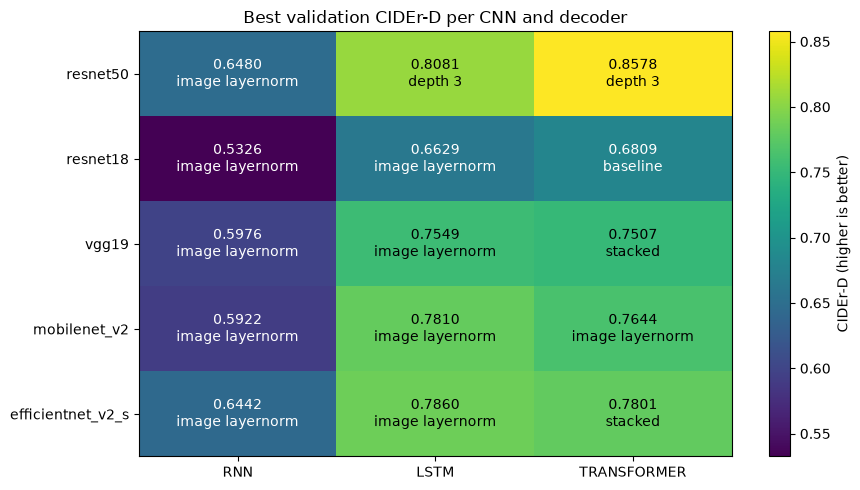

### ResNet50: compare 1, 2, 3 and 4 layers

| Decoder | Layers | Variant | Parameters | Best epoch | Val loss | BLEU-4 | CIDEr-D | Time | Status |
|---|---:|---|---:|---:|---:|---:|---:|---|---|
|lstm|1|baseline|13404436|16|2.1789|0.2433|0.7849|00:19:19|finished|
|lstm|2|stacked|15505684|11|2.1644|0.2497|0.8047|00:25:21|finished|
|lstm|3|depth_3|17606932|22|2.1223|0.2515|0.8081|00:36:41|finished|
|lstm|4|depth_4|19708180|10|2.2561|0.2399|0.7670|00:20:14|finished|
|transformer|1|baseline|14474004|6|2.2764|0.2531|0.8047|00:10:53|finished|
|transformer|2|stacked|17626388|5|2.2505|0.2493|0.8085|00:11:26|finished|
|transformer|3|depth_3|20778772|21|2.0730|0.2633|0.8578|00:40:49|finished|
|transformer|4|depth_4|23931156|16|2.1269|0.2576|0.8387|00:38:59|finished|

Blank depth-3/depth-4 scores remain pending until those experiments are trained.


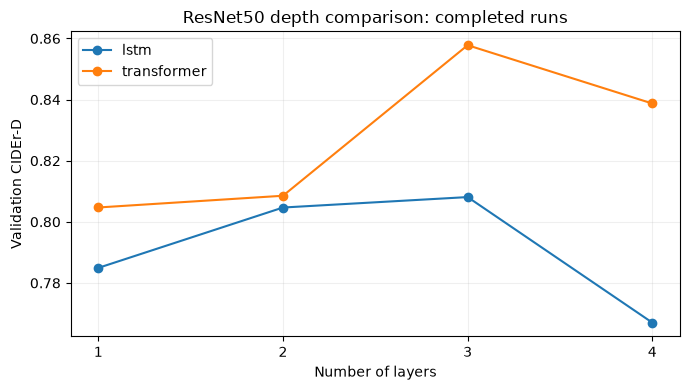

In [33]:
comparison = compare_experiments(EXPERIMENT_DIR, ALL_CONFIGS, ASSIGNMENTS)
finished_runs = [
    row for row in comparison if row["status"] == "finished" and row["cider_d"] is not None
]
decoder_names = ["rnn", "lstm", "transformer"]
best_by_decoder = {}

for decoder in decoder_names:
    candidates = [row for row in finished_runs if row["decoder"] == decoder]
    if candidates:
        best_by_decoder[decoder] = max(candidates, key=lambda row: row["cider_d"])

if best_by_decoder:
    lines = [
        "| Decoder | Encoder | Variant | Best epoch | BLEU-1 | BLEU-4 | CIDEr-D |",
        "|---|---|---|---:|---:|---:|---:|",
    ]
    for decoder, row in best_by_decoder.items():
        lines.append(
            f"|{decoder}|{row['encoder']}|{row['variant']}|{row['best_epoch']}|"
            f"{row['bleu1']:.4f}|{row['bleu4']:.4f}|{row['cider_d']:.4f}|"
        )
    display(Markdown("### Best configuration in each decoder family\n\n" + "\n".join(lines)))
    print("Selected using validation CIDEr-D only. The labeled test has not been used here.")

    # Each square shows the best completed variant for one encoder/decoder pair.
    encoder_names = list(FEATURE_DIMS)
    scores = np.full((len(encoder_names), len(decoder_names)), np.nan)
    winners = {}
    for i, encoder in enumerate(encoder_names):
        for j, decoder in enumerate(decoder_names):
            candidates = [
                row
                for row in finished_runs
                if row["encoder"] == encoder and row["decoder"] == decoder
            ]
            if candidates:
                best = max(candidates, key=lambda row: row["cider_d"])
                scores[i, j] = best["cider_d"]
                winners[i, j] = best["variant"]

    fig, ax = plt.subplots(figsize=(9, 5))
    chart = ax.imshow(np.ma.masked_invalid(scores), cmap="viridis", aspect="auto")
    midpoint = (np.nanmin(scores) + np.nanmax(scores)) / 2
    for (i, j), variant in winners.items():
        color = "white" if scores[i, j] < midpoint else "black"
        ax.text(
            j,
            i,
            f"{scores[i, j]:.4f}\n{variant.replace('_', ' ')}",
            ha="center",
            va="center",
            color=color,
            fontsize=10,
        )
    ax.set_xticks(range(len(decoder_names)), [name.upper() for name in decoder_names])
    ax.set_yticks(range(len(encoder_names)), encoder_names)
    ax.set_title("Best validation CIDEr-D per CNN and decoder")
    fig.colorbar(chart, ax=ax, label="CIDEr-D (higher is better)")
    plt.tight_layout()
    plt.savefig(EXPERIMENT_DIR / "validation_best_by_pair.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("No completed experiments to summarize yet.")


# Matched depth comparison: global ResNet50 vectors, width 512, dropout 0.3, seed 42.
depth_variants = ["baseline", "stacked", "depth_3", "depth_4"]
depth_rows = [
    row
    for row in comparison
    if row["encoder"] == "resnet50"
    and row["decoder"] in ["lstm", "transformer"]
    and row["variant"] in depth_variants
]
depth_rows.sort(key=lambda row: (row["decoder"], row["num_layers"]))
depth_lines = [
    "| Decoder | Layers | Variant | Parameters | Best epoch | Val loss | BLEU-4 | CIDEr-D | Time | Status |",
    "|---|---:|---|---:|---:|---:|---:|---:|---|---|",
]
for row in depth_rows:
    values = []
    for key in [
        "decoder",
        "num_layers",
        "variant",
        "trainable_parameters",
        "best_epoch",
        "val_loss",
        "bleu4",
        "cider_d",
        "training_time",
        "status",
    ]:
        value = row[key]
        values.append(
            "" if value is None else f"{value:.4f}" if isinstance(value, float) else str(value)
        )
    depth_lines.append("|" + "|".join(values) + "|")
display(Markdown("### ResNet50: compare 1, 2, 3 and 4 layers\n\n" + "\n".join(depth_lines)))
print("Blank depth-3/depth-4 scores remain pending until those experiments are trained.")

fig, ax = plt.subplots(figsize=(7, 4))
for decoder in ["lstm", "transformer"]:
    completed = [
        row for row in depth_rows if row["decoder"] == decoder and row["status"] == "finished"
    ]
    ax.plot(
        [row["num_layers"] for row in completed],
        [row["cider_d"] for row in completed],
        marker="o",
        label=decoder,
    )
ax.set(
    xlabel="Number of layers",
    ylabel="Validation CIDEr-D",
    title="ResNet50 depth comparison: completed runs",
)
ax.set_xticks([1, 2, 3, 4])
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(EXPERIMENT_DIR / "resnet50_depth_comparison.png", dpi=150, bbox_inches="tight")
plt.show()


## B9. Learning curves for the validation finalists

The default plots show the best completed RNN, LSTM and Transformer, selected using validation CIDEr-D. Each red point marks the checkpoint saved as best. Training continues for three non-improving epochs after that point. Change `PLOT_RUN_NAMES` to inspect any other completed model.

These curves use the saved histories. Displaying them does not train a model or evaluate the test set.


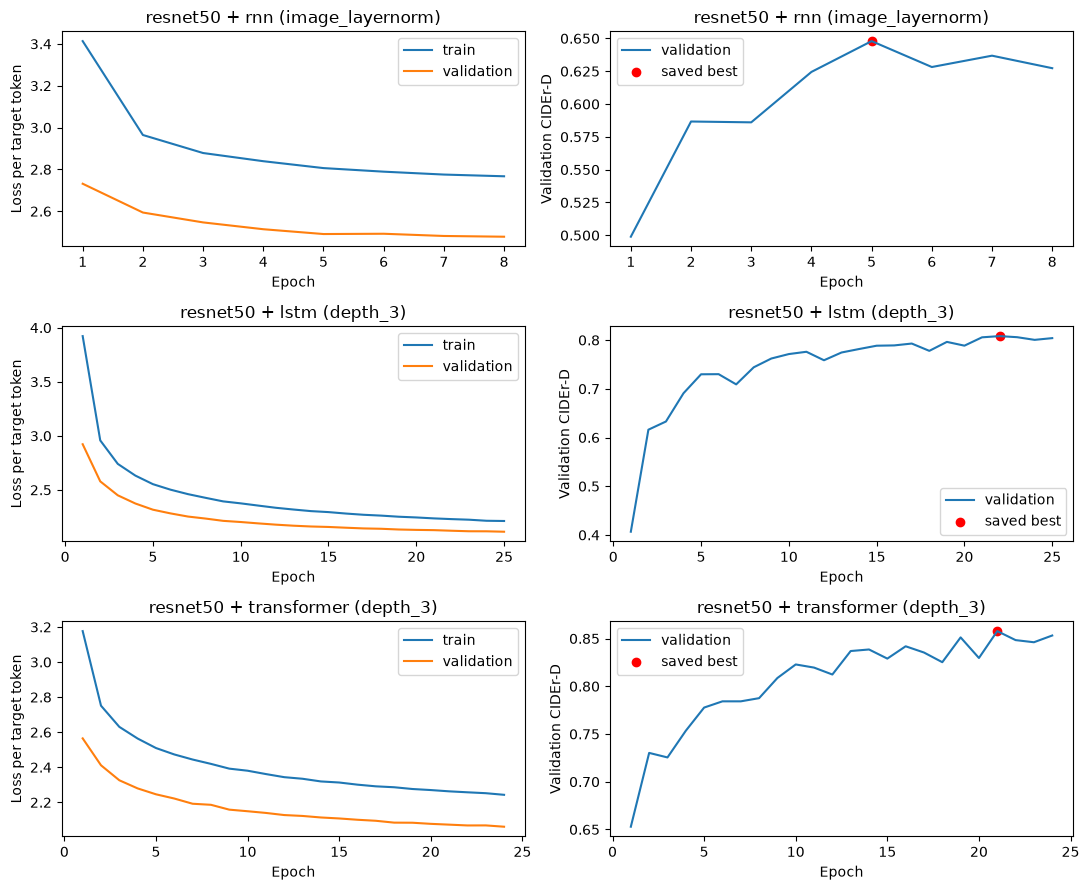

In [34]:
# Change this list to inspect any other completed runs.
PLOT_RUN_NAMES = [row["run"] for row in best_by_decoder.values()]

if PLOT_RUN_NAMES:
    fig, axes = plt.subplots(
        len(PLOT_RUN_NAMES), 2, figsize=(11, 3 * len(PLOT_RUN_NAMES)), squeeze=False
    )
    for index, run_name in enumerate(PLOT_RUN_NAMES):
        folder = EXPERIMENT_DIR / run_name
        history = json.loads((folder / "history.json").read_text(encoding="utf-8"))
        summary = json.loads((folder / "summary.json").read_text(encoding="utf-8"))
        epochs = [row["epoch"] for row in history]
        title = f"{summary['encoder']} + {summary['decoder']} ({summary['variant']})"
        axes[index, 0].plot(epochs, [row["train_loss"] for row in history], label="train")
        axes[index, 0].plot(epochs, [row["val_loss"] for row in history], label="validation")
        axes[index, 0].set(title=title, xlabel="Epoch", ylabel="Loss per target token")
        axes[index, 0].legend()
        axes[index, 1].plot(epochs, [row["cider_d"] for row in history], label="validation")
        axes[index, 1].scatter(
            summary["best_epoch"], summary["cider_d"], color="red", label="saved best"
        )
        axes[index, 1].set(title=title, xlabel="Epoch", ylabel="Validation CIDEr-D")
        axes[index, 1].legend()
    plt.tight_layout()
    plt.savefig(EXPERIMENT_DIR / "finalist_learning_curves.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("Run the combined comparison cell before plotting learning curves.")


## B10. Final labeled test — after model selection

Keep this off during development. Select the architecture/checkpoint using validation, freeze that decision, then set `RUN_FINAL_TEST=True` to evaluate `best.pt` on all 5,000 labeled test photos. This function never participates in training or early stopping. Do not use repeated test scores to tune the model.

In [35]:
# Choose finalists using validation only, after collecting both halves.
FINAL_RUN_NAME = None
if RUN_FINAL_TEST:
    assert FINAL_RUN_NAME is not None, "Set a selected run name before evaluating test."
    assert FINAL_RUN_NAME in ASSIGNMENTS, "Choose a run from the current experiment plan."
    final_test_scores = evaluate_final_test(
        data, EXPERIMENT_DIR / FINAL_RUN_NAME, evaluator, device
    )
    print("Final labeled test:", final_test_scores)
else:
    print("Final test evaluation is off. It is never used to choose a variant.")


Final test evaluation is off. It is never used to choose a variant.


## B11. Verification report

This report lists the checks actually executed on this version. Small fixed-data diagnostics and tiny interruption tests are not full training experiments. The previous completed training results are preserved separately.

In [36]:
for filename, expected_id in [
    ("fifty_experiment_verification.json", IMPLEMENTATION_ID),
    ("transformer_verification.json", TRANSFORMER_IMPLEMENTATION_ID),
]:
    report_path = PROJECT_DIR / "captioning_checks" / filename
    if not report_path.exists():
        public_name = "verification_report.json" if filename.startswith("fifty") else filename
        report_path = PROJECT_DIR / public_name
    if report_path.exists():
        verification = json.loads(report_path.read_text(encoding="utf-8"))
        assert (
            verification["implementation"] == expected_id
        ), "Verification belongs to another model version."
        print(
            filename,
            "| passed:",
            verification["passed"],
            "| configurations checked:",
            len(verification["checks"]),
        )
        print("Checked device:", verification["device"]["name"])
        print("These are development checks; training performs preflight on the current device.")
    else:
        print("No saved development report:", filename)

collection_path = PROJECT_DIR / "captioning_checks" / "collected_75_results.json"
if collection_path.exists():
    collection = json.loads(collection_path.read_text(encoding="utf-8"))
    print("Original 75-run collection audit:", collection["completed"])
    print("Verified files in B's archive:", collection["archive_files_verified"])
    print("All code/data/config/metric identities match:", collection["all_75_identities_match"])
    print("Existing A results unchanged:", collection["existing_50_A_results_unchanged"])

depth_report_path = PROJECT_DIR / "captioning_checks" / "depth_verification.json"
if not depth_report_path.exists():
    depth_report_path = PROJECT_DIR / "depth_verification.json"
if depth_report_path.exists():
    depth_report = json.loads(depth_report_path.read_text(encoding="utf-8"))
    assert depth_report["implementation_by_decoder"] == {
        "lstm": IMPLEMENTATION_ID,
        "transformer": TRANSFORMER_IMPLEMENTATION_ID,
    }
    assert [row["config"] for row in depth_report["checks"]] == [
        config for config in ALL_CONFIGS if config["variant"] in DEPTH_VARIANTS
    ]
    print(
        "Depth development checks passed:",
        depth_report["passed"],
        "| configurations:",
        len(depth_report["checks"]),
    )
    print("Checked device:", depth_report["device"]["name"])
    print(
        "Full depth experiments trained during these checks:",
        depth_report["full_depth_experiments_trained"],
    )
else:
    print("No saved depth development report; every new run still performs preflight.")


fifty_experiment_verification.json | passed: True | configurations checked: 50
Checked device: NVIDIA GeForce RTX 4060 Laptop GPU
These are development checks; training performs preflight on the current device.
transformer_verification.json | passed: True | configurations checked: 25
Checked device: NVIDIA GeForce RTX 4060 Laptop GPU
These are development checks; training performs preflight on the current device.
Original 75-run collection audit: 75
Verified files in B's archive: 557
All code/data/config/metric identities match: True
Existing A results unchanged: True
Depth development checks passed: True | configurations: 4
Checked device: NVIDIA GeForce RTX 4060 Laptop GPU
Full depth experiments trained during these checks: 0


## C. Transfer data and completed results

The original B archive has already been imported on A. All 75 existing runs remain available. Importing the same archive again checks equality and reuses identical files; conflicting folders are never overwritten.

`EXPORT_SCOPE="selected"` exports completed runs selected by both `TRAIN_DECODERS` and `TRAIN_VARIANTS`. The default selection is the four new depth runs. `EXPORT_SCOPE="all_assigned"` includes all A's 54 assigned configurations (or B's original 25). Only completed runs are exported; check the printed count. Selected archive names include decoder and variant names. Use a new filename for another export.

For B's original selection in this updated notebook, use `LAPTOP_ID="B"`, `TRAIN_DECODERS=["rnn", "lstm"]` and `TRAIN_VARIANTS=None`. The existing cache and data archive remain valid. The depth experiments reuse global ResNet50 vectors and need no new CNN extraction.

All transfer switches are off by default. To receive another compatible archive, set `RECEIVED_RESULTS_ARCHIVE` to its actual path and enable `IMPORT_RESULTS` for that operation. Then rerun B8 and B9. Keep configurations, histories, predictions and full checkpoints together with weights.


In [37]:
CREATE_TRAINING_ARCHIVE = False
EXPORT_RESULTS = False
IMPORT_RESULTS = False
EXPORT_SCOPE = "selected"  # Current decoder/variant selection, or "all_assigned".
TRAINING_ARCHIVE = TRANSFER_DIR / "caption_training_data.zip"
decoder_label = "_".join(TRAIN_DECODERS)
variant_label = "all_variants" if TRAIN_VARIANTS is None else "_".join(TRAIN_VARIANTS)
archive_label = f"{decoder_label}_{variant_label}" if EXPORT_SCOPE == "selected" else "all_assigned"
MY_RESULTS_ARCHIVE = TRANSFER_DIR / f"caption_results_{LAPTOP_ID}_{archive_label}.zip"
RECEIVED_RESULTS_ARCHIVE = TRANSFER_DIR / "caption_results_B.zip"

if CREATE_TRAINING_ARCHIVE:
    build_training_bundle(data, TRAINING_ARCHIVE)

if EXPORT_RESULTS:
    if EXPORT_SCOPE not in ["selected", "all_assigned"]:
        raise ValueError("Choose EXPORT_SCOPE='selected' or 'all_assigned'.")
    export_configs = configs if EXPORT_SCOPE == "selected" else MY_CONFIGS
    my_run_names = [config["run_name"] for config in export_configs]
    exported = export_result_bundle(EXPERIMENT_DIR, my_run_names, MY_RESULTS_ARCHIVE)
    print(f"Completed runs in this archive: {len(exported['completed'])}/{len(my_run_names)}")

if IMPORT_RESULTS:
    expected_identities = {
        config["run_name"]: experiment_identity(data, config, evaluator) for config in ALL_CONFIGS
    }
    imported = import_result_bundle(RECEIVED_RESULTS_ARCHIVE, EXPERIMENT_DIR, expected_identities)
    comparison = compare_experiments(EXPERIMENT_DIR, ALL_CONFIGS, ASSIGNMENTS)
